# Formula 1 Podium Prediction

**Goal:** for every driver in a race, predict whether they will finish in the top three
(on the **podium**), using only what is known **after qualifying and before the race
starts**.

- **One row = one driver in one race.**
- **Target:** `podium` = 1 when the driver's final classified position (`positionOrder`)
  is 1, 2 or 3; otherwise 0.
- **Cut-off:** anything that is only known once the race has started (finishing
  position, points, laps, pit stops, retirement reason) is never used as an input.

### Notebook map
1. [Load and preserve the data](#load-data)
2. [Explore and check the original data](#raw-eda)
3. [Clean the data](#clean-data)
4. [Compare the data before and after cleaning](#post-eda)
5. [Data-engineering questions](#analytical-base)
6. [Feature selection and engineering](#feature-selection)
7. [Predictive modeling](#modeling)
8. [Feature-group ablation](#ablation)
9. [Explaining the models (XAI)](#xai)

Each section builds on the one before it. Where a step reuses a result from an earlier
step (for example, the best settings found on the validation seasons), the markdown
says so explicitly.

> **How to run:** start from a fresh kernel and choose *Run All*. Keep the Kaggle
> dataset attached (a local folder with the original CSV files also works). Internet
> access is needed once, to install the explanation libraries in Section 9 if they are
> missing. The original CSV files are never overwritten.

### Reading the tables
All tables share one style: dark headers and alternating row colours. In before/after
tables, old values have a grey background and new values a light green one. In check
tables, a count is green when it is zero (nothing wrong) and red when something was
flagged. Missing values are shown as a dash (—). These are display choices only; the
stored data is not changed.

In [58]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)

try:
    import missingno as msno
except ImportError:
    msno = None

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)

BASE_PATH = Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/')
# For a different local folder, edit BASE_PATH above.
if not BASE_PATH.exists():
    for candidate in [Path('project_sources'), Path('../project_sources'), Path('.')]:
        if candidate.exists() and (
            (candidate / 'results.csv').exists()
            or list(candidate.glob('*-results.csv'))
        ):
            BASE_PATH = candidate
            break

# Only this literal placeholder is confirmed in the supplied CSVs.
# Additional tokens should be added only after checking their meaning.
SENTINELS = [r'\N']
sentinels = SENTINELS
CORE_NAMES = ['races', 'results', 'circuits', 'drivers',
              'constructors', 'status', 'qualifying',
              'constructor_standings', 'driver_standings']
ALL_NAMES = CORE_NAMES + ['seasons', 'constructor_results', 'lap_times',
    'pit_stops', 'sprint_results']

def plot_missingness_matrix(frame, title):
    # Literal sentinel strings count as present here, deliberately.
    if msno is not None:
        ax = msno.matrix(frame, figsize=(14, 4), sparkline=False, fontsize=9)
        ax.set_title(title, pad=18)
    else:
        # Equivalent presence/null mask when missingno is unavailable locally.
        from matplotlib.colors import ListedColormap
        fig, ax = plt.subplots(figsize=(14, 4))
        ax.imshow(frame.notna().to_numpy(dtype=np.uint8), aspect='auto',
                  interpolation='nearest', cmap=ListedColormap(['white', 'steelblue']),
                  vmin=0, vmax=1)
        ax.set_xticks(np.arange(len(frame.columns)))
        ax.set_xticklabels(frame.columns, rotation=60, ha='right')
        ax.set_ylabel('Record order')
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


In [59]:
# Shared table theme: centered headers, row labels, and values.
import pandas as pd
import numpy as np
from numbers import Integral, Real
import re

try:
    from IPython.display import display as _display, HTML
except ImportError:
    class HTML:
        def __init__(self, data):
            self.data = data

        def _repr_html_(self):
            return self.data

    def _display(value):
        print(value)


TABLE_COLORS = {
    'header': '#18344d',
    'text': '#23384b',
    'border': '#e2e8f0',
    'stripe': '#f6f9fc',
    'old': '#f1f5f9',
    'new': '#eaf7f3',
    'accent': '#087f68',
    'flag': '#a32929',
    'flag_bg': '#fff0ef'
}


def _format_table_value(value):
    if pd.isna(value):
        return '—'

    if isinstance(value, (bool, np.bool_)):
        return 'Yes' if value else 'No'

    if isinstance(value, Integral):
        return f'{value:,}'

    if isinstance(value, Real):
        if not np.isfinite(value):
            return str(value)

        return f'{value:,.3f}'.rstrip('0').rstrip('.')

    if isinstance(value, pd.Timestamp):
        return value.strftime('%Y-%m-%d')

    return str(value)


def _table_stage(column):
    labels = column if isinstance(column, tuple) else (column,)

    words = re.findall(
        r'[a-z]+',
        ' '.join(map(str, labels)).lower()
    )

    if 'old' in words or 'before' in words:
        return 'old'

    if 'new' in words or 'after' in words:
        return 'new'

    return ''


def _render_table_html(frame, wrap_text=False):
    # Styling changes presentation only.
    colors = TABLE_COLORS

    classes = pd.DataFrame(
        '',
        index=frame.index,
        columns=frame.columns
    )

    audit_labels = {
        'missing pk rows',
        'duplicate pk extras',
        'missing fk rows',
        'unmatched fk rows',
        'invalid rows',
        'exact extra rows'
    }

    for column in frame.columns:
        stage = _table_stage(column)

        if stage:
            classes[column] = f'{stage}-column'

        if str(column).lower() in audit_labels:
            classes[column] = frame[column].map(
                lambda value:
                    'audit-pass'
                    if pd.notna(value) and value == 0
                    else 'audit-flag'
            )

    styles = [
        {
            'selector': '',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                (
                    'font-family',
                    'Inter, -apple-system, BlinkMacSystemFont, '
                    'Segoe UI, sans-serif'
                ),
                ('font-size', '13px'),
                ('color', colors['text']),
                ('width', '100%' if wrap_text else 'max-content'),
                ('min-width', '100%'),
                ('max-width', '100%' if wrap_text else 'none'),
                ('table-layout', 'fixed' if wrap_text else 'auto'),
                ('border', f"1px solid {colors['border']}"),
                ('border-radius', '10px'),
                ('overflow', 'visible'),
                ('background-color', '#ffffff')
            ]
        },
        {
            'selector': 'thead th',
            'props': [
                ('background-color', colors['header']),
                ('color', '#ffffff'),
                ('padding', '11px 14px'),
                ('font-weight', '600'),
                ('text-align', 'center'),
                ('vertical-align', 'middle'),
                ('border-bottom', '1px solid #34516a'),
                ('line-height', '1.4'),
                ('white-space', 'normal !important' if wrap_text else 'nowrap !important'),
                ('word-break', 'normal'),
                ('overflow-wrap', 'normal')
            ]
        },
        {
            'selector': 'tbody td',
            'props': [
                ('padding', '10px 14px'),
                ('border-bottom', f"1px solid {colors['border']}"),
                ('text-align', 'center'),
                ('vertical-align', 'middle'),
                ('font-variant-numeric', 'tabular-nums'),
                ('white-space', 'nowrap')
            ]
        },
        {
            'selector': 'tbody th',
            'props': [
                ('padding', '10px 14px'),
                ('background-color', '#f1f5f9'),
                ('color', '#41566b'),
                ('text-align', 'center'),
                ('vertical-align', 'middle'),
                ('font-weight', '500'),
                ('border-bottom', f"1px solid {colors['border']}"),
                ('white-space', 'nowrap')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', colors['stripe'])
            ]
        },
        {
            'selector': 'tbody td.old-column',
            'props': [
                ('background-color', colors['old']),
                ('color', '#526477')
            ]
        },
        {
            'selector': 'tbody td.new-column',
            'props': [
                ('background-color', colors['new']),
                ('color', colors['accent']),
                ('font-weight', '600')
            ]
        },
        {
            'selector': 'tbody td.audit-pass',
            'props': [
                ('color', colors['accent']),
                ('background-color', '#edf8f2'),
                ('font-weight', '600')
            ]
        },
        {
            'selector': 'tbody td.audit-flag',
            'props': [
                ('color', colors['flag']),
                ('background-color', colors['flag_bg']),
                ('font-weight', '600')
            ]
        },
        {
            'selector': 'tbody tr:hover td',
            'props': [
                ('background-color', '#e7f0f7')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'bottom'),
                ('padding', '9px 2px'),
                ('text-align', 'left'),
                ('color', '#64748b'),
                ('font-size', '11px')
            ]
        }
    ]

    # Inline layout overrides notebook CSS that can squeeze long headers.
    table_layout = (
        'display:table!important;table-layout:fixed!important;width:100%!important;'
        'max-width:100%!important;'
        if wrap_text else
        'display:table!important;table-layout:auto!important;width:max-content!important;'
        'min-width:100%;max-width:none!important;'
    )

    styled = (
        frame.style
        .format(
            _format_table_value,
            na_rep='—',
            escape='html'
        )
        .format_index(escape='html', axis=0)
        .format_index(escape='html', axis=1)
        .set_table_attributes(f'style="{table_layout}"')
        .set_td_classes(classes)
        .set_table_styles(styles)
        .set_caption(
            f'{len(frame):,} rows · {len(frame.columns):,} columns'
        )
    )

    # Hide default row numbers, retaining meaningful row labels.
    if isinstance(frame.index, pd.RangeIndex) and frame.index.name is None:
        styled = styled.hide(axis='index')

    # Center all data cells consistently.
    styled = styled.set_properties(
        **{
            'text-align': 'center',
            'vertical-align': 'middle'
        }
    )

    return (
        '<div style="display:block;width:100%;max-width:100%;min-width:0;overflow-x:auto;margin:10px 0 22px;">'
        + styled.to_html()
        + '</div>'
    )


def display(value):
    if isinstance(value, pd.Series):
        value = value.to_frame(
            name=value.name if value.name is not None else 'Value'
        )

    if isinstance(value, pd.DataFrame):
        rendered = HTML(_render_table_html(value))
        rendered._table_frame = value
        _display(rendered)
    else:
        _display(value)

<a id="load-data"></a>
## 1. Load and preserve the data

The dataset has **14 CSV files**. All of them get a quick structural check. The nine
files the models need (races, results, circuits, drivers, constructors, status,
qualifying, driver standings and constructor standings) also get a detailed check and
cleaning. The other five (lap times, pit stops, sprint results, seasons and
constructor results) are kept exactly as loaded.

The championship standings record each driver's and team's points **after** each race.
That would be future information for the same race, so Section 6 shifts them to "points
before this race" before they are used.

In these files, a missing value is written as the text `\N`. It is kept as-is while
loading, so that the checks can count it. A fingerprint (hash) of every file is also
stored to prove the original files are never changed.

In [60]:
def resolve_csv(name):
    direct = BASE_PATH / f'{name}.csv'
    matches = [direct] if direct.exists() else sorted(BASE_PATH.glob(f'*-{name}.csv'))
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected one CSV for {name} in {BASE_PATH}; found {matches}')
    return matches[0]

csv_paths = {name: resolve_csv(name) for name in ALL_NAMES}
csv_hashes_before = {
    name: hashlib.sha256(path.read_bytes()).hexdigest()
    for name, path in csv_paths.items()
}
source_tables = {name: pd.read_csv(path) for name, path in csv_paths.items()}
tables = {name: source_tables[name].copy(deep=True) for name in CORE_NAMES}
(races, results, circuits, drivers, constructors, status, qualifying,
 constructor_standings, driver_standings) = (
    tables[name] for name in CORE_NAMES
)
display(pd.DataFrame({name: {'Rows': len(frame), 'Columns': frame.shape[1],
    'Detailed cleaning scope': name in CORE_NAMES}
    for name, frame in source_tables.items()}).T)


,Rows,Columns,Detailed cleaning scope
races,"1,125",18,Yes
results,"26,759",18,Yes
circuits,77,9,Yes
drivers,861,9,Yes
constructors,212,5,Yes
status,139,2,Yes
qualifying,"10,494",9,Yes
constructor_standings,"13,391",7,Yes
driver_standings,"34,863",7,Yes
seasons,75,2,No


In [61]:
# Explain the detailed cleaning scope and the leakage judgement using the shared table theme.
scope_justification = pd.DataFrame(
    [
        (
            'results',
            'Yes',
            'Provides the driver–race records, actual starting grid, constructor '
            'assignment and positionOrder, from which the podium target is '
            'constructed. It also supplies outcomes for all three descriptive '
            'questions. Repeated driver–race combinations must be resolved to '
            'establish the required modeling grain. Current-race finishing '
            'positions, points, laps and status remain excluded from predictors.',
            'MIXED. Safe: grid (fixed before the start; 0 = pit-lane start). '
            'Leaky, never used as inputs: position, positionText, positionOrder, '
            'points, laps, time, milliseconds, fastestLap, fastestLapTime, '
            'fastestLapSpeed, rank and statusId, which are all only known once the '
            'race has run. Results of EARLIER races are used only through the '
            'past-only podium rates (Section 6.2), which are calculated from earlier '
            'dates before the current race is added.'
        ),
        (
            'races',
            'Yes',
            'Links each result to its circuit, season, round and date. These '
            'fields support chronological ordering, era comparisons, historical '
            'feature construction and time-based splitting. Its calendar fields '
            'also require appropriate date/time interpretation.',
            'SAFE. Season, round, date and circuit are set in the calendar long '
            'before the race. They are used to order races in time, to build '
            'past-only features and to split the seasons, not as direct inputs.'
        ),
        (
            'circuits',
            'Yes',
            'Supplies circuit identity, names and countries. It is needed to '
            'compare front-row conversion across circuits and determine whether '
            'a race took place in a driver’s home country.',
            'SAFE. Fixed facts about the track. The circuit features (Section 6.4) '
            'only use results from earlier races at that circuit.'
        ),
        (
            'drivers',
            'Yes',
            'Supplies driver identity and nationality for the home-race analysis. '
            'Nationality labels require consistent formatting and an explicit '
            'country mapping because labels such as “British” and “UK” cannot '
            'be compared directly.',
            'SAFE. Fixed facts about the driver (name, nationality, date of birth). '
            'Driver strength enters the models only through past-only features.'
        ),
        (
            'constructors',
            'Yes',
            'Identifies the teams used in the mechanical-retirement comparison '
            'and supplies readable labels for constructor-level summaries. '
            'Constructor identity is turned into a past-only podium rate for the '
            'models. Distinct constructor IDs are preserved rather than '
            'automatically merging teams across historical renames.',
            'SAFE. Fixed facts about the team, and the team entry for a race is '
            'known before the start. Team strength enters the models only through '
            'past-only features.'
        ),
        (
            'status',
            'Yes',
            'Explains how each recorded race entry ended. It is essential for '
            'distinguishing mechanical failures from accidents, completed races '
            'and non-starting entries. This is a retrospective analysis input, '
            'not a current-race predictor.',
            'LEAKY. Says how the race ended (finished, engine, accident...), which '
            'is only known after the race. Used only for Question 3 and the data '
            'audit; never a model input.'
        ),
        (
            'qualifying',
            'Yes',
            'Supports qualifying-coverage analysis and comparison of qualifying '
            'position with the actual starting grid. Its recorded times require '
            'conversion into numeric durations. In this snapshot, coverage '
            'spans 1994–2024 and is incomplete; missing Q2/Q3 values can reflect '
            'elimination or historical formats rather than errors. Qualifying '
            'position and the Q1 gap to the fastest car are model inputs.',
            'SAFE. Qualifying takes place before the race, so it is inside the '
            'prediction cutoff. qualifying_position and the Q1 gap are used; Q2/Q3 '
            'are not, because most drivers have no Q2/Q3 time.'
        ),
        (
            'seasons',
            'No',
            'Contains only year and url. The current analyses already obtain '
            'season information from races, so joining it would add no '
            'independent analytical variable. It remains part of the structural '
            'audit as the parent reference for race years.',
            'SAFE. Only the year and a web link; not used as an input.'
        ),
        (
            'constructor_results',
            'No',
            'Contains constructor-level race points and a status field, rather '
            'than the required driver-level prediction unit. The current '
            'questions obtain their necessary constructor-linked outcomes from '
            'results. Prior-race constructor summaries could be useful later, '
            'but would require chronological alignment and a justified '
            'aggregation rule.',
            'LEAKY for the same race: the points a team scored in that race. Only '
            'values from earlier races could be used; not used as an input.'
        ),
        (
            'constructor_standings',
            'Yes',
            'Stores cumulative constructor championship points after each race. '
            'Included in detailed EDA, numeric typing and key checks. Section 6 '
            'retrieves points from the previous round in the same season, '
            'using the current entry’s constructor, to avoid current-race leakage. '
            'Constructor championship points are unavailable before 1958.',
            'LEAKY AS STORED: each row is the total AFTER that race, so it already '
            'includes the race being predicted. MADE SAFE by taking the standings '
            'after the PREVIOUS round of the same season (Section 6.3), then '
            'turning them into a share of the leader’s points.'
        ),
        (
            'driver_standings',
            'Yes',
            'Contains post-race cumulative driver points, rank and wins. '
            'Included in detailed EDA, numeric typing and key checks. Section 6 '
            'retrieves season points from the previous round for the same driver. '
            'Season resets, missing history and join grain are checked explicitly; '
            'raw current-race standings are never predictors.',
            'LEAKY AS STORED: points, position and wins after the race already '
            'include its result. MADE SAFE the same way: previous round of the same '
            'season only (Section 6.3). Same-race position and wins are never used.'
        ),
        (
            'lap_times',
            'No',
            'Records individual laps from the main race, which occur after the '
            'prediction cutoff. The current workflow does not construct '
            'historical lap-based features. Its finer grain would also multiply '
            'driver–race rows if joined directly, so future use would require '
            'aggregation using completed earlier races only.',
            'LEAKY. Every lap happens during the race itself; not used as an '
            'input.'
        ),
        (
            'pit_stops',
            'No',
            'Records events during the main race and is therefore unavailable '
            'for predicting that same race. Historical pit-stop summaries are '
            'possible, but are not currently implemented and would require '
            'prior-race filtering and aggregation before joining.',
            'LEAKY. Pit stops happen during the race; not used as an input.'
        ),
        (
            'sprint_results',
            'No',
            'Covers only 18 sprint events in the supplied snapshot, across '
            '2021–2024. Sprint outcomes can be known before the main race, so '
            'this table is not automatically a leakage source. It is currently '
            'deferred because using it requires explicit treatment of changing '
            'sprint formats, event timing and the absence of sprints on most '
            'weekends.',
            'JUDGEMENT CALL. The sprint runs before the main race, so it is '
            'technically pre-race information. It is still left out: (1) it exists '
            'for only 18 weekends, so a sprint feature would be missing for almost '
            'every row; (2) in 2021–2022 the sprint result set the Sunday grid, so '
            'its effect is already captured by the grid feature; (3) the points '
            'share uses the previous round, so sprint points from the same weekend '
            'are not included either.'
        )
    ],
    columns=['Table', 'Detailed cleaning scope', 'Justification',
             'Leakage judgement (pre-race cutoff)']
)

print('DETAILED CLEANING SCOPE AND LEAKAGE JUDGEMENT')
print(
    'All 14 tables receive primary-key and foreign-key checks. '
    '“No” means outside the current detailed cleaning scope, '
    'not permanently excluded from the project. '
    'Leakage judgement: SAFE = known before the race starts; '
    'LEAKY = only known after the race starts (never a model input); '
    'MIXED / LEAKY AS STORED = only the safe part, or a past-only version, is used.'
)

# Reuse the shared theme and override wrapping only within this table.
scope_html = _render_table_html(scope_justification, wrap_text=True)

display(HTML(
    """
    <div id="scope-justification">
        <style>
            #scope-justification table {
                table-layout: fixed;
                width: 100%;
            }

            #scope-justification tbody td {
                white-space: normal !important;
                overflow-wrap: anywhere;
                line-height: 1.6;
                vertical-align: middle;
            }

            #scope-justification th.col0,
            #scope-justification td.col0 {
                width: 14%;
            }

            #scope-justification th.col1,
            #scope-justification td.col1 {
                width: 10%;
            }

            #scope-justification th.col2,
            #scope-justification td.col2 {
                width: 40%;
            }

            #scope-justification th.col3,
            #scope-justification td.col3 {
                width: 36%;
            }
        </style>
    """
    + scope_html
    + '</div>'
))

print(
    'Scope maintenance: These exclusions describe the current implementation, '
    'not permanent restrictions. Before introducing a deferred table, extend '
    'its detailed cleaning, validate information availability at the prediction '
    'cutoff, and confirm that its join preserves exactly one row per '
    '(raceId, driverId).'
)

DETAILED CLEANING SCOPE AND LEAKAGE JUDGEMENT
All 14 tables receive primary-key and foreign-key checks. “No” means outside the current detailed cleaning scope, not permanently excluded from the project. Leakage judgement: SAFE = known before the race starts; LEAKY = only known after the race starts (never a model input); MIXED / LEAKY AS STORED = only the safe part, or a past-only version, is used.


Table,Detailed cleaning scope,Justification,Leakage judgement (pre-race cutoff)
results,Yes,"Provides the driver–race records, actual starting grid, constructor assignment and positionOrder, from which the podium target is constructed. It also supplies outcomes for all three descriptive questions. Repeated driver–race combinations must be resolved to establish the required modeling grain. Current-race finishing positions, points, laps and status remain excluded from predictors.","MIXED. Safe: grid (fixed before the start; 0 = pit-lane start). Leaky, never used as inputs: position, positionText, positionOrder, points, laps, time, milliseconds, fastestLap, fastestLapTime, fastestLapSpeed, rank and statusId, which are all only known once the race has run. Results of EARLIER races are used only through the past-only podium rates (Section 6.2), which are calculated from earlier dates before the current race is added."
races,Yes,"Links each result to its circuit, season, round and date. These fields support chronological ordering, era comparisons, historical feature construction and time-based splitting. Its calendar fields also require appropriate date/time interpretation.","SAFE. Season, round, date and circuit are set in the calendar long before the race. They are used to order races in time, to build past-only features and to split the seasons, not as direct inputs."
circuits,Yes,"Supplies circuit identity, names and countries. It is needed to compare front-row conversion across circuits and determine whether a race took place in a driver’s home country.",SAFE. Fixed facts about the track. The circuit features (Section 6.4) only use results from earlier races at that circuit.
drivers,Yes,Supplies driver identity and nationality for the home-race analysis. Nationality labels require consistent formatting and an explicit country mapping because labels such as “British” and “UK” cannot be compared directly.,"SAFE. Fixed facts about the driver (name, nationality, date of birth). Driver strength enters the models only through past-only features."
constructors,Yes,Identifies the teams used in the mechanical-retirement comparison and supplies readable labels for constructor-level summaries. Constructor identity is turned into a past-only podium rate for the models. Distinct constructor IDs are preserved rather than automatically merging teams across historical renames.,"SAFE. Fixed facts about the team, and the team entry for a race is known before the start. Team strength enters the models only through past-only features."
status,Yes,"Explains how each recorded race entry ended. It is essential for distinguishing mechanical failures from accidents, completed races and non-starting entries. This is a retrospective analysis input, not a current-race predictor.","LEAKY. Says how the race ended (finished, engine, accident...), which is only known after the race. Used only for Question 3 and the data audit; never a model input."
qualifying,Yes,"Supports qualifying-coverage analysis and comparison of qualifying position with the actual starting grid. Its recorded times require conversion into numeric durations. In this snapshot, coverage spans 1994–2024 and is incomplete; missing Q2/Q3 values can reflect elimination or historical formats rather than errors. Qualifying position and the Q1 gap to the fastest car are model inputs.","SAFE. Qualifying takes place before the race, so it is inside the prediction cutoff. qualifying_position and the Q1 gap are used; Q2/Q3 are not, because most drivers have no Q2/Q3 time."
seasons,No,"Contains only year and url. The current analyses already obtain season information from races, so joining it would add no independent analytical variable. It remains part of the structural audit as the parent reference for race years.",SAFE. Only the year and a web link; not used as an input.
constructor_results,No,"Contains constructor-level race points and a status field, rather than the required driver-level predicti

Scope maintenance: These exclusions describe the current implementation, not permanent restrictions. Before introducing a deferred table, extend its detailed cleaning, validate information availability at the prediction cutoff, and confirm that its join preserves exactly one row per (raceId, driverId).


<a id="raw-eda"></a>
## 2. Explore and check the original data

### 2.1 Look at each column according to what it means
Not every number is a measurement. IDs and car numbers are labels, so their average
means nothing; they are checked by counting. Finishing positions and grid slots are
ranks; points and laps are amounts. Points and race lengths also changed over the
decades, so they are summarised per period rather than with one all-time average.

Nothing is removed at this stage. The `\N` markers are counted but not replaced yet,
and any temporary copy used for a check leaves the stored data unchanged.

The standings checks also look at which races they cover, how points and wins are
spread, and how often each championship position appears. Because scoring rules and
season lengths differ between eras, all-time points totals are not a fair measure of
strength.

In [62]:
# Use preserved source tables; do not overwrite the complete 14-table inventory.
# Keep all columns during initial exploration.
tables = {
    name: table.copy()
    for name, table in source_tables.items()
    if name in CORE_NAMES
}

races = tables['races']
results = tables['results']
circuits = tables['circuits']
drivers = tables['drivers']
constructors = tables['constructors']
status = tables['status']
qualifying = tables['qualifying']
constructor_standings = tables['constructor_standings']
driver_standings = tables['driver_standings']


# 1. Table dimensions
overview = pd.DataFrame({
    name: {
        'Rows': len(table),
        'Columns': len(table.columns)
    }
    for name, table in tables.items()
}).T

print('TABLE DIMENSIONS')
display(overview)
print()


# 2. Original data types and non-null counts
# Sentinel strings still count as non-null.
for name, table in tables.items():
    print(name)

    display(pd.DataFrame({
        'Data type': table.dtypes.astype(str),
        'Actual non-null': table.notna().sum(),
        'Actual nulls': table.isna().sum()
    }))

    print()


# 3. Missingness across ALL original columns
# Detect confirmed placeholders without replacing them.
sentinels = [r'\N']

for name, table in tables.items():
    actual_missing = table.isna()
    sentinel_missing = table.isin(sentinels)
    total_missing = actual_missing | sentinel_missing

    missing_summary = pd.DataFrame({
        'Actual Nulls': actual_missing.sum(),
        'Sentinel Count': sentinel_missing.sum(),
        'Missing Count': total_missing.sum(),
        'Missing Percentage': total_missing.mean() * 100
    })

    missing_summary = missing_summary[
        missing_summary['Missing Count'] > 0
    ].sort_values('Missing Percentage', ascending=False)

    print(f'MISSINGNESS: {name}')

    if missing_summary.empty:
        print('No missing values or confirmed sentinels')
    else:
        display(missing_summary.round(2))

    print()


# 4. Temporal coverage
# These raw date strings use YYYY-MM-DD, so their ordering
# gives the date range without modifying their types.
print('TEMPORAL COVERAGE')
print('Seasons:', races['year'].min(), 'to', races['year'].max())
print('Race dates:', races['date'].min(), 'to', races['date'].max())

print(
    'Driver birth dates:',
    drivers['dob'].min(),
    'to',
    drivers['dob'].max()
)

print()


# 5. Calendar size and field size
# Count distinct races within each season, not raceId magnitudes.
races_per_season = (
    races.groupby('year')['raceId']
    .nunique()
    .rename('Number of races')
)

races_per_season.index.name = 'Season'

# Count distinct drivers within each race, not driverId magnitudes.
# Repeated driver-race records do not inflate this count.
# These are recorded entrants, not verified starters.
entrants_per_race = (
    results.groupby('raceId')['driverId']
    .nunique()
    .rename('Number of unique driver entrants')
)

entrants_per_race.index.name = 'Race ID'

calendar_summary = (
    races_per_season
    .agg(['min', 'median', 'max'])
    .rename_axis('Statistic')
    .to_frame()
)

field_size_summary = (
    entrants_per_race
    .agg(['min', 'median', 'max'])
    .rename_axis('Statistic')
    .to_frame()
)

print('RACES PER SEASON')
display(calendar_summary)
print()

print('UNIQUE DRIVER ENTRANTS PER RACE')
display(field_size_summary)
print()


# 6. Rank frequencies instead of dataset-wide rank averages
rank_counts = pd.concat({
    'Grid Entries': results['grid'].value_counts(),
    'Finishing Order Entries': results['positionOrder'].value_counts(),
    'Qualifying Position Entries': qualifying['position'].value_counts()
}, axis=1)

# Zero here means no observations at that rank in that column.
# This does not fill missing values in the original tables.
rank_counts = rank_counts.fillna(0).astype(int).sort_index()
rank_counts.index.name = 'Recorded Position'

print('RECORDED POSITION FREQUENCIES')
display(rank_counts)
print()

print('Entries with grid = 0:', results['grid'].eq(0).sum())
print('Grid zero requires separate interpretation using status and year.')
print()


# 7. Quantitative race outcomes by broad period
# Temporary diagnostic table; original tables remain unchanged.
outcome_eda = results[['raceId', 'points', 'laps']].merge(
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

outcome_eda['era'] = pd.cut(
    outcome_eda['year'],
    bins=[float('-inf'), 2013, 2021, float('inf')],
    labels=['Before 2014', '2014-2021', '2022 onward']
)

outcome_summary = (
    outcome_eda.groupby('era', observed=True)[['points', 'laps']]
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

print('POINTS AND COMPLETED LAPS BY PERIOD')
display(outcome_summary)
print()


# 8. Categorical composition
category_columns = {
    'circuits': 'country',
    'drivers': 'nationality',
    'constructors': 'nationality'
}

for name, column in category_columns.items():
    counts = (
        tables[name][column]
        .value_counts(dropna=False)
        .rename('Number of records')
        .rename_axis(column)
    )

    print(f'{name}: {column}')
    print('Distinct recorded categories:', tables[name][column].nunique())
    print('Most frequent 10 categories:')

    display(counts.head(10).to_frame())
    print()


# 9. Status frequencies among actual result entries
status_counts = (
    results['statusId']
    .value_counts()
    .rename_axis('statusId')
    .reset_index(name='Result Entries')
)

status_counts = status_counts.merge(
    status[['statusId', 'status']],
    on='statusId',
    how='left',
    validate='one_to_one'
)

print('MOST FREQUENT 15 RESULT STATUSES')

display(
    status_counts[['statusId', 'status', 'Result Entries']]
    .head(15)
)

print()


# 10. Overall qualifying-record coverage
races_with_qualifying = races['raceId'].isin(
    qualifying['raceId']
).sum()

print('QUALIFYING RECORD COVERAGE')
print('Races in dataset:', races['raceId'].nunique())
print('Races with qualifying records:', races_with_qualifying)

print(
    'Percentage of races with qualifying records:',
    round(
        races_with_qualifying / races['raceId'].nunique() * 100,
        2
    )
)

# 11. Standings coverage and numerical distributions (temporary raw-data views)
# These are post-race snapshots, not yet valid predictors.
for name in ['driver_standings', 'constructor_standings']:
    view = tables[name].replace(SENTINELS, np.nan).copy()
    for column in ['points', 'position', 'wins']:
        view[column] = pd.to_numeric(view[column], errors='raise')
    view = view.merge(races[['raceId', 'year', 'round']],
        on='raceId', how='left', validate='many_to_one')
    entity = 'driverId' if name == 'driver_standings' else 'constructorId'
    print(f'{name.upper()}: POST-RACE SNAPSHOTS')
    print('Repeated race/entity combinations:', view.duplicated(['raceId', entity]).sum())
    print('Coverage:', view['year'].min(), 'to', view['year'].max())
    display(view[['points', 'position', 'wins']].describe().round(2))
    display(view['position'].value_counts().sort_index().rename('Snapshot records').head(15))
    view['era'] = pd.cut(view['year'], [-np.inf, 2013, 2021, np.inf],
        labels=['Before 2014', '2014-2021', '2022 onward'])
    display(view.groupby('era', observed=True)[['points', 'wins']]
        .agg(['count', 'median', 'min', 'max']).round(2))


TABLE DIMENSIONS


,Rows,Columns
races,"1,125",18
results,"26,759",18
circuits,77,9
drivers,861,9
constructors,212,5
status,139,2
qualifying,"10,494",9
constructor_standings,"13,391",7
driver_standings,"34,863",7



races


,Data type,Actual non-null,Actual nulls
raceId,int64,"1,125",0
year,int64,"1,125",0
round,int64,"1,125",0
circuitId,int64,"1,125",0
name,object,"1,125",0
date,object,"1,125",0
time,object,"1,125",0
url,object,"1,125",0
fp1_date,object,"1,125",0
fp1_time,object,"1,125",0



results


...

,points,position,wins
count,"34,863","34,863","34,863"
mean,14.7,19.72,0.28
std,38.98,16.29,1.03
min,0,1,0
25%,0,8,0
50%,1,16,0
75%,10,26,0
max,575,108,19


,Snapshot records
position,
1,"1,125"
2,"1,125"
3,"1,125"
4,"1,125"
5,"1,125"
6,"1,125"
7,"1,125"
8,"1,124"
9,"1,121"


CONSTRUCTOR_STANDINGS: POST-RACE SNAPSHOTS
Repeated race/entity combinations: 0
Coverage: 1958 to 2024


,points,position,wins
count,"13,391","13,391","13,391"
mean,37.18,7.23,0.7
std,84.35,4.36,1.88
min,0,1,0
25%,0,4,0
50%,7,7,0
75%,33,10,0
max,860,22,21


,Snapshot records
position,
1,"1,061"
2,"1,061"
3,"1,061"
4,"1,060"
5,"1,060"
6,"1,060"
7,"1,056"
8,"1,044"
9,"1,030"


### 2.2 Rules for IDs and links between tables

Three different checks are run:

- **Exact duplicate rows:** the same row stored twice, with every value identical.
- **Unique IDs:** each table's ID column (for example `raceId` in races) must point to
  exactly one row and must never be empty.
- **One row per driver per race:** the modeling table needs exactly one row for each
  `(raceId, driverId)` pair.

It is normal for an ID to repeat in a *linking* column: a driver appears in many races.
A real problem is a link that points to nothing, for example a result whose `raceId`
does not exist in the races table. Empty IDs count both real blanks and `\N` markers.
Some tables have no single ID column, so a combination is used instead, for example
`(raceId, driverId, lap)` for lap times.

In [63]:
PRIMARY_KEYS = {
    'races': ['raceId'], 'results': ['resultId'], 'circuits': ['circuitId'],
    'drivers': ['driverId'], 'constructors': ['constructorId'], 'status': ['statusId'],
    'qualifying': ['qualifyId'], 'seasons': ['year'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId']
}
FOREIGN_KEYS = [('races', 'circuitId', 'circuits', 'circuitId'),
                ('races', 'year', 'seasons', 'year')]
for child in ['results', 'qualifying', 'sprint_results']:
    FOREIGN_KEYS.extend((child, key, parent, key) for key, parent in [
        ('raceId', 'races'), ('driverId', 'drivers'), ('constructorId', 'constructors')])
for child in ['results', 'sprint_results']:
    FOREIGN_KEYS.append((child, 'statusId', 'status', 'statusId'))
for child in ['constructor_results', 'constructor_standings']:
    FOREIGN_KEYS.extend([(child, 'raceId', 'races', 'raceId'),
                         (child, 'constructorId', 'constructors', 'constructorId')])
for child in ['driver_standings', 'lap_times', 'pit_stops']:
    FOREIGN_KEYS.extend([(child, 'raceId', 'races', 'raceId'),
                         (child, 'driverId', 'drivers', 'driverId')])

def structural_audit(collection):
    pk_rows, fk_rows = [], []
    for name, frame in collection.items():
        key = PRIMARY_KEYS[name]
        missing = frame[key].isna() | frame[key].isin(SENTINELS)
        pk_rows.append({'Table': name, 'Primary key': ', '.join(key),
            'Exact extra rows': int(frame.duplicated().sum()),
            'Missing PK rows': int(missing.any(axis=1).sum()),
            'Duplicate PK extras': int(frame.duplicated(key).sum())})
    for child, key, parent, parent_key in FOREIGN_KEYS:
        if child not in collection or parent not in collection:
            continue
        values = collection[child][key]
        missing = values.isna() | values.isin(SENTINELS)
        unmatched = ~missing & ~values.isin(collection[parent][parent_key])
        fk_rows.append({'Relationship': f'{child}.{key} -> {parent}.{parent_key}',
            'Missing FK rows': int(missing.sum()),
            'Unmatched FK rows': int(unmatched.sum())})
    return pd.DataFrame(pk_rows), pd.DataFrame(fk_rows)

raw_pk_audit, raw_fk_audit = structural_audit(source_tables)
display(raw_pk_audit)
display(raw_fk_audit)
print('Qualifying driver-race extras:', qualifying.duplicated(['raceId', 'driverId']).sum())

for name, entity in [('driver_standings', 'driverId'),
                     ('constructor_standings', 'constructorId')]:
    print(f'{name}: repeated race/entity combinations:',
          tables[name].duplicated(['raceId', entity]).sum())


Table,Primary key,Exact extra rows,Missing PK rows,Duplicate PK extras
races,raceId,0,0,0
results,resultId,0,0,0
circuits,circuitId,0,0,0
drivers,driverId,0,0,0
constructors,constructorId,0,0,0
status,statusId,0,0,0
qualifying,qualifyId,0,0,0
constructor_standings,constructorStandingsId,0,0,0
driver_standings,driverStandingsId,0,0,0
seasons,year,0,0,0


Relationship,Missing FK rows,Unmatched FK rows
races.circuitId -> circuits.circuitId,0,0
races.year -> seasons.year,0,0
results.raceId -> races.raceId,0,0
results.driverId -> drivers.driverId,0,0
results.constructorId -> constructors.constructorId,0,0
qualifying.raceId -> races.raceId,0,0
qualifying.driverId -> drivers.driverId,0,0
qualifying.constructorId -> constructors.constructorId,0,0
sprint_results.raceId -> races.raceId,0,0
sprint_results.driverId -> drivers.driverId,0,0


Qualifying driver-race extras: 0
driver_standings: repeated race/entity combinations: 0
constructor_standings: repeated race/entity combinations: 0


### 2.3 Drivers who appear more than once in the same race

Some races list the same driver more than once. In the early years of the sport,
drivers sometimes **shared cars** or switched cars during a race, and each car got its
own result row. The checks below are run on **all** repeated cases at once rather than
fixing individual rows by hand.

"Records involved" counts every row in a repeated group, including the one that will be
kept. A group of *k* rows has *k − 1* extra rows.

REPEATED DRIVER-RACE SUMMARY
Affected driver-race combinations: 85
Total records involved: 176
Extra rows: 91
Percentage of result rows that are extra: 0.34

REPEATED DRIVER-RACE COMBINATIONS BY YEAR


,affected_pairs,records_involved,extra_rows
year,,,
1950,4,8,4
1951,4,8,4
1952,3,6,3
1953,14,30,16
1954,16,33,17
1955,15,33,18
1956,12,24,12
1957,8,16,8
1958,3,6,3



Affected combinations in 1950-1957: 76



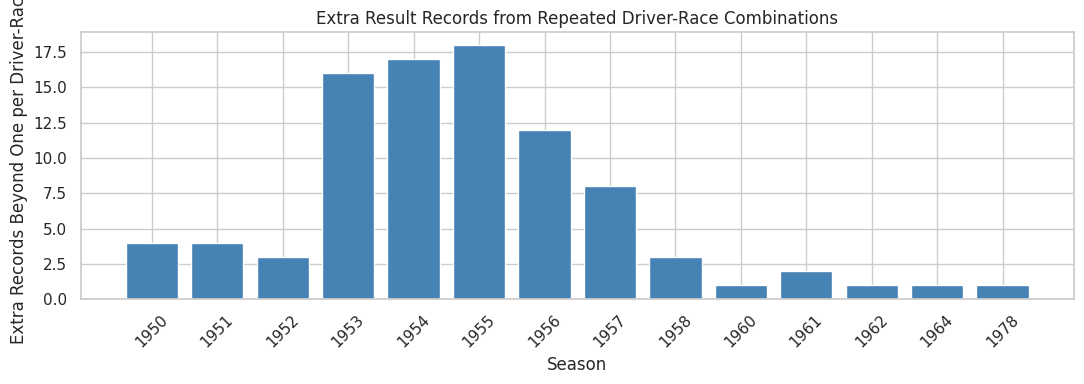

FIELD DIFFERENCES WITHIN REPEATED GROUPS


,Groups With Different Values,Total Repeated Groups
number,85,85
constructorId,16,85
grid,81,85
positionOrder,85,85
points,35,85
laps,82,85
statusId,79,85



Repeated groups containing both podium and non-podium records: 21



In [64]:
# Investigate repeated driver-race combinations without removing records
driver_race_keys = ['raceId', 'driverId']

# keep=False identifies ALL rows belonging to repeated combinations
duplicate_mask = results.duplicated(
    subset=driver_race_keys,
    keep=False
)

duplicate_rows = results.loc[duplicate_mask].copy()

if duplicate_rows.empty:
    print('No repeated driver-race combinations found.')

else:
    # 1. Count records in each repeated driver-race combination
    duplicate_groups = (
        duplicate_rows.groupby(driver_race_keys)
        .size()
        .reset_index(name='record_count')
    )

    duplicate_groups['extra_rows'] = (
        duplicate_groups['record_count'] - 1
    )

    duplicate_groups = duplicate_groups.merge(
        races[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )

    print('REPEATED DRIVER-RACE SUMMARY')
    print('Affected driver-race combinations:', len(duplicate_groups))
    print('Total records involved:', len(duplicate_rows))
    print('Extra rows:', duplicate_groups['extra_rows'].sum())
    print(
        'Percentage of result rows that are extra:',
        round(
            duplicate_groups['extra_rows'].sum() / len(results) * 100,
            2
        )
    )
    print()


    # 2. Locate the repetitions historically
    duplicate_by_year = (
        duplicate_groups.groupby('year')
        .agg(
            affected_pairs=('record_count', 'size'),
            records_involved=('record_count', 'sum'),
            extra_rows=('extra_rows', 'sum')
        )
        .sort_index()
    )

    print('REPEATED DRIVER-RACE COMBINATIONS BY YEAR')
    display(duplicate_by_year)
    print()

    print(
        'Affected combinations in 1950-1957:',
        duplicate_groups['year'].between(1950, 1957).sum()
    )
    print()

    plt.figure(figsize=(11, 4))

    plt.bar(
        duplicate_by_year.index.astype(str),
        duplicate_by_year['extra_rows'],
        color='steelblue'
    )

    plt.title('Extra Result Records from Repeated Driver-Race Combinations')
    plt.xlabel('Season')
    plt.ylabel('Extra Records Beyond One per Driver-Race')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    # 3. Determine which stored fields differ within repeated groups
    comparison_columns = [
        'number',
        'constructorId',
        'grid',
        'positionOrder',
        'points',
        'laps',
        'statusId'
    ]

    distinct_values = (
        duplicate_rows.groupby(driver_race_keys)[comparison_columns]
        .nunique(dropna=False)
    )

    variation_summary = pd.DataFrame({
        'Groups With Different Values': distinct_values.gt(1).sum(),
        'Total Repeated Groups': len(duplicate_groups)
    })

    print('FIELD DIFFERENCES WITHIN REPEATED GROUPS')
    display(variation_summary)
    print()


    # 4. Check whether choosing a record can change the podium label
    podium_variation = (
        duplicate_rows.assign(
            podium=duplicate_rows['positionOrder'].le(3)
        )
        .groupby(driver_race_keys)['podium']
        .nunique()
    )

    print(
        'Repeated groups containing both podium and non-podium records:',
        podium_variation.gt(1).sum()
    )
    print()


### 2.4 Check unclear values before deciding what to change

**A grid position of 0 is not a normal starting slot.** The F1 background notes suggest
it means a pit-lane start, but this is checked here by comparing grid-0 entries with
their race status and season, instead of assuming every 0 means the same thing.

**Which entries are kept:** every recorded entry stays in the data, including drivers
who did not start. Removing rows based on how the race turned out would let the result
decide which rows the model sees. The race status (for example "Engine" or "Accident")
is used here only to understand the data, never as a model input.

For the mechanical-retirement question, non-starters and zero-lap entries are handled
separately: `laps == 0` alone does not prove a car never started. No rows are deleted
and no zeros are blanked out across the board.

Extra spaces at the start or end of text labels (for example a nationality) are
counted. Only that formatting issue is fixed; historical team and nationality names are
not merged.

grid_record,Grid zero,Positive grid
status,,
Did not qualify,"1,013",12
Did not prequalify,331,0
Withdrew,164,84
+1 Lap,27,"4,010"
Finished,22,"7,652"
Accident,20,"1,042"
Injury,8,5
+2 Laps,7,"1,606"
Disqualified,6,141


,entries,grid_zero,explicit_nonstarts,ambiguous_zero_laps
period,,,,
Before 2014,"22,133","1,559","1,578",814
2014-2021,"3,267",39,7,97
2022 onward,"1,359",40,4,32


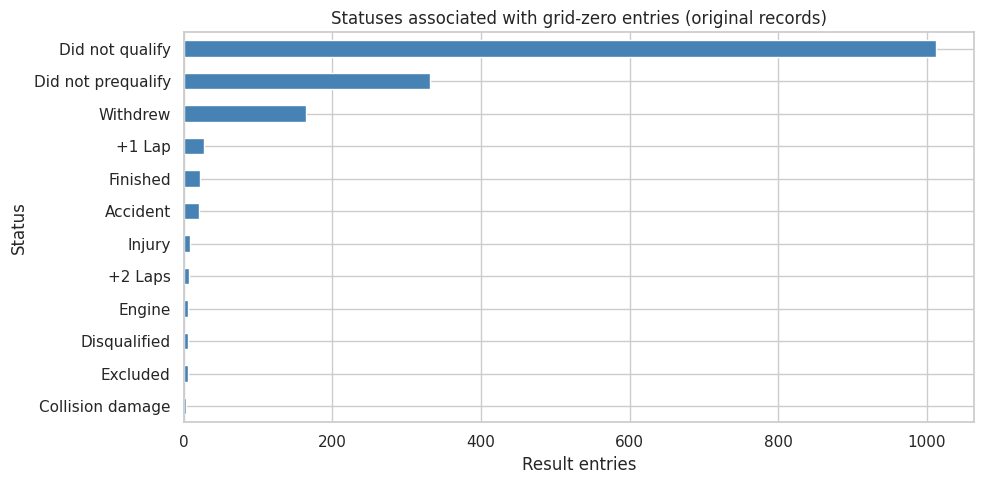

Table,Column,Rows with edge whitespace
drivers,nationality,1
constructors,nationality,0
circuits,country,0


In [65]:
NONSTART_CODES = {'Did not qualify', 'Did not prequalify', 'Withdrew', '107% Rule'}

def entry_context(result_table, race_table, status_table):
    context = result_table.merge(race_table[['raceId', 'year']],
        on='raceId', how='left', validate='many_to_one')
    context = context.merge(status_table[['statusId', 'status']],
        on='statusId', how='left', validate='many_to_one')
    context['grid_record'] = np.where(context['grid'].eq(0), 'Grid zero', 'Positive grid')
    context['explicit_nonstart'] = context['status'].isin(NONSTART_CODES) & context['laps'].eq(0)
    context['ambiguous_zero_laps'] = context['laps'].eq(0) & ~context['explicit_nonstart']
    context['period'] = pd.cut(context['year'], [-np.inf, 2013, 2021, np.inf],
        labels=['Before 2014', '2014-2021', '2022 onward'])
    return context

raw_entry_context = entry_context(results, races, status)
grid_status_counts = pd.crosstab(raw_entry_context['status'], raw_entry_context['grid_record'])
grid_status_counts = grid_status_counts.reindex(columns=['Grid zero', 'Positive grid'], fill_value=0)
display(grid_status_counts.sort_values('Grid zero', ascending=False).head(15))
zero_by_period = raw_entry_context.groupby('period', observed=True).agg(
    entries=('resultId', 'size'), grid_zero=('grid', lambda s: s.eq(0).sum()),
    explicit_nonstarts=('explicit_nonstart', 'sum'),
    ambiguous_zero_laps=('ambiguous_zero_laps', 'sum'))
display(zero_by_period)
ax = grid_status_counts.loc[grid_status_counts['Grid zero'].gt(0), 'Grid zero'].nlargest(12).sort_values().plot.barh(
    figsize=(10, 5), color='steelblue')
ax.set(title='Statuses associated with grid-zero entries (original records)', xlabel='Result entries', ylabel='Status')
plt.tight_layout(); plt.show()

CATEGORY_COLUMNS = {'drivers': ['nationality'], 'constructors': ['nationality'],
                    'circuits': ['country']}
category_audit_rows = []
for name, columns in CATEGORY_COLUMNS.items():
    for column in columns:
        values = tables[name][column]
        changed = values.notna() & values.ne(values.str.strip())
        category_audit_rows.append({'Table': name, 'Column': column,
            'Rows with edge whitespace': int(changed.sum())})
category_whitespace_audit = pd.DataFrame(category_audit_rows)
display(category_whitespace_audit)


### 2.5 First look at the relationships in the original data

These plots show how rare podiums are, how strongly the grid and qualifying positions
relate to podiums, how teams compare over history, and in which seasons qualifying data
exists. A temporary copy of the Q1 lap times is converted to seconds only for these
plots; the stored data is not changed.

Team totals reflect how many races a team entered as well as how good it was.
Relationships with race results are shown for understanding only; race results are not
allowed as model inputs.

Podium counts:


,count
podium,
0,"23,362"
1,"3,397"



Podium percentages:


,proportion
podium,
0,87.31
1,12.69


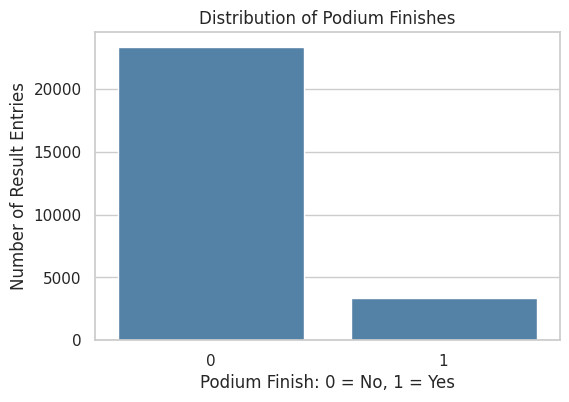


Podium percentage and sample size by starting grid group:


grid_group,count,podium_percentage
1,"1,136",63.47
2,"1,125",55.64
3-5,"3,394",35.12
6-10,"5,651",11.11
11-15,"5,617",3.03
16+,"8,198",0.73



Grid-zero entries excluded from this plot: 1638


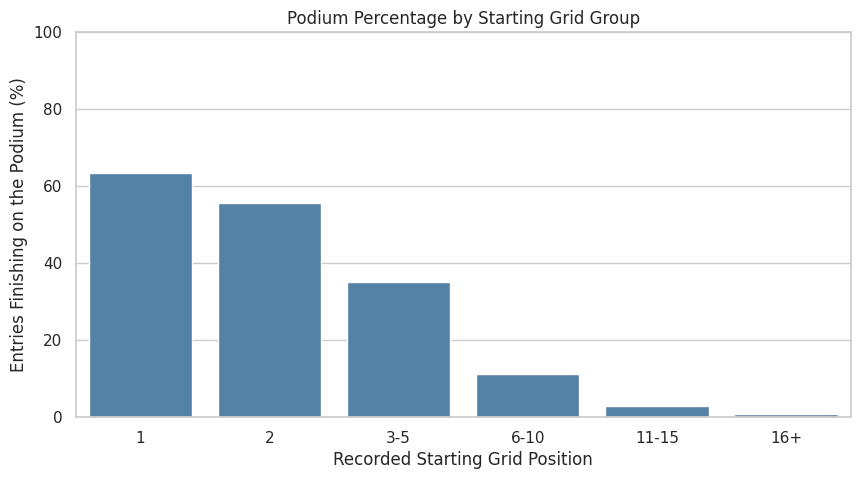


Podium percentage and sample size by Q1 gap group:


q1_gap_group,count,podium_percentage
0-0.5%,"1,758",44.99
0.5-1%,"2,012",18.94
1-2%,"3,336",6.86
2-3%,"1,458",3.43
3-5%,"1,145",1.05
5-10%,569,1.05
>10%,60,5



Entries without a usable Q1 gap: 16421


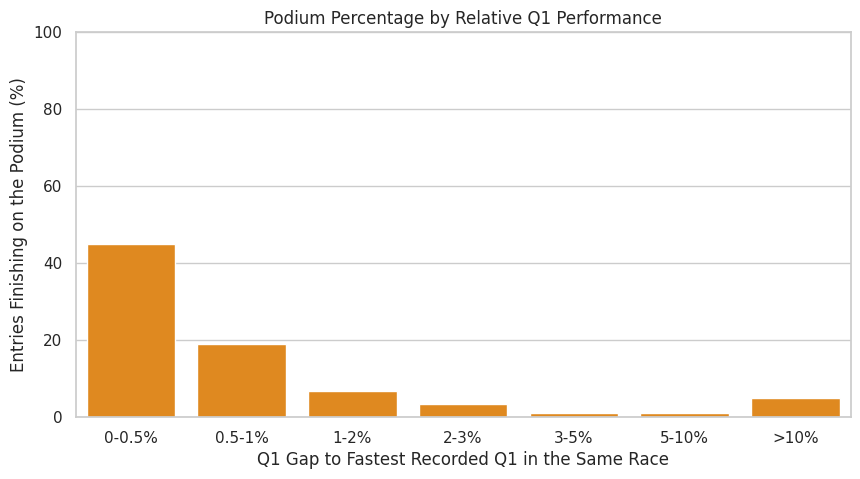

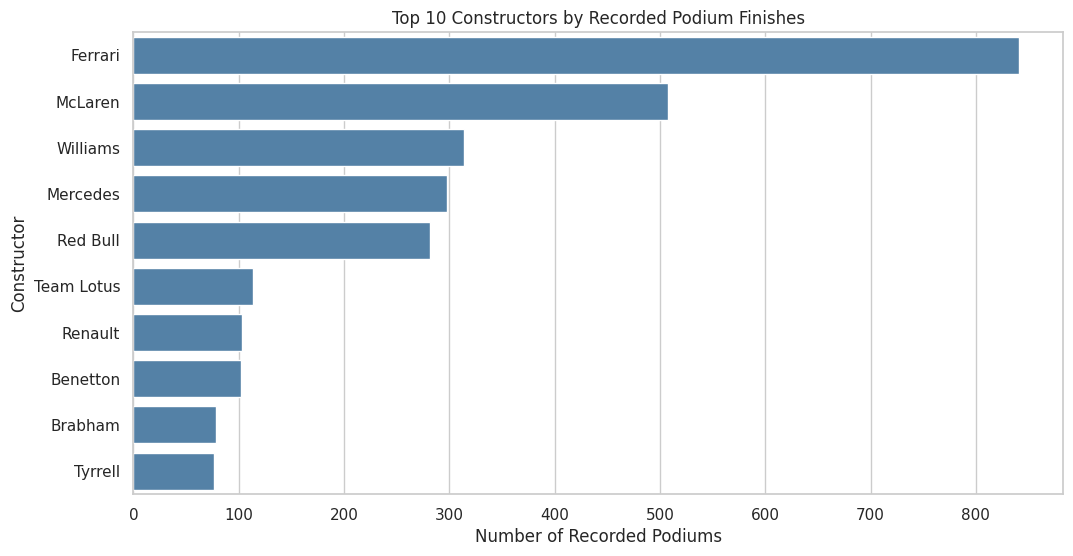

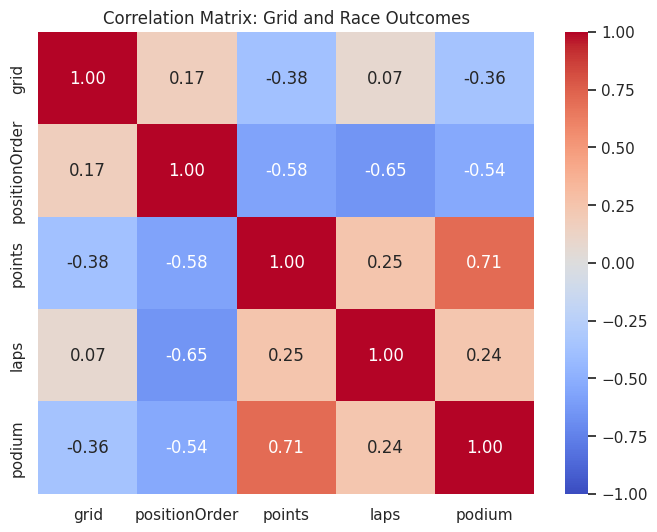

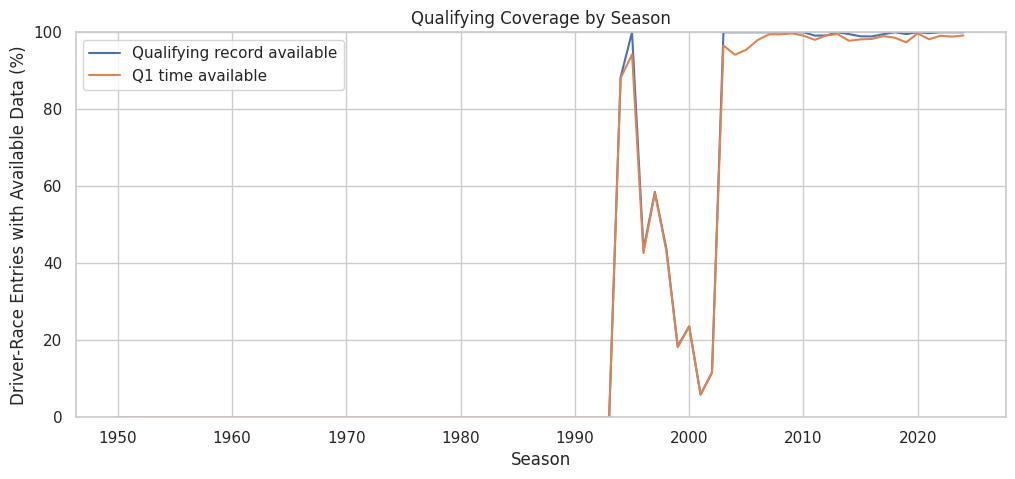

In [66]:
# 1. Create the target variable
results['podium'] = (results['positionOrder'] <= 3).astype(int)

print('Podium counts:')
display(results['podium'].value_counts())

print('\nPodium percentages:')
display((results['podium'].value_counts(normalize=True) * 100).round(2))


# 2. Visualize the target distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=results,
    x='podium',
    color='steelblue'
)

plt.title('Distribution of Podium Finishes')
plt.xlabel('Podium Finish: 0 = No, 1 = Yes')
plt.ylabel('Number of Result Entries')
plt.show()


# 3. Compare podium percentages across starting grid groups
# Exclude grid 0 only from this plot because its meaning is ambiguous.
grid_eda = results[results['grid'] > 0].copy()

grid_bins = [0, 1, 2, 5, 10, 15, float('inf')]
grid_labels = ['1', '2', '3-5', '6-10', '11-15', '16+']

grid_eda['grid_group'] = pd.cut(
    grid_eda['grid'],
    bins=grid_bins,
    labels=grid_labels
)

grid_summary = (
    grid_eda.groupby('grid_group', observed=True)['podium']
    .agg(['mean', 'count'])
    .reset_index()
)

grid_summary['podium_percentage'] = grid_summary['mean'] * 100

print('\nPodium percentage and sample size by starting grid group:')
display(grid_summary[[
        'grid_group', 'count', 'podium_percentage'
    ]].round(2))

print(
    '\nGrid-zero entries excluded from this plot:',
    (results['grid'] == 0).sum()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=grid_summary,
    x='grid_group',
    y='podium_percentage',
    color='steelblue',
    errorbar=None
)

plt.title('Podium Percentage by Starting Grid Group')
plt.xlabel('Recorded Starting Grid Position')
plt.ylabel('Entries Finishing on the Podium (%)')
plt.ylim(0, 100)
plt.show()


# 4. Compare podium percentages across relative Q1 performance groups
# Parse only a temporary copy when Q1 is still stored as text.
# Calculate each driver's percentage gap to the fastest Q1 in that race.
# Temporary copy for this analysis
qualifying_eda = qualifying[[
    'raceId', 'driverId', 'q1'
]].copy()

# Parse durations only in the temporary copy.
# The condition also lets this run after cleaning,
# when Q1 is already numeric seconds.
if not pd.api.types.is_numeric_dtype(qualifying_eda['q1']):
    parts = (
        qualifying_eda['q1']
        .replace(r'\N', np.nan)
        .str.split(':', expand=True)
    )

    qualifying_eda['q1'] = (
        parts[0].astype(float) * 60
        + parts[1].astype(float)
    )

# Find the fastest numeric Q1 duration in each race
qualifying_eda['fastest_q1'] = (
    qualifying_eda.groupby('raceId')['q1'].transform('min')
)

# Calculate percentage gap to that race's fastest Q1
qualifying_eda['q1_gap_percentage'] = (
    qualifying_eda['q1'] / qualifying_eda['fastest_q1'] - 1
) * 100

eda_df = results.merge(
    qualifying_eda[[
        'raceId', 'driverId', 'q1_gap_percentage'
    ]],
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

q1_bins = [0, 0.5, 1, 2, 3, 5, 10, float('inf')]
q1_labels = [
    '0-0.5%', '0.5-1%', '1-2%', '2-3%',
    '3-5%', '5-10%', '>10%'
]

eda_df['q1_gap_group'] = pd.cut(
    eda_df['q1_gap_percentage'],
    bins=q1_bins,
    labels=q1_labels,
    include_lowest=True
)

q1_summary = (
    eda_df.groupby('q1_gap_group', observed=True)['podium']
    .agg(['mean', 'count'])
    .reset_index()
)

q1_summary['podium_percentage'] = q1_summary['mean'] * 100

print('\nPodium percentage and sample size by Q1 gap group:')
display(q1_summary[[
        'q1_gap_group', 'count', 'podium_percentage'
    ]].round(2))

print(
    '\nEntries without a usable Q1 gap:',
    eda_df['q1_gap_percentage'].isnull().sum()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=q1_summary,
    x='q1_gap_group',
    y='podium_percentage',
    color='darkorange',
    errorbar=None
)

plt.title('Podium Percentage by Relative Q1 Performance')
plt.xlabel('Q1 Gap to Fastest Recorded Q1 in the Same Race')
plt.ylabel('Entries Finishing on the Podium (%)')
plt.ylim(0, 100)
plt.show()

# Missing Q1 gaps are omitted from this comparison.
# Extreme gaps remain included in the >10% group.


# 5. Show historical podium totals by constructor
# Avoid overwriting constructor_results, the name of another dataset table.
constructor_eda = results.merge(
    constructors[['constructorId', 'name']],
    on='constructorId',
    how='left',
    validate='many_to_one'
)

top_constructors = (
    constructor_eda.groupby(['constructorId', 'name'])['podium']
    .sum()
    .reset_index()
    .sort_values('podium', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_constructors,
    x='podium',
    y='name',
    color='steelblue',
    errorbar=None
)

plt.title('Top 10 Constructors by Recorded Podium Finishes')
plt.xlabel('Number of Recorded Podiums')
plt.ylabel('Constructor')
plt.show()

# Totals depend on how many seasons and entries a constructor has.
# They do not directly measure current strength or podium probability.


# 6. Explore correlations among selected numerical variables
# This is descriptive analysis.
# Current-race outcome columns must remain outside model inputs.
numeric_columns = [
    'grid', 'positionOrder', 'points', 'laps', 'podium'
]

correlation = results[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix: Grid and Race Outcomes')
plt.show()


# 7. Examine qualifying coverage by season
# Count each driver-race pair once for this coverage calculation.
# This does not select a result or resolve historical duplicate handling.
coverage = results[['raceId', 'driverId']].drop_duplicates()

coverage = coverage.merge(
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

coverage = coverage.merge(
    qualifying[['raceId', 'driverId', 'qualifyId', 'q1']],
    on=['raceId', 'driverId'],
    how='left',
    validate='one_to_one'
)

coverage['has_qualifying_record'] = (
    coverage['qualifyId'].notnull()
).astype(int)

coverage['has_q1_time'] = (
    coverage['q1'].notna() & ~coverage['q1'].isin(SENTINELS)
).astype(int)

coverage_by_year = (
    coverage.groupby('year')[[
        'has_qualifying_record', 'has_q1_time'
    ]]
    .mean()
    .reset_index()
)

coverage_by_year['has_qualifying_record'] *= 100
coverage_by_year['has_q1_time'] *= 100

plt.figure(figsize=(12, 5))

plt.plot(
    coverage_by_year['year'],
    coverage_by_year['has_qualifying_record'],
    label='Qualifying record available'
)

plt.plot(
    coverage_by_year['year'],
    coverage_by_year['has_q1_time'],
    label='Q1 time available'
)

plt.title('Qualifying Coverage by Season')
plt.xlabel('Season')
plt.ylabel('Driver-Race Entries with Available Data (%)')
plt.ylim(0, 100)
plt.legend()
plt.show()


### 2.6 Why the original "missing values" chart looks complete

This chart shows what a standard missing-value check sees in the **original** files. A
`\N` is stored as text, so the check thinks the cell is filled. The counts above already
showed that these tables do have missing values. After cleaning (Section 3), the same
gaps appear as real blanks.

Both standings tables are included as well. They look complete because they truly have
no gaps or `\N` markers in this copy of the data.

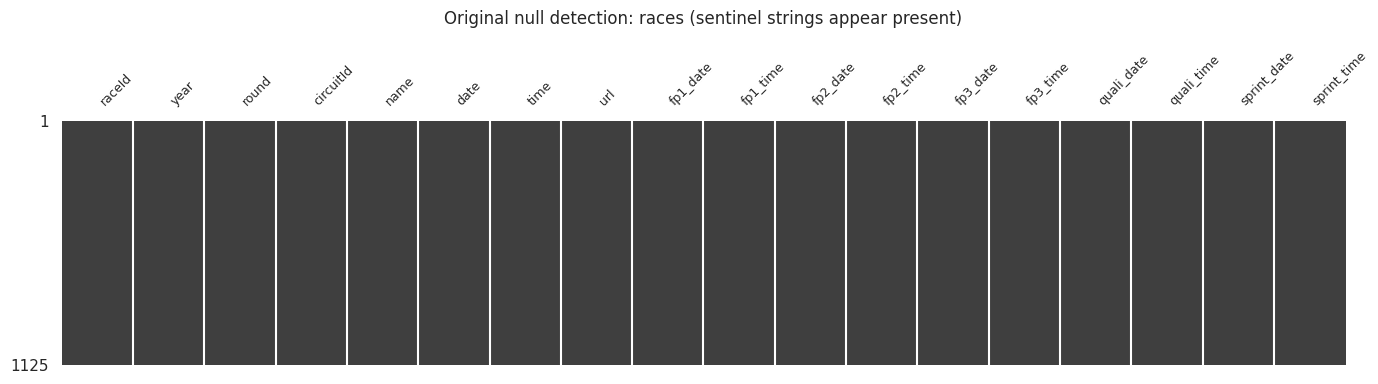

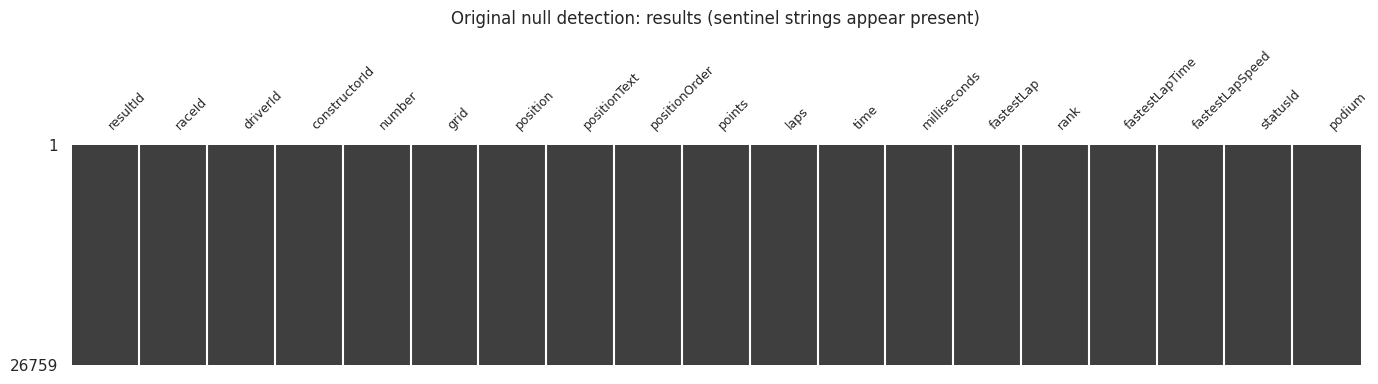

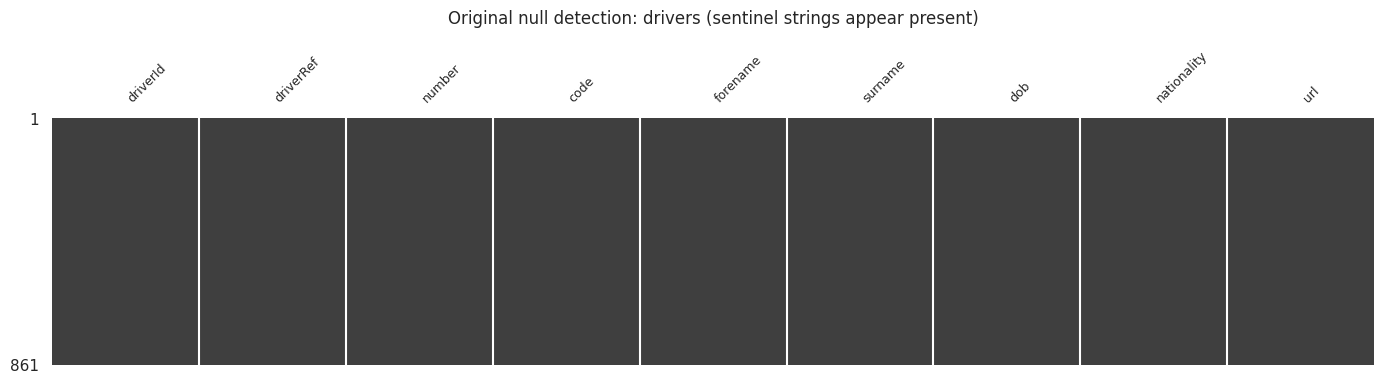

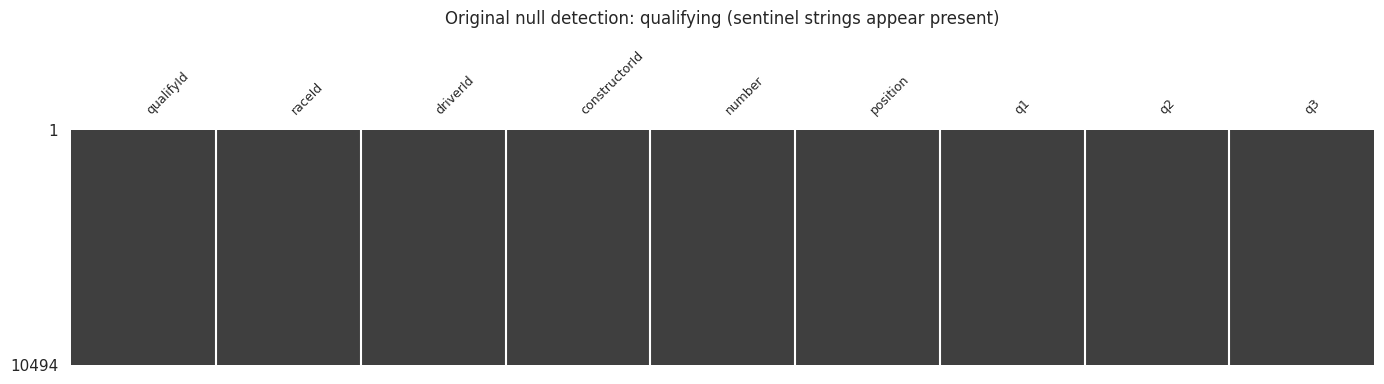

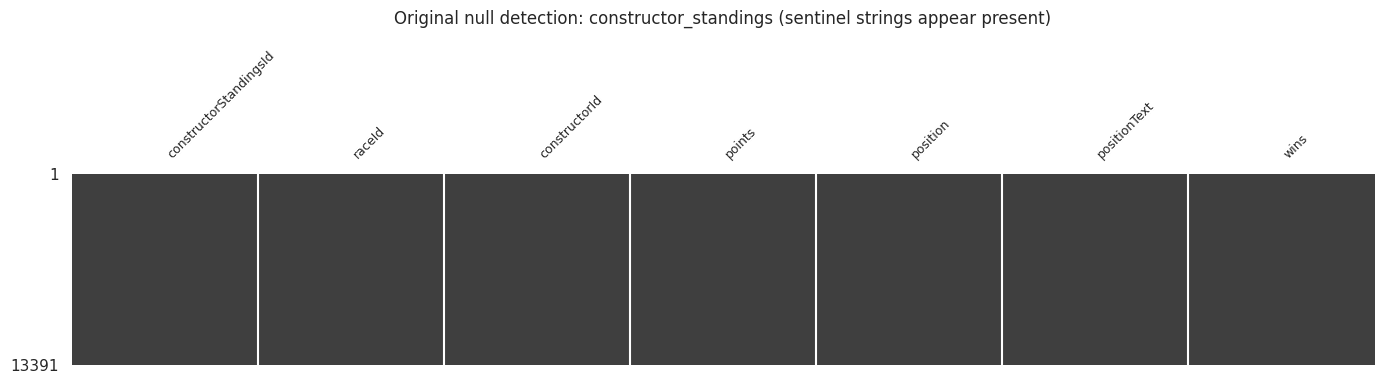

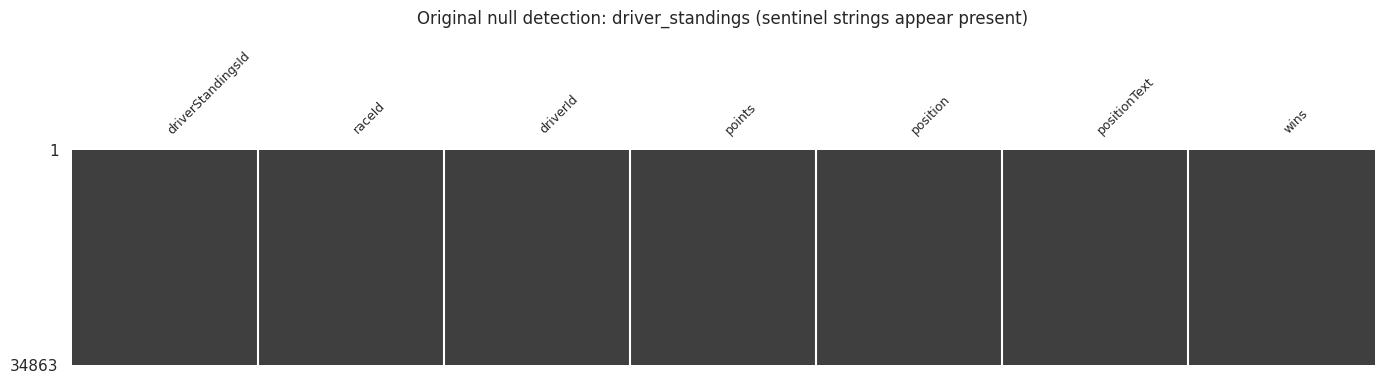

In [67]:
missing_matrix_names = [name for name in CORE_NAMES
    if name in ['constructor_standings', 'driver_standings']
    or (tables[name].isna() | tables[name].isin(SENTINELS)).any().any()]
for name in missing_matrix_names:
    plot_missingness_matrix(tables[name], f'Original null detection: {name} (sentinel strings appear present)')


<a id="clean-data"></a>
## 3. Clean the data

The cleaning steps and the reason for each:

- **Missing-value markers:** every `\N` becomes a real blank (missing value). This makes
  gaps visible to the code; it does not invent values.
- **Correct data types:** dates become real dates, lap times become seconds, and
  numeric result columns become numbers. A value in an unexpected format stops the code
  with an error instead of silently disappearing.
- **IDs:** all IDs are kept unchanged. Car numbers are stored as text because they are
  labels, not quantities.
- **Text labels:** extra spaces at the start or end of nationality/country labels are
  removed so "British" and "British " are not counted as different values. Historical
  names and team IDs are kept as they are.
- **Repeated driver–race rows:** for each repeated group, the row with the best
  finishing position is kept (ties: the lowest `resultId`). So if any of the driver's
  cars reached the podium, the driver keeps that podium.
- **Standings:** points stay decimal numbers (half points exist), positions and wins
  become whole numbers. The after-race standings are kept unchanged here; Section 6
  builds the "before this race" version from them.
- **Remaining gaps:** missing Q1/Q2/Q3 times and missing finishing positions stay
  missing. A missing Q2/Q3 usually just means the driver was knocked out earlier, so
  neither filling them in nor deleting rows is justified at this stage.
- **Grid 0 and non-starters:** kept as recorded. How grid 0 is handled for the models is
  decided in Section 7.

The repeated-row rule keeps the best **result**, so the kept row may come from a
different car (and grid slot) than the one the driver started in. All repeated groups
are from **1950–1978** (checked in 2.3), before any season used for training the models.

`results.time` stays text because it mixes full race times with gaps such as
`+12.345`; the numeric `milliseconds` column holds the actual duration. No columns or
rows are removed just to make a missing-value chart look cleaner.

In [68]:
# 1. Preserve the state immediately before cleaning
before_cleaning = {
    'races': races.copy(),
    'results': results.copy(),
    'circuits': circuits.copy(),
    'drivers': drivers.copy(),
    'constructors': constructors.copy(),
    'status': status.copy(),
    'qualifying': qualifying.copy(),
    'constructor_standings': constructor_standings.copy(),
    'driver_standings': driver_standings.copy()
}


# 2. Replace missing-value placeholders on working copies
sentinels = SENTINELS

tables = {
    name: table.replace(sentinels, np.nan)
    for name, table in before_cleaning.items()
}


# 3. Convert calendar dates
race_date_columns = [
    'date',
    'fp1_date', 'fp2_date', 'fp3_date',
    'quali_date', 'sprint_date'
]

for column in race_date_columns:
    if column in tables['races'].columns:
        tables['races'][column] = pd.to_datetime(
            tables['races'][column],
            format='%Y-%m-%d'
        )

tables['drivers']['dob'] = pd.to_datetime(
    tables['drivers']['dob'],
    format='%Y-%m-%d'
)


# 4. Convert lap durations from M:SS.sss into numeric seconds
duration_columns = {
    'qualifying': ['q1', 'q2', 'q3'],
    'results': ['fastestLapTime']
}

for name, columns in duration_columns.items():
    for column in columns:
        if column in tables[name].columns:
            # Skip conversion if already stored as numeric seconds
            if not pd.api.types.is_numeric_dtype(tables[name][column]):
                parts = tables[name][column].str.split(':', expand=True)

                tables[name][column] = (
                    parts[0].astype(float) * 60
                    + parts[1].astype(float)
                )


# 5. Convert numerical result fields previously stored as strings
# Int64 supports integer values AND missing values
result_numeric_types = {
    'position': 'Int64',
    'fastestLap': 'Int64',
    'rank': 'Int64',
    'milliseconds': 'float64',
    'fastestLapSpeed': 'float64'
}

for column, dtype in result_numeric_types.items():
    if column in tables['results'].columns:
        tables['results'][column] = pd.to_numeric(
            tables['results'][column]
        ).astype(dtype)


# Standings points may be fractional; ranks and win counts are integers.
for name in ['driver_standings', 'constructor_standings']:
    for column, dtype in {'points': 'float64', 'position': 'Int64', 'wins': 'Int64'}.items():
        tables[name][column] = pd.to_numeric(
            tables[name][column], errors='raise'
        ).astype(dtype)


# Car numbers are identifiers, not numerical measurements
for name in ['results', 'qualifying', 'drivers']:
    if 'number' in tables[name].columns:
        tables[name]['number'] = tables[name]['number'].astype('string')


# 6. Resolve repeated driver-race combinations
# Retain the best recorded finishing order.
# Break ties using the lowest resultId.
tables['results'] = (
    tables['results']
    .sort_values(
        ['raceId', 'driverId', 'positionOrder', 'resultId'],
        kind='stable'
    )
    .drop_duplicates(
        subset=['raceId', 'driverId'],
        keep='first'
    )
    .sort_index()
    .reset_index(drop=True)
)


# 7. Create/recalculate the target on the retained records
tables['results']['podium'] = (
    tables['results']['positionOrder'] <= 3
).astype(int)
# Normalize only audited categorical formatting differences.
category_normalization_rows = []
for name, columns in CATEGORY_COLUMNS.items():
    for column in columns:
        old_values = tables[name][column].copy()
        new_values = old_values.str.strip()
        changed = old_values.notna() & old_values.ne(new_values)
        if changed.any():
            changes = pd.DataFrame({'Old label': old_values[changed], 'New label': new_values[changed]})
            changes = changes.groupby(['Old label', 'New label']).size().reset_index(name='Rows changed')
            changes.insert(0, 'Column', column); changes.insert(0, 'Table', name)
            category_normalization_rows.append(changes)
        tables[name][column] = new_values

# 8. Connect all individual variables to the cleaned working tables.
(races, results, circuits, drivers, constructors, status, qualifying,
 constructor_standings, driver_standings) = (
    tables[name] for name in CORE_NAMES
)


<a id="post-eda"></a>
## 4. Compare the data before and after cleaning

### 4.1 Check the structure again

The same ID and link checks from Section 2 are repeated on the cleaned data. The nine
cleaned tables are checked together with the five tables that were kept as loaded. The
tables built later for modeling are also checked for "one row per driver per race".

In [69]:
post_audit_tables = dict(source_tables)
post_audit_tables.update(tables)
post_pk_audit, post_fk_audit = structural_audit(post_audit_tables)
display(post_pk_audit)
display(post_fk_audit)
assert post_pk_audit[['Missing PK rows', 'Duplicate PK extras']].to_numpy().sum() == 0
assert post_fk_audit[['Missing FK rows', 'Unmatched FK rows']].to_numpy().sum() == 0
assert not qualifying.duplicated(['raceId', 'driverId']).any()
for name, entity in [('driver_standings', 'driverId'),
                     ('constructor_standings', 'constructorId')]:
    assert not tables[name].duplicated(['raceId', entity]).any(), f'{name}: repeated snapshot keys'
assert all(globals()[name] is tables[name] for name in CORE_NAMES)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == csv_hashes_before[name]
           for name, path in csv_paths.items()), 'A raw CSV changed.'
print('Passed: keys, relationships, qualifying/standings grain, working-table references, and original CSV hashes.')


Table,Primary key,Exact extra rows,Missing PK rows,Duplicate PK extras
races,raceId,0,0,0
results,resultId,0,0,0
circuits,circuitId,0,0,0
drivers,driverId,0,0,0
constructors,constructorId,0,0,0
status,statusId,0,0,0
qualifying,qualifyId,0,0,0
constructor_standings,constructorStandingsId,0,0,0
driver_standings,driverStandingsId,0,0,0
seasons,year,0,0,0


Relationship,Missing FK rows,Unmatched FK rows
races.circuitId -> circuits.circuitId,0,0
races.year -> seasons.year,0,0
results.raceId -> races.raceId,0,0
results.driverId -> drivers.driverId,0,0
results.constructorId -> constructors.constructorId,0,0
qualifying.raceId -> races.raceId,0,0
qualifying.driverId -> drivers.driverId,0,0
qualifying.constructorId -> constructors.constructorId,0,0
sprint_results.raceId -> races.raceId,0,0
sprint_results.driverId -> drivers.driverId,0,0


Passed: keys, relationships, qualifying/standings grain, working-table references, and original CSV hashes.


### 4.2 What changed in types and row counts

The type tables list only the columns whose type changed or that are new. In the
missing-value bars, **blue** is a `\N` text marker and **orange** is a real blank, on the
same scale for each table. A blue bar turning orange means the marker was converted,
not that a value was filled in. Totals can also drop slightly because repeated result
rows were removed.

The per-season chart of repeated rows is kept; a long row-by-row list of which record
was kept is left out on purpose.

ROW COUNTS: OLD VS NEW


,Old,New,Rows Removed
races,"1,125","1,125",0
results,"26,759","26,668",91
circuits,77,77,0
drivers,861,861,0
constructors,212,212,0
status,139,139,0
qualifying,"10,494","10,494",0
constructor_standings,"13,391","13,391",0
driver_standings,"34,863","34,863",0



DATA TYPE AND COLUMN CHANGES
races


Column,Old Type,New Type
date,object,datetime64[ns]
fp1_date,object,datetime64[ns]
fp2_date,object,datetime64[ns]
fp3_date,object,datetime64[ns]
quali_date,object,datetime64[ns]
sprint_date,object,datetime64[ns]


results


...

constructor_standings


Column,Old Type,New Type
position,int64,Int64
wins,int64,Int64


driver_standings


Column,Old Type,New Type
position,int64,Int64
wins,int64,Int64



MISSING-VALUE REPRESENTATION: OLD VS NEW


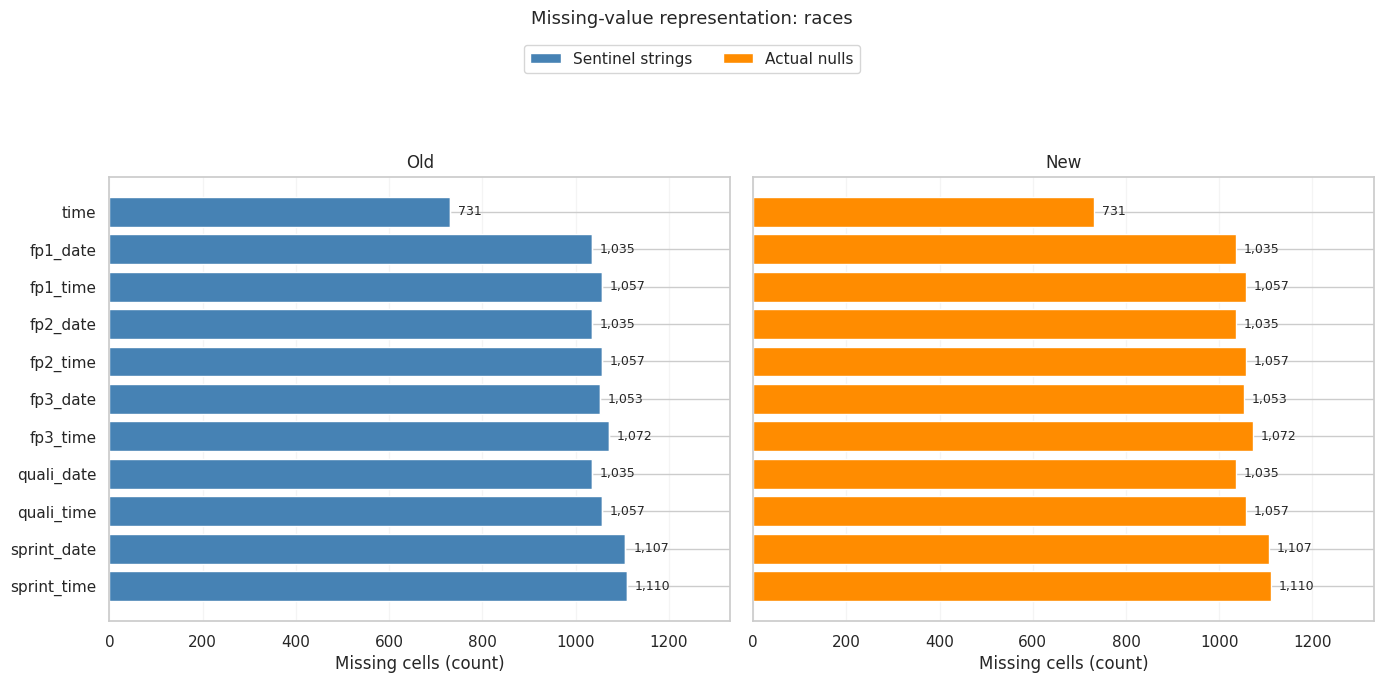

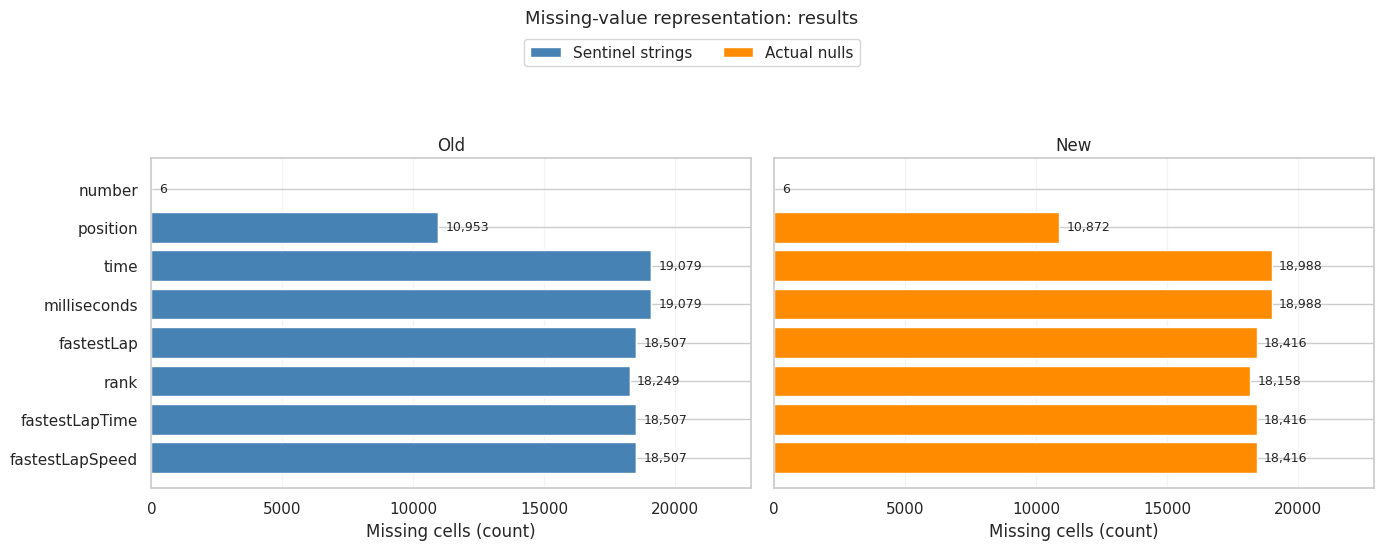

circuits: no sentinel or null-count changes.


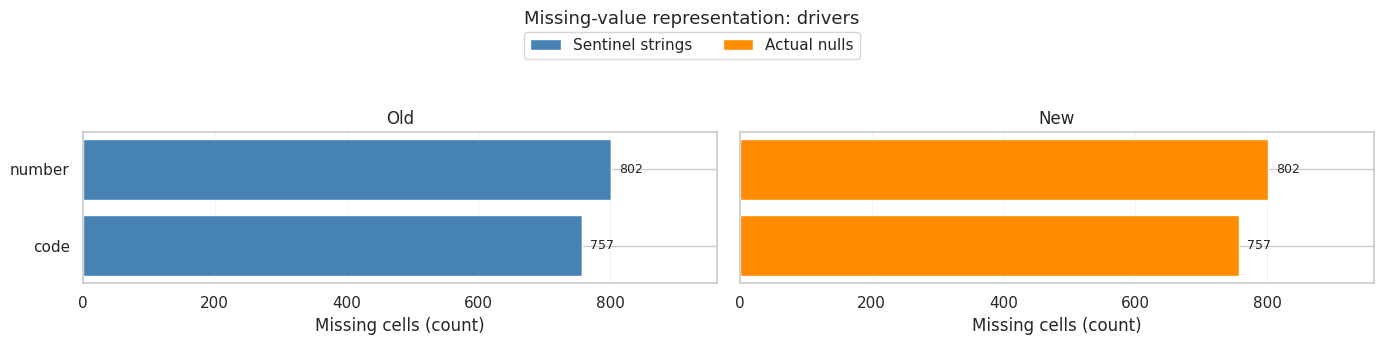

constructors: no sentinel or null-count changes.
status: no sentinel or null-count changes.


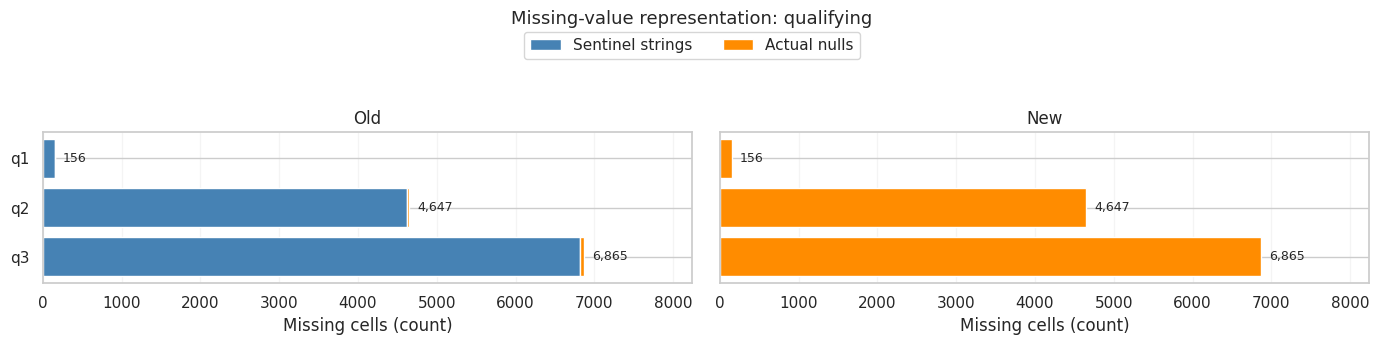

constructor_standings: no sentinel or null-count changes.
driver_standings: no sentinel or null-count changes.

DRIVER-RACE STRUCTURE: OLD VS NEW


,Old,New
Total result rows,"26,759","26,668"
Distinct driver-race combinations,"26,668","26,668"
Repeated driver-race combinations,85,0
Records belonging to repeated combinations,176,0
Extra rows,91,0


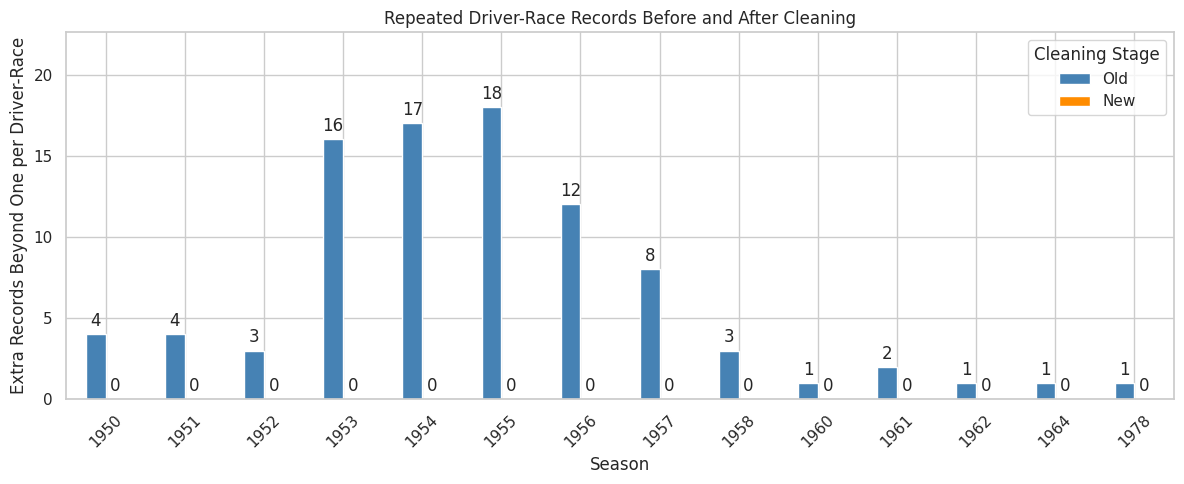


Verified: one result row per driver-race combination.


In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


#1. Compare row counts
row_comparison = pd.DataFrame({
    name: {
        'Old': len(before_cleaning[name]),
        'New': len(table),
        'Rows Removed': len(before_cleaning[name]) - len(table)
    }
    for name, table in tables.items()
}).T

print('ROW COUNTS: OLD VS NEW')
display(row_comparison)


#2. Compare data types and identify newly added columns
type_rows = []

for name, old in before_cleaning.items():
    new = tables[name]

    for column in old.columns.union(new.columns, sort=False):
        old_type = (
            str(old[column].dtype)
            if column in old.columns
            else 'Not present'
        )

        new_type = (
            str(new[column].dtype)
            if column in new.columns
            else 'Not present'
        )

        if old_type != new_type:
            type_rows.append({
                'Table': name,
                'Column': column,
                'Old Type': old_type,
                'New Type': new_type
            })

dtype_changes = pd.DataFrame(
    type_rows,
    columns=['Table', 'Column', 'Old Type', 'New Type']
)

print('\nDATA TYPE AND COLUMN CHANGES')

for name in tables:
    changes = dtype_changes[dtype_changes['Table'] == name]

    print(name)

    if changes.empty:
        print('No data type or column changes.\n')
    else:
        display(
            changes.drop(columns='Table').reset_index(drop=True)
        )


#3. Visualize sentinel and actual-null counts before and after cleaning
missing_profiles = {}

print('\nMISSING-VALUE REPRESENTATION: OLD VS NEW')

for name, old in before_cleaning.items():
    new = tables[name]
    columns = old.columns.intersection(new.columns)

    profile = pd.DataFrame({
        'Sentinels Old': old[columns].isin(sentinels).sum(),
        'Sentinels New': new[columns].isin(sentinels).sum(),
        'Nulls Old': old[columns].isna().sum(),
        'Nulls New': new[columns].isna().sum()
    })

    # Include columns containing sentinels or changed null counts
    affected = (
        profile['Sentinels Old'].gt(0)
        | profile['Sentinels New'].gt(0)
        | profile['Nulls Old'].ne(profile['Nulls New'])
    )

    profile = profile.loc[affected]
    missing_profiles[name] = profile

    if profile.empty:
        print(f'{name}: no sentinel or null-count changes.')
        continue

    y = np.arange(len(profile))

    largest_total = max(
        (profile['Sentinels Old'] + profile['Nulls Old']).max(),
        (profile['Sentinels New'] + profile['Nulls New']).max(),
        1
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, max(3.5, len(profile) * 0.45 + 2)),
        sharex=True,
        sharey=True
    )

    for ax, stage in zip(axes, ['Old', 'New']):
        sentinel_values = profile[f'Sentinels {stage}']
        null_values = profile[f'Nulls {stage}']
        totals = sentinel_values + null_values

        ax.barh(
            y,
            sentinel_values,
            color='steelblue',
            label='Sentinel strings'
        )

        ax.barh(
            y,
            null_values,
            left=sentinel_values,
            color='darkorange',
            label='Actual nulls'
        )

        # Label the total recognized missing count
        for position, total in zip(y, totals):
            ax.text(
                total + largest_total * 0.015,
                position,
                f'{int(total):,}',
                va='center',
                fontsize=9
            )

        ax.set_title(stage)
        ax.set_xlabel('Missing cells (count)')
        ax.set_xlim(0, largest_total * 1.2)
        ax.grid(axis='x', alpha=0.2)
        ax.set_axisbelow(True)

    axes[0].set_yticks(y)
    axes[0].set_yticklabels(profile.index)
    axes[0].invert_yaxis()

    handles, labels = axes[0].get_legend_handles_labels()

    fig.suptitle(
        f'Missing-value representation: {name}',
        fontsize=13
    )

    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.94),
        ncol=2
    )

    plt.tight_layout(rect=[0, 0, 1, 0.85])
    plt.show()


#4. Summarize repeated driver-race combinations
def repeated_groups(frame, race_table):
    groups = (
        frame.groupby(['raceId', 'driverId'])
        .size()
        .reset_index(name='records')
    )

    groups = groups.loc[groups['records'] > 1].copy()
    groups['extra_rows'] = groups['records'] - 1

    return groups.merge(
        race_table[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )


old_results = before_cleaning['results']
new_results = tables['results']

old_groups = repeated_groups(
    old_results,
    before_cleaning['races']
)

new_groups = repeated_groups(
    new_results,
    tables['races']
)

duplicate_comparison = pd.DataFrame({
    'Old': [
        len(old_results),
        len(old_results[['raceId', 'driverId']].drop_duplicates()),
        len(old_groups),
        old_groups['records'].sum(),
        old_groups['extra_rows'].sum()
    ],
    'New': [
        len(new_results),
        len(new_results[['raceId', 'driverId']].drop_duplicates()),
        len(new_groups),
        new_groups['records'].sum(),
        new_groups['extra_rows'].sum()
    ]
}, index=[
    'Total result rows',
    'Distinct driver-race combinations',
    'Repeated driver-race combinations',
    'Records belonging to repeated combinations',
    'Extra rows'
])

print('\nDRIVER-RACE STRUCTURE: OLD VS NEW')
display(duplicate_comparison)


#5. Visualize extra driver-race rows by year
duplicate_year_comparison = pd.concat({
    'Old': old_groups.groupby('year')['extra_rows'].sum(),
    'New': new_groups.groupby('year')['extra_rows'].sum()
}, axis=1).fillna(0).astype(int).sort_index()

if duplicate_year_comparison.empty:
    print('No repeated combinations before or after cleaning.')

else:
    ax = duplicate_year_comparison.plot(
        kind='bar',
        figsize=(12, 5),
        color=['steelblue', 'darkorange']
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=3)

    ax.set_title('Repeated Driver-Race Records Before and After Cleaning')
    ax.set_xlabel('Season')
    ax.set_ylabel('Extra Records Beyond One per Driver-Race')
    ax.legend(title='Cleaning Stage')
    ax.tick_params(axis='x', rotation=45)

    ax.set_ylim(
        0,
        duplicate_year_comparison.to_numpy().max() * 1.2 + 1
    )

    plt.tight_layout()
    plt.show()


#6. Verify the final required grain
assert not new_results.duplicated(
    subset=['raceId', 'driverId']
).any(), 'Repeated driver-race combinations remain.'

print('\nVerified: one result row per driver-race combination.')


In [71]:
if category_normalization_rows:
    print('CATEGORICAL FORMATTING CHANGES')
    print('␠ represents a space.')

    category_normalization_changes = pd.concat(
        category_normalization_rows,
        ignore_index=True
    )

    # Change the display copy only.
    visible_changes = category_normalization_changes.copy()

    for column in ['Old label', 'New label']:
        visible_changes[column] = visible_changes[column].map(
            lambda value: repr(value).replace(' ', '␠')
        )

    display(visible_changes)

else:
    print('No category formatting changes were needed.')

assert set(
    map(
        tuple,
        before_cleaning['results'][['raceId', 'driverId']].to_numpy()
    )
) == set(
    map(tuple, results[['raceId', 'driverId']].to_numpy())
)

print('Every original driver-race combination remains represented.')

CATEGORICAL FORMATTING CHANGES
␠ represents a space.


Table,Column,Old label,New label,Rows changed
drivers,nationality,'Argentinian␠','Argentinian',1


Every original driver-race combination remains represented.


### 4.3 Check that values make sense (without deleting extreme values)

Having the right type does not mean a value is sensible. These checks look for negative
counts or positions, lap times of zero or less, missing targets, and races dated before
a driver's birth. A flagged value is a reason to look closer, not an automatic deletion.

For the standings, negative points or wins and non-positive positions are flagged. A
driver's points can go *down* during a season (penalties, old scoring rules), so that is
not treated as an error.

Very large Q1 times are shown but kept: lap times depend on the circuit, the weather and
the session format, so a long time is not automatically wrong. No universal maximum is
imposed on grid, points, laps or lap time.

Check,Invalid rows,Observed rows
Negative grid,0,"26,668"
Negative laps,0,"26,668"
Negative points,0,"26,668"
Missing target source positionOrder,0,"26,668"
Non-positive positionOrder,0,"26,668"
Non-positive qualifying position,0,"10,494"
Non-positive qualifying.q1 seconds,0,"10,338"
Non-positive qualifying.q2 seconds,0,"5,847"
Non-positive qualifying.q3 seconds,0,"3,629"
Non-positive results.fastestLapTime seconds,0,"8,252"


,q1,q2,q3
count,"10,338","5,847","3,629"
mean,88.531,87.77,87.406
std,15.393,12.111,12.26
min,53.904,53.647,53.377
25%,78.774,77.942,77.238
50%,87.141,87.125,87.039
75%,95.91,95.956,95.626
95%,109.464,107.663,108.134
99%,123.961,119.132,121.19
max,"1,002.64",132.47,129.776


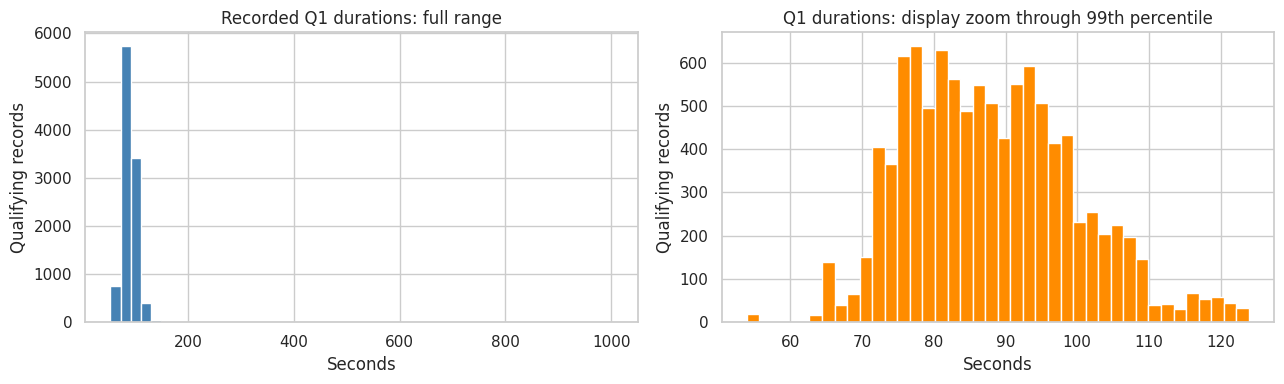

The zoom is for display only. No long durations were removed from the data.


In [72]:
validity_rows = []
def validity_check(label, invalid, observed):
    validity_rows.append({'Check': label, 'Invalid rows': int(invalid.sum()),
                          'Observed rows': int(observed.sum())})

for column in ['grid', 'laps', 'points']:
    s = results[column]
    validity_check(f'Negative {column}', s.lt(0), s.notna())
validity_check('Missing target source positionOrder', results['positionOrder'].isna(),
               pd.Series(True, index=results.index))
validity_check('Non-positive positionOrder', results['positionOrder'].le(0), results['positionOrder'].notna())
validity_check('Non-positive qualifying position', qualifying['position'].le(0), qualifying['position'].notna())
for name, columns in {'qualifying': ['q1', 'q2', 'q3'], 'results': ['fastestLapTime']}.items():
    for column in columns:
        s = tables[name][column]
        validity_check(f'Non-positive {name}.{column} seconds', s.le(0), s.notna())
age_audit = results[['raceId', 'driverId']].merge(races[['raceId', 'date']],
    on='raceId', how='left', validate='many_to_one').merge(drivers[['driverId', 'dob']],
    on='driverId', how='left', validate='many_to_one')
validity_check('Race date before driver birth', age_audit['date'].lt(age_audit['dob']),
               age_audit[['date', 'dob']].notna().all(axis=1))
for name in ['driver_standings', 'constructor_standings']:
    for column in ['points', 'wins']:
        s = tables[name][column]
        validity_check(f'Negative {name}.{column}', s.lt(0), s.notna())
    s = tables[name]['position']
    validity_check(f'Non-positive {name}.position', s.le(0), s.notna())
validity_summary = pd.DataFrame(validity_rows)
display(validity_summary)

duration_summary = qualifying[['q1', 'q2', 'q3']].describe(percentiles=[.25, .5, .75, .95, .99]).round(3)
display(duration_summary)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
q1_values = qualifying['q1'].dropna()
axes[0].hist(q1_values, bins=50, color='steelblue')
axes[0].set(title='Recorded Q1 durations: full range', xlabel='Seconds', ylabel='Qualifying records')
axes[1].hist(q1_values.loc[q1_values.le(q1_values.quantile(.99))], bins=40, color='darkorange')
axes[1].set(title='Q1 durations: display zoom through 99th percentile', xlabel='Seconds', ylabel='Qualifying records')
plt.tight_layout(); plt.show()
print('The zoom is for display only. No long durations were removed from the data.')


### 4.4 The missing-values chart after cleaning

The same columns now contain real blanks, so the missing values are finally visible.
The difference from 2.6 comes from how missing values are detected, not from losing any
data. Both standings tables are included again and still have no gaps.

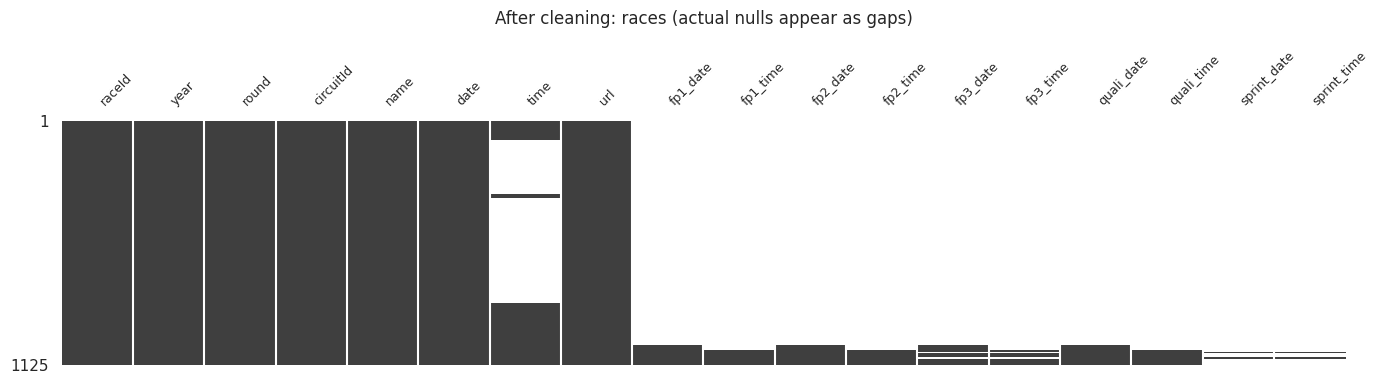

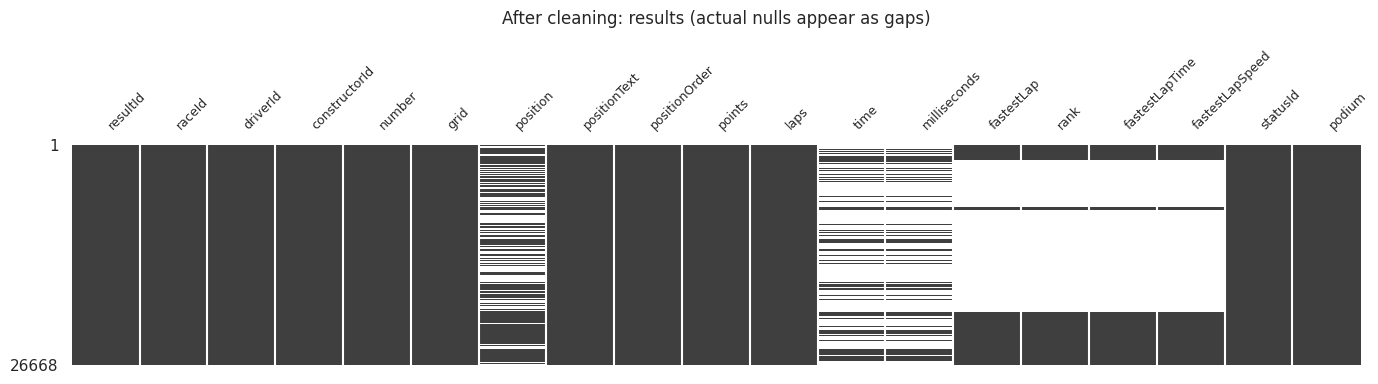

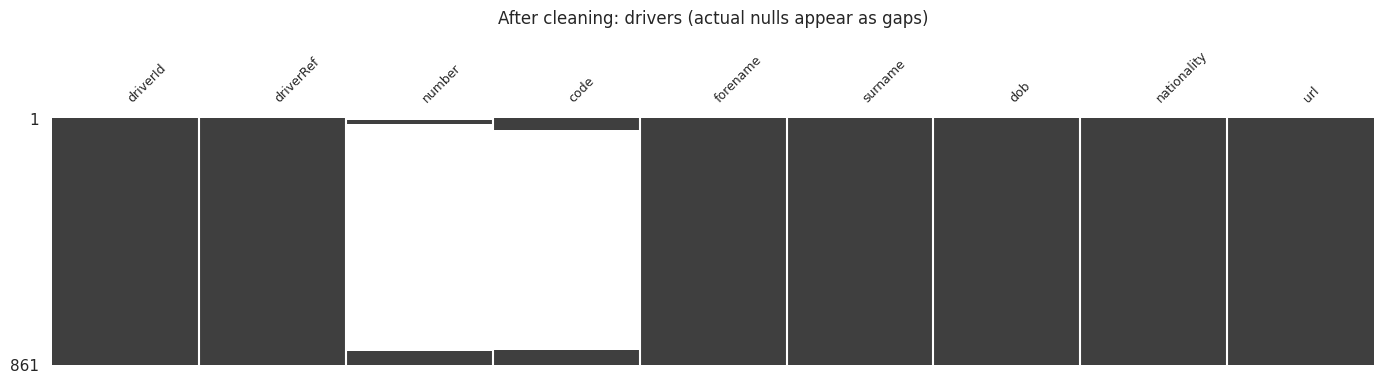

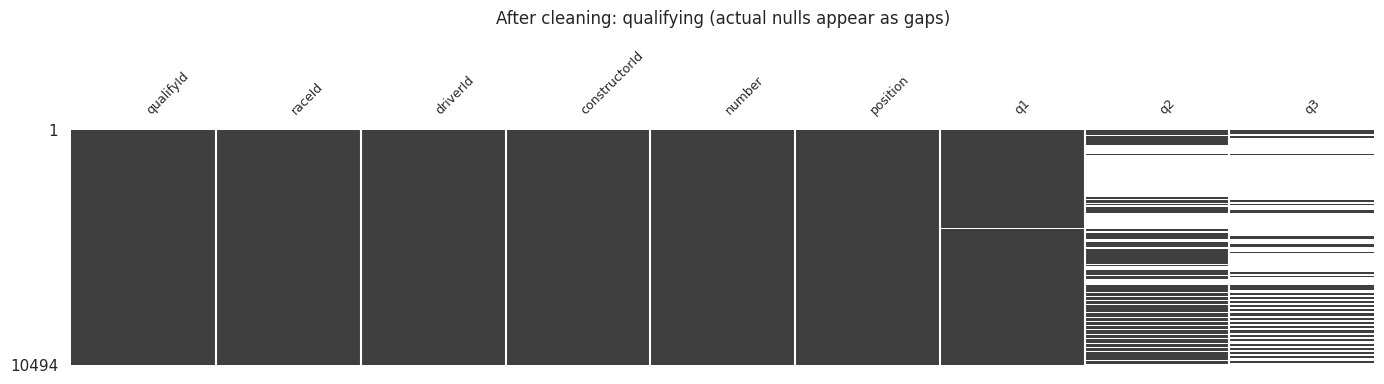

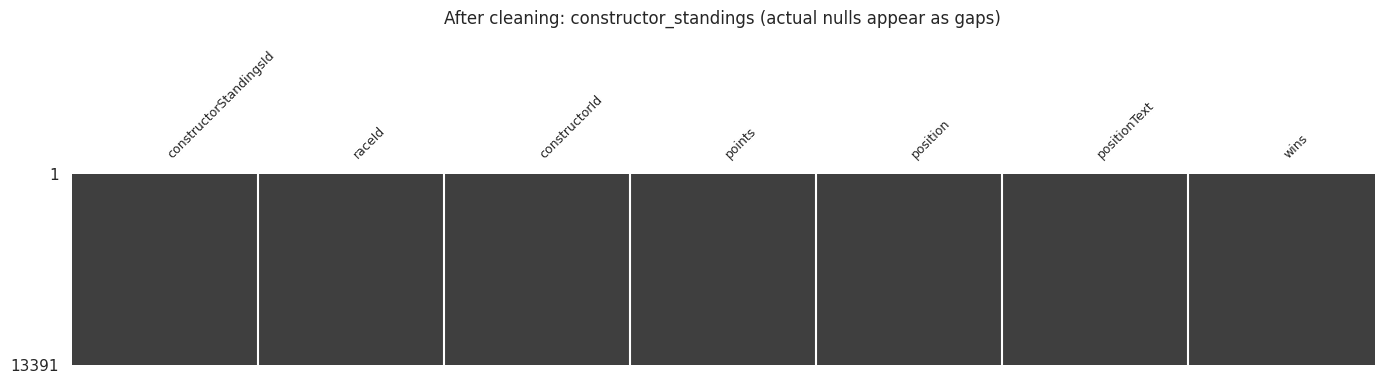

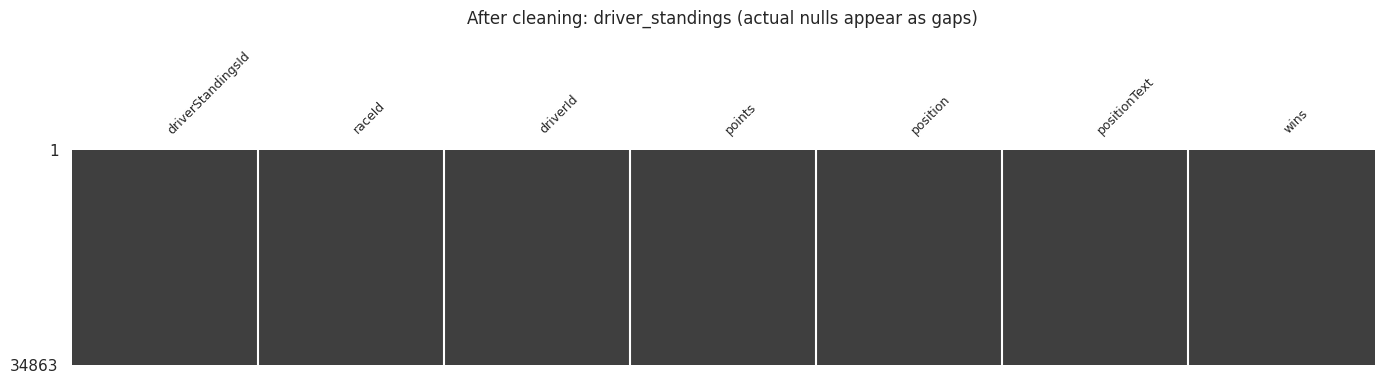

In [73]:
# Reuse the same table list, including both standings tables.
for name in missing_matrix_names:
    plot_missingness_matrix(tables[name], f'After cleaning: {name} (actual nulls appear as gaps)')


### 4.5 Compare the same relationships before and after cleaning

The same podium definition and grid groups are used before and after cleaning, so any
difference comes from the cleaning itself. Qualifying coverage counts each driver–race
pair only once in both versions, so it should not change.

Podium counts are shown as both numbers and percentages, because the raw data can count
the same driver–race twice while the cleaned data counts it once.

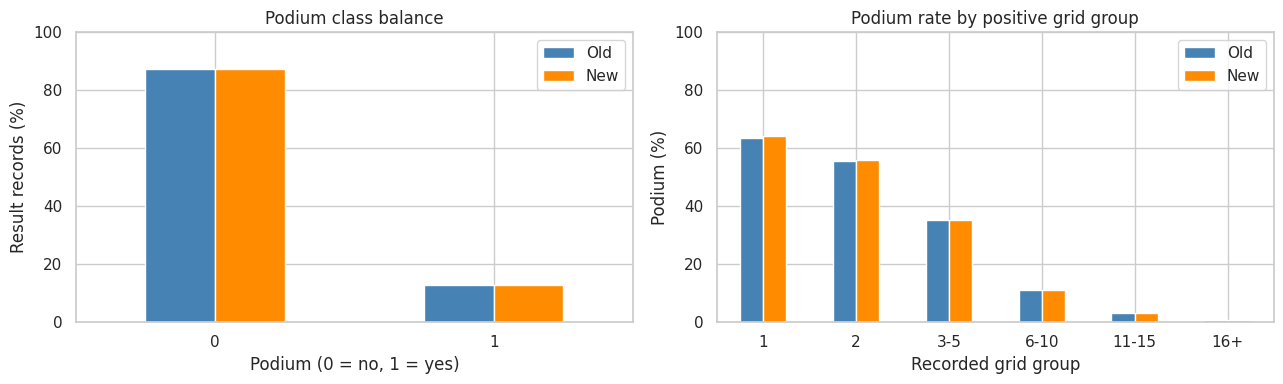

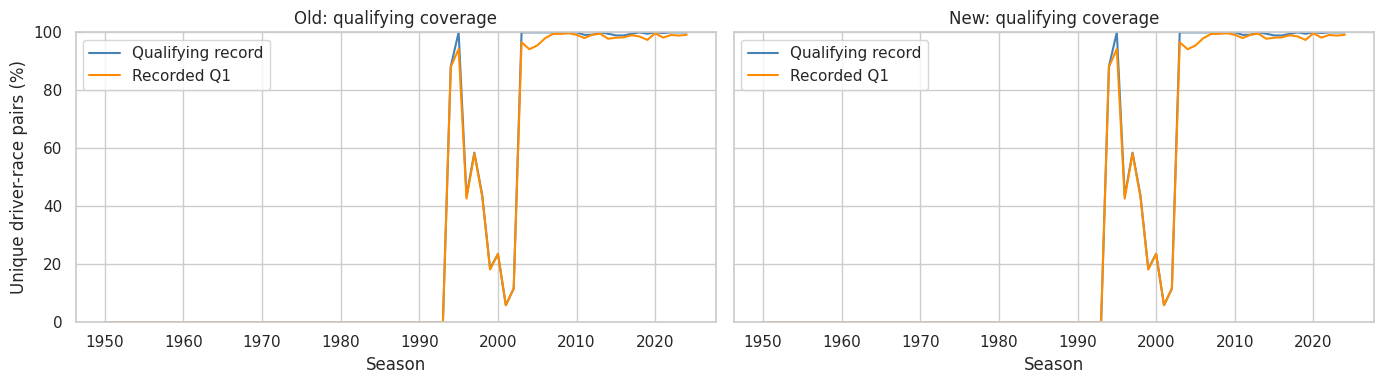

In [74]:
def target_profile(frame):
    target = frame['positionOrder'].le(3).astype(int)
    return pd.DataFrame({'Count': target.value_counts().reindex([0, 1], fill_value=0),
        'Percentage': target.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100})

def grid_podium_profile(frame):
    view = frame.loc[frame['grid'].gt(0), ['grid', 'positionOrder']].copy()
    view['podium'] = view['positionOrder'].le(3).astype(int)
    view['Grid group'] = pd.cut(view['grid'], [0, 1, 2, 5, 10, 15, np.inf],
        labels=['1', '2', '3-5', '6-10', '11-15', '16+'])
    out = view.groupby('Grid group', observed=True)['podium'].agg(['count', 'mean'])
    out['Podium %'] = out['mean'] * 100
    return out[['count', 'Podium %']]

def qualifying_coverage(result_table, race_table, qualifying_table):
    view = result_table[['raceId', 'driverId']].drop_duplicates().merge(
        race_table[['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
    view = view.merge(qualifying_table[['raceId', 'driverId', 'qualifyId', 'q1']],
        on=['raceId', 'driverId'], how='left', validate='one_to_one')
    view['Qualifying record'] = view['qualifyId'].notna()
    view['Recorded Q1'] = view['q1'].notna() & ~view['q1'].isin(SENTINELS)
    return view.groupby('year')[['Qualifying record', 'Recorded Q1']].mean() * 100

target_old = target_profile(before_cleaning['results'])
target_new = target_profile(results)
display(pd.concat({'Old': target_old, 'New': target_new}, axis=1).round(3))
grid_old = grid_podium_profile(before_cleaning['results'])
grid_new = grid_podium_profile(results)
display(pd.concat({'Old': grid_old, 'New': grid_new}, axis=1).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.DataFrame({'Old': target_old['Percentage'], 'New': target_new['Percentage']}).plot.bar(
    ax=axes[0], color=['steelblue', 'darkorange'], rot=0)
axes[0].set(title='Podium class balance', xlabel='Podium (0 = no, 1 = yes)', ylabel='Result records (%)', ylim=(0, 100))
pd.DataFrame({'Old': grid_old['Podium %'], 'New': grid_new['Podium %']}).plot.bar(
    ax=axes[1], color=['steelblue', 'darkorange'], rot=0)
axes[1].set(title='Podium rate by positive grid group', xlabel='Recorded grid group', ylabel='Podium (%)', ylim=(0, 100))
plt.tight_layout(); plt.show()

coverage_old = qualifying_coverage(before_cleaning['results'], before_cleaning['races'], before_cleaning['qualifying'])
coverage_new = qualifying_coverage(results, races, qualifying)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)
for ax, label, profile in [(axes[0], 'Old', coverage_old), (axes[1], 'New', coverage_new)]:
    profile.plot(ax=ax, color=['steelblue', 'darkorange'])
    ax.set(title=f'{label}: qualifying coverage', xlabel='Season', ylabel='Unique driver-race pairs (%)', ylim=(0, 100))
plt.tight_layout(); plt.show()


### 4.6 How much did cleaning change?

The table below is calculated from the data in this run. Small changes are a good sign:
fixing the format and removing duplicate rows should not change the overall picture
much.

In [75]:
# 4.6 CLEANING SUMMARY (calculated from this run)
removed = len(before_cleaning['results']) - len(results)
repeated_before = int(before_cleaning['results'].duplicated(['raceId', 'driverId']).sum())
repeated_after = int(results.duplicated(['raceId', 'driverId']).sum())
old_rate = target_old.loc[1, 'Percentage']
new_rate = target_new.loc[1, 'Percentage']
largest_grid_change = (grid_new['Podium %'] - grid_old['Podium %']).abs().max()
coverage_change = (coverage_new - coverage_old).abs().to_numpy().max()
old_sentinels = sum(int(t.isin(SENTINELS).sum().sum()) for t in before_cleaning.values())
new_sentinels = sum(int(t.isin(SENTINELS).sum().sum()) for t in tables.values())

cleaning_summary = pd.DataFrame([
    ('Result rows', f'{len(before_cleaning["results"]):,}', f'{len(results):,}',
     f'{removed:,} extra rows removed; every driver-race pair kept once'),
    ('Extra rows for an already-seen driver-race pair', f'{repeated_before:,}',
     f'{repeated_after:,}', 'One row per driver per race'),
    ('"\\N" markers in the nine core tables', f'{old_sentinels:,}', f'{new_sentinels:,}',
     'Turned into real blanks, not filled in'),
    ('Rows labelled as a podium', f'{target_old.loc[1, "Count"]:,}',
     f'{target_new.loc[1, "Count"]:,}', 'A podium stored twice is now counted once'),
    ('Share of rows that are podiums', f'{old_rate:.3f}%', f'{new_rate:.3f}%',
     f'Change of {new_rate - old_rate:+.3f} percentage points'),
    ('Largest change in podium rate of a grid group', '—',
     f'{largest_grid_change:.3f} pp', 'Grid-podium relationship practically unchanged'),
    ('Largest change in qualifying coverage of a season', '—',
     f'{coverage_change:.3f} pp', 'Coverage unchanged'),
    ('Value checks with at least one flagged row', '—',
     f'{int(validity_summary["Invalid rows"].gt(0).sum())} of {len(validity_summary)}',
     'Flagged rows would need a closer look'),
], columns=['Measure', 'Before cleaning', 'After cleaning', 'Meaning'])
display(cleaning_summary)

Measure,Before cleaning,After cleaning,Meaning
Result rows,"26,759","26,668",91 extra rows removed; every driver-race pair kept once
Extra rows for an already-seen driver-race pair,91,0,One row per driver per race
"""\N"" markers in the nine core tables","147,395",0,"Turned into real blanks, not filled in"
Rows labelled as a podium,"3,397","3,395",A podium stored twice is now counted once
Share of rows that are podiums,12.695%,12.731%,Change of +0.036 percentage points
Largest change in podium rate of a grid group,—,0.678 pp,Grid-podium relationship practically unchanged
Largest change in qualifying coverage of a season,—,0.000 pp,Coverage unchanged
Value checks with at least one flagged row,—,0 of 17,Flagged rows would need a closer look


### What the cleaning changed, in plain words

- **Duplicates:** only a small number of extra result rows were removed. Every
  driver–race pair is still present, now exactly once.
- **Missing values:** all `\N` markers became real blanks. Nothing was guessed or filled
  in.
- **Podiums:** a podium that was stored twice for the same driver and race is now counted
  once, so the podium share moves only very slightly.
- **Main relationships:** podium rates by grid group and qualifying coverage per season
  are practically unchanged.
- **Standings:** both standings tables had no gaps, no `\N` markers and no repeated rows,
  so cleaning did not change their contents.
- **Checks:** all ID/link checks and all value checks passed (see the tables above).
  That does not prove every value is right. The longest recorded Q1 time (over 1,000
  seconds, against a 99th percentile of about 124 seconds) is kept and reported as a
  limitation rather than deleted.

Missing qualifying data in older seasons is a known limitation. Section 7 tests how far
back the training data should go, with that limitation in mind. Anything that "learns"
from the data (filling gaps, scaling) is fitted on the training seasons only, in
Section 7.

<a id="analytical-base"></a>
## 5. Data-engineering questions

Each question below is answered by joining only the tables it needs. Every join is
checked so that one driver in one race stays one row.

### Question 1 · Which circuits convert a front-row start into a podium most often?

Which circuits turn a front-row start (grid P1 or P2) into a podium most often, and does
that ranking change after the start of the hybrid era in 2014? Qualifying position and
grid position are analysed separately, because penalties can move a driver's grid slot
away from where they qualified.

MISSING INFORMATION


,Missing entries
year,0
name,0
grid,0
qualifying_position,"16,174"
positionOrder,0


STARTING-POSITION COVERAGE: COUNTS ARE DRIVER–RACE ENTRIES


,entries,valid_grid,valid_qualifying
era,,,
2014 onward,"4,626","4,547","4,610"
Before 2014,"22,042","20,486","5,884"


Explicit non-start entries excluded from subsequent analyses: 1586
Grid / qualifying chart: 10,382 matched entries; 14,700 entries without two positive positions excluded.


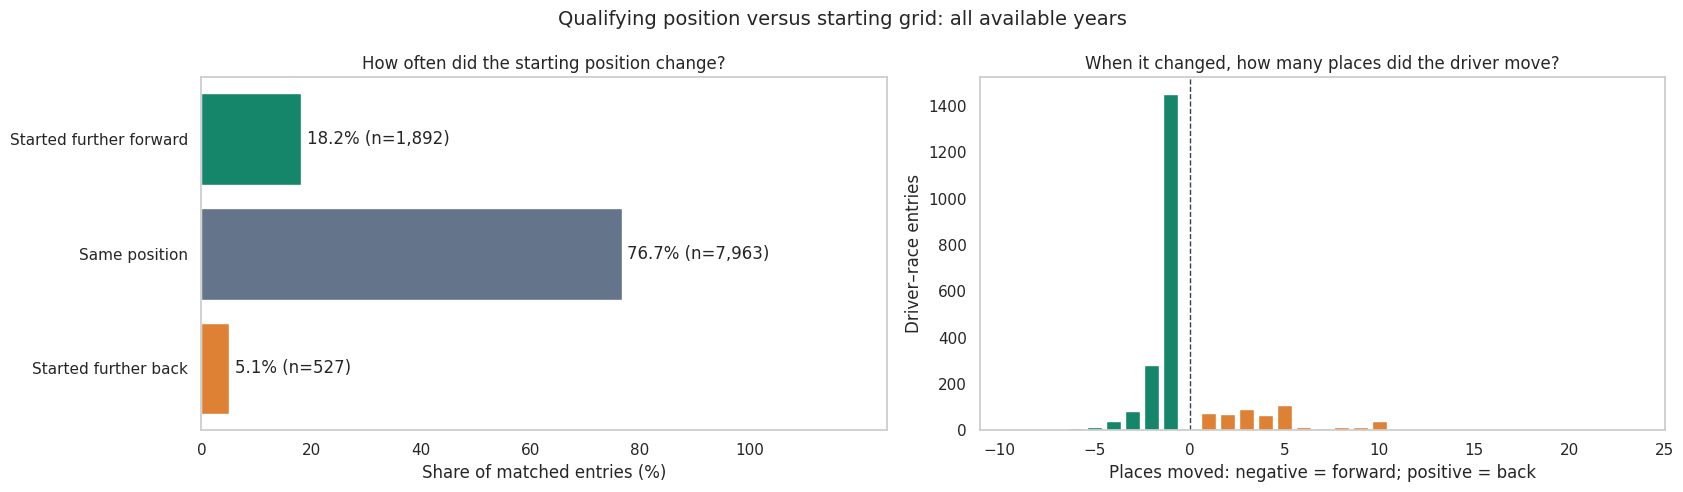

These charts show recorded position differences. A difference does not necessarily mean a penalty.
Circuit–era groups excluded from grid rankings for having fewer than 10 front-row entries: 38

TOP 5 CIRCUITS USING STARTING GRID: BEFORE 2014


Rank,Circuit,Front-row entries,Podium finishes,Podium rate (%)
1,Circuit de Nevers Magny-Cours,36,29,80.56
2,Istanbul Park,14,11,78.57
3,Dijon-Prenois,12,9,75
4,Suzuka Circuit,50,35,70
4,Sepang International Circuit,30,21,70


Highest rate — Circuit de Nevers Magny-Cours: 80.6% (29 podiums from 36 front-row entries).

TOP 5 CIRCUITS USING STARTING GRID: 2014 ONWARD


Rank,Circuit,Front-row entries,Podium finishes,Podium rate (%)
1,Suzuka Circuit,18,16,88.89
2,Yas Marina Circuit,22,19,86.36
3,Circuit de Monaco,20,17,85
4,Circuit de Barcelona-Catalunya,22,18,81.82
4,Circuit de Spa-Francorchamps,22,18,81.82


Highest rate — Suzuka Circuit: 88.9% (16 podiums from 18 front-row entries).

SAME TRACKS IN BOTH ERAS: RANK 1 = HIGHEST PODIUM RATE


Circuit,Before 2014: podium %,2014 onward: podium %,Rate change (percentage points),Before 2014: rank,2014 onward: rank
Suzuka Circuit,70,88.89,18.89,1,1
Yas Marina Circuit,60,86.36,26.36,6,2
Circuit de Monaco,49.17,85,35.83,15,3
Circuit de Barcelona-Catalunya,65.22,81.82,16.6,4,4
Circuit de Spa-Francorchamps,55.06,81.82,26.76,12,4
Autódromo José Carlos Pace,59.68,78.95,19.27,8,6
Shanghai International Circuit,65,78.57,13.57,5,7
Circuit Gilles Villeneuve,52.94,77.78,24.84,13,8
Silverstone Circuit,56.38,75,18.62,10,9
Red Bull Ring,52,73.08,21.08,14,10


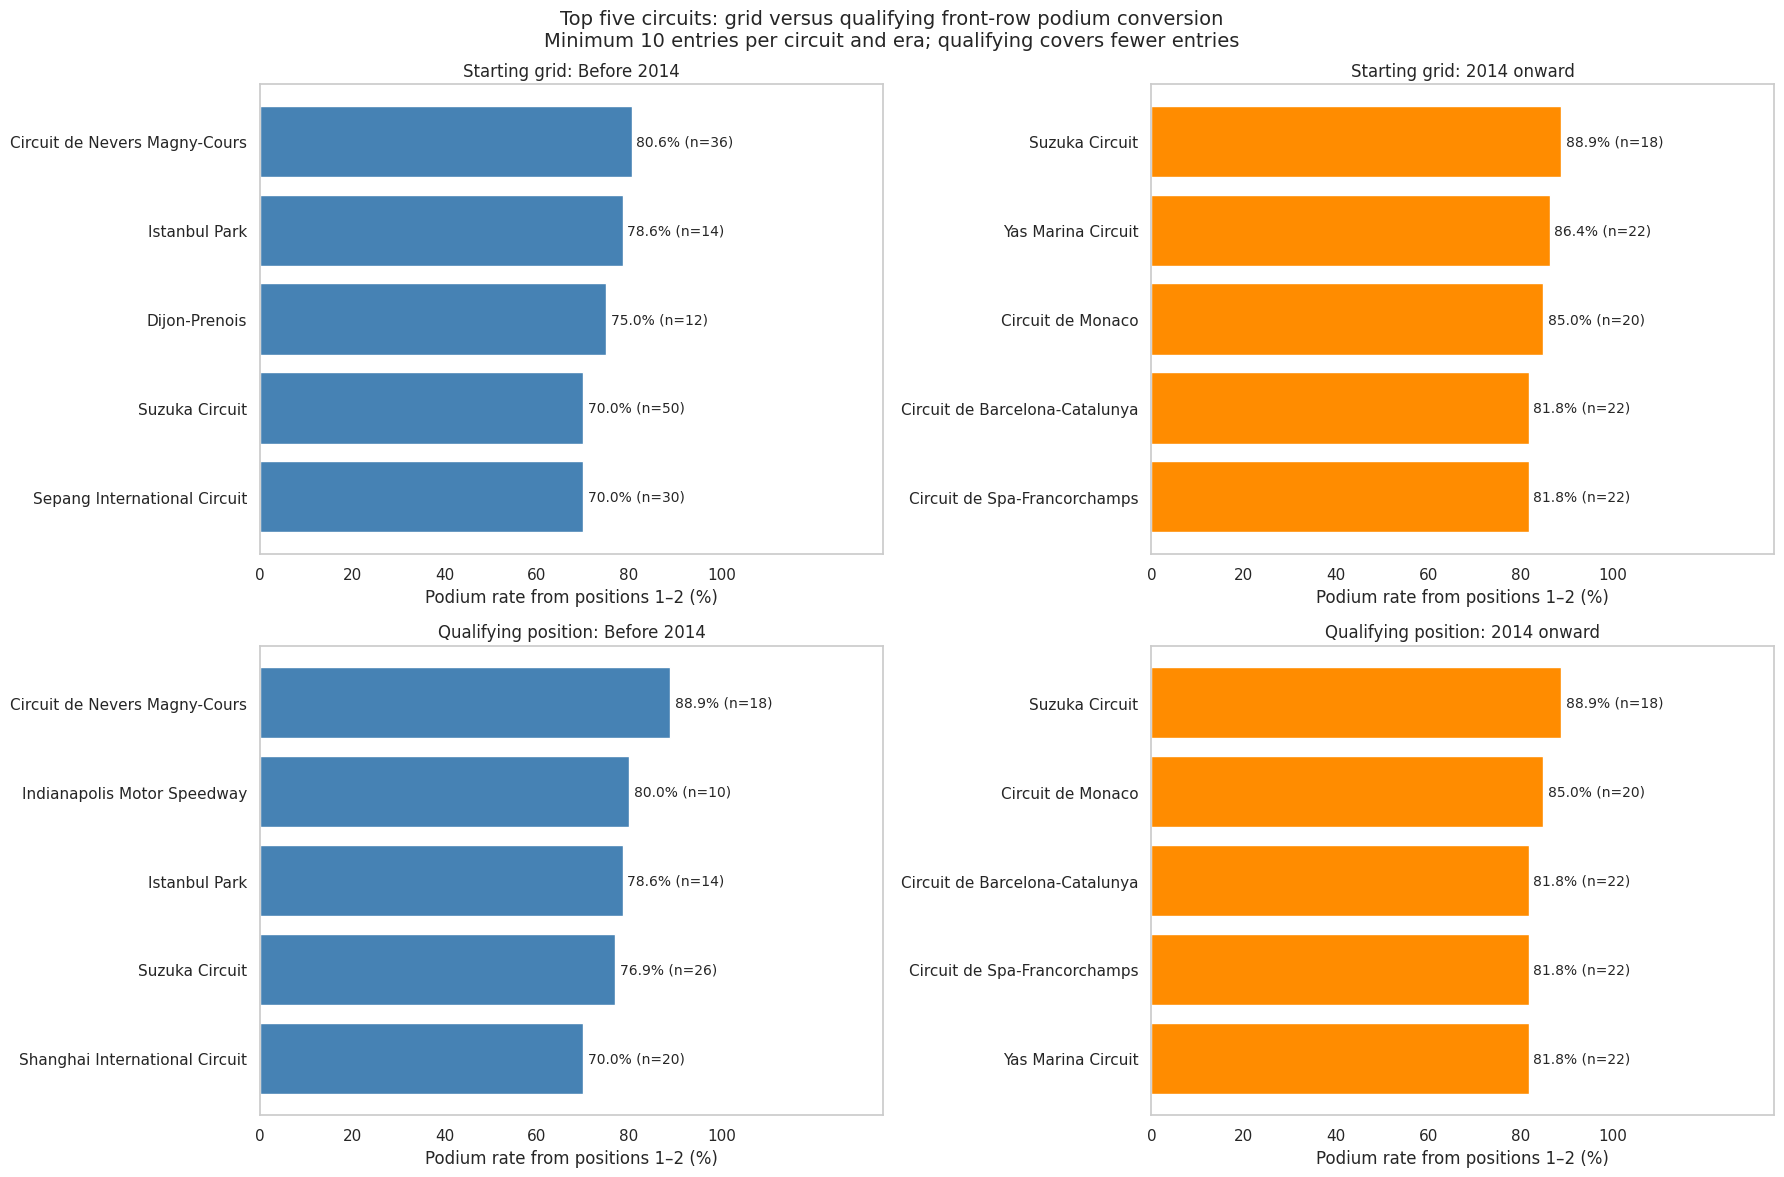

In [76]:
# QUESTION 1: Which circuits turn front-row starts into podiums most often?

# 1. Join only the information needed
q1 = (
    results[
        ['raceId', 'driverId', 'grid', 'positionOrder', 'statusId', 'laps']
    ]
    .merge(
        races[['raceId', 'year', 'circuitId']],
        on='raceId', how='left', validate='many_to_one'
    )
    .merge(
        circuits[['circuitId', 'name']],
        on='circuitId', how='left', validate='many_to_one'
    )
    .merge(
        qualifying[['raceId', 'driverId', 'position']].rename(
            columns={'position': 'qualifying_position'}
        ),
        on=['raceId', 'driverId'],
        how='left', validate='one_to_one'
    )
)

assert len(q1) == len(results)
assert not q1[['raceId', 'driverId']].isna().any().any()
assert not q1.duplicated(['raceId', 'driverId']).any()


# 2. Check missing information and coverage
print('MISSING INFORMATION')
display(
    q1[['year', 'name', 'grid', 'qualifying_position', 'positionOrder']]
    .isna().sum().rename('Missing entries')
)

q1 = q1.dropna(
    subset=['year', 'circuitId', 'name', 'positionOrder']
).copy()

q1['era'] = np.where(
    q1['year'].lt(2014), 'Before 2014', '2014 onward'
)

q1['podium'] = q1['positionOrder'].le(3).astype(int)
q1['valid_grid'] = q1['grid'].gt(0)
q1['valid_qualifying'] = q1['qualifying_position'].gt(0)

print('STARTING-POSITION COVERAGE: COUNTS ARE DRIVER–RACE ENTRIES')
display(
    q1.groupby('era').agg(
        entries=('driverId', 'size'),
        valid_grid=('valid_grid', 'sum'),
        valid_qualifying=('valid_qualifying', 'sum')
    )
)


# NEW: Exclude explicit non-starts before the charts and podium calculations.
# Looking up the relevant status IDs avoids adding another join.
nonstart_ids = status.loc[
    status['status'].isin({
        'Did not qualify',
        'Did not prequalify',
        'Withdrew',
        '107% Rule'
    }),
    'statusId'
]

q1_nonstart = (
    q1['statusId'].isin(nonstart_ids)
    & q1['laps'].eq(0)
)

print(
    'Explicit non-start entries excluded from subsequent analyses:',
    int(q1_nonstart.sum())
)

q1 = q1.loc[~q1_nonstart].copy()


# 3. Visualize qualifying versus grid across all matched entries
paired = q1.loc[
    q1['valid_grid'] & q1['valid_qualifying']
].copy()

# Qualified 3rd, started 8th -> +5 places further back.
# Qualified 8th, started 6th -> -2 places, meaning forward.
paired['position_change'] = (
    paired['grid'] - paired['qualifying_position']
)

print(
    f'Grid / qualifying chart: {len(paired):,} matched entries; '
    f'{len(q1) - len(paired):,} entries without two positive '
    'positions excluded.'
)

movement_counts = pd.Series({
    'Started further forward': paired['position_change'].lt(0).sum(),
    'Same position': paired['position_change'].eq(0).sum(),
    'Started further back': paired['position_change'].gt(0).sum()
})

movement_pct = 100 * movement_counts / len(paired)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

axes[0].barh(
    movement_pct.index,
    movement_pct.values,
    color=['#16866b', '#64748b', '#df8135']
)

axes[0].invert_yaxis()
axes[0].set(
    title='How often did the starting position change?',
    xlabel='Share of matched entries (%)',
    xlim=(0, 125)
)
axes[0].set_xticks([0, 20, 40, 60, 80, 100])

for y, (label, value) in enumerate(movement_pct.items()):
    axes[0].text(
        value + 1, y,
        f'{value:.1f}% (n={int(movement_counts[label]):,})',
        va='center'
    )

change_counts = (
    paired.loc[paired['position_change'].ne(0), 'position_change']
    .value_counts()
    .sort_index()
)

axes[1].bar(
    change_counts.index,
    change_counts.values,
    color=[
        '#16866b' if change < 0 else '#df8135'
        for change in change_counts.index
    ]
)

axes[1].axvline(
    0, color='#334155', linestyle='--', linewidth=1
)

axes[1].set(
    title='When it changed, how many places did the driver move?',
    xlabel='Places moved: negative = forward; positive = back',
    ylabel='Driver–race entries'
)

for ax in axes:
    ax.grid(False)

fig.suptitle(
    'Qualifying position versus starting grid: all available years',
    fontsize=14
)

plt.tight_layout()
plt.show()

print(
    'These charts show recorded position differences. '
    'A difference does not necessarily mean a penalty.'
)


# 4. Calculate conversion from grid positions 1 and 2
# Missing qualifying information does not remove an entry here.
front_row = q1.loc[q1['grid'].isin([1, 2])].copy()

q1_summary = (
    front_row.groupby(['circuitId', 'name', 'era'])
    .agg(
        entries=('podium', 'size'),
        podiums=('podium', 'sum')
    )
    .reset_index()
)

q1_summary['podium_rate_pct'] = (
    100 * q1_summary['podiums'] / q1_summary['entries']
)

MIN_FRONT_ROW_ENTRIES = 10

q1_ranked = q1_summary.loc[
    q1_summary['entries'].ge(MIN_FRONT_ROW_ENTRIES)
].copy()

q1_ranked['rank'] = (
    q1_ranked.groupby('era')['podium_rate_pct']
    .rank(method='min', ascending=False)
    .astype(int)
)

q1_ranked = q1_ranked.sort_values(
    ['era', 'rank', 'entries', 'name'],
    ascending=[True, True, False, True]
)

print(
    'Circuit–era groups excluded from grid rankings for having '
    'fewer than 10 front-row entries:',
    int(q1_summary['entries'].lt(MIN_FRONT_ROW_ENTRIES).sum())
)


# 5. Show two short top-five tables and identify the leaders
for era in ['Before 2014', '2014 onward']:
    era_results = q1_ranked.loc[q1_ranked['era'].eq(era)]
    top = era_results.head(5)

    print(f'\nTOP 5 CIRCUITS USING STARTING GRID: {era.upper()}')

    display(
        top[
            ['rank', 'name', 'entries', 'podiums', 'podium_rate_pct']
        ]
        .rename(columns={
            'rank': 'Rank',
            'name': 'Circuit',
            'entries': 'Front-row entries',
            'podiums': 'Podium finishes',
            'podium_rate_pct': 'Podium rate (%)'
        })
        .round(2)
        .reset_index(drop=True)
    )

    leaders = era_results.loc[era_results['rank'].eq(1)]

    for _, leader in leaders.iterrows():
        print(
            f"Highest rate — {leader['name']}: "
            f"{leader['podium_rate_pct']:.1f}% "
            f"({int(leader['podiums'])} podiums from "
            f"{int(leader['entries'])} front-row entries)."
        )


# 6. Compare the same tracks before and after 2014
era_counts = q1_ranked.groupby('circuitId')['era'].nunique()
shared_ids = era_counts.loc[era_counts.eq(2)].index

shared = q1_ranked.loc[
    q1_ranked['circuitId'].isin(shared_ids)
].copy()

shared['shared_rank'] = (
    shared.groupby('era')['podium_rate_pct']
    .rank(method='min', ascending=False)
)

rate_table = shared.pivot(
    index=['circuitId', 'name'],
    columns='era',
    values='podium_rate_pct'
)

rank_table = shared.pivot(
    index=['circuitId', 'name'],
    columns='era',
    values='shared_rank'
)

q1_comparison = pd.DataFrame({
    'Before 2014: podium %': rate_table['Before 2014'],
    '2014 onward: podium %': rate_table['2014 onward'],
    'Rate change (percentage points)': (
        rate_table['2014 onward'] - rate_table['Before 2014']
    ),
    'Before 2014: rank': rank_table['Before 2014'].astype(int),
    '2014 onward: rank': rank_table['2014 onward'].astype(int)
})

q1_comparison = (
    q1_comparison.reset_index()
    .drop(columns='circuitId')
    .rename(columns={'name': 'Circuit'})
    .sort_values(['2014 onward: rank', 'Circuit'])
)

print('\nSAME TRACKS IN BOTH ERAS: RANK 1 = HIGHEST PODIUM RATE')
display(q1_comparison.round(2).reset_index(drop=True))


# 7. Calculate conversion from qualifying positions 1 and 2 separately
qualifying_front_row = q1.loc[
    q1['qualifying_position'].isin([1, 2])
].copy()

q1_qualifying_summary = (
    qualifying_front_row.groupby(['circuitId', 'name', 'era'])
    .agg(
        entries=('podium', 'size'),
        podiums=('podium', 'sum')
    )
    .reset_index()
)

q1_qualifying_summary['podium_rate_pct'] = (
    100
    * q1_qualifying_summary['podiums']
    / q1_qualifying_summary['entries']
)

q1_qualifying_ranked = q1_qualifying_summary.loc[
    q1_qualifying_summary['entries'].ge(MIN_FRONT_ROW_ENTRIES)
].copy()

q1_qualifying_ranked['rank'] = (
    q1_qualifying_ranked.groupby('era')['podium_rate_pct']
    .rank(method='min', ascending=False)
    .astype(int)
)

q1_qualifying_ranked = q1_qualifying_ranked.sort_values(
    ['era', 'rank', 'entries', 'name'],
    ascending=[True, True, False, True]
)


# 8. Four plots: starting grid above, qualifying position below
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for row, (ranking, basis) in enumerate([
    (q1_ranked, 'Starting grid'),
    (q1_qualifying_ranked, 'Qualifying position')
]):
    for col, (era, color) in enumerate([
        ('Before 2014', 'steelblue'),
        ('2014 onward', 'darkorange')
    ]):
        top = ranking.loc[ranking['era'].eq(era)].head(5)
        ax = axes[row, col]

        ax.barh(
            top['name'],
            top['podium_rate_pct'],
            color=color
        )

        ax.invert_yaxis()
        ax.set(
            title=f'{basis}: {era}',
            xlabel='Podium rate from positions 1–2 (%)',
            xlim=(0, 135)
        )
        ax.set_xticks([0, 20, 40, 60, 80, 100])
        ax.grid(False)

        for y, (_, entry) in enumerate(top.iterrows()):
            ax.text(
                entry['podium_rate_pct'] + 1, y,
                f"{entry['podium_rate_pct']:.1f}% "
                f"(n={int(entry['entries'])})",
                va='center',
                fontsize=10
            )

fig.suptitle(
    'Top five circuits: grid versus qualifying front-row podium conversion\n'
    'Minimum 10 entries per circuit and era; qualifying covers fewer entries',
    fontsize=14
)

plt.tight_layout()
plt.show()

**Answer to Question 1**

- **Before 2014**, the circuits where front-row starters most often reached the podium
  were Magny-Cours (**80.6%**), Istanbul Park (**78.6%**) and Dijon-Prenois (**75%**).
- **From 2014 onward**, the leaders were Suzuka (**88.9%**), Yas Marina (**86.4%**) and
  Monaco (**85%**).
- **The ranking changed** between the eras. Among circuits with enough races in both
  periods, Monaco rose from **15th to 3rd** and the Hungaroring fell from **2nd to 16th**.
- **Qualifying vs grid:** the two positions differed in **23.3%** of the **10,407** entries
  that have both, so they are shown separately.

How it was calculated:
- Each row is one driver in one race, and the joins keep it that way.
- A circuit needs at least **10 front-row starts** in an era to be ranked, so a few lucky
  races do not decide the ranking.
- The **16,174** entries with no qualifying position are left out of the qualifying-based
  results only. Grid 0 (pit-lane start) is left out of the grid-based results.
- Qualifying data covers fewer old races than grid data, so differences between the two
  charts are not only caused by penalties.
- Race results are used here to *measure* podiums, never as predictors.

### Question 2 · Do drivers reach the podium more often at their home race?

Do drivers reach the podium more often at a circuit in their own country than elsewhere,
when compared with drivers who started from the **same grid positions**? (Otherwise,
home drivers would look better simply if they happened to qualify better.)

EXCLUSIONS: THESE COUNTS CAN OVERLAP


,Entries
Indianapolis 500 entries,381
Missing required information,4
Zero or negative grid,"1,635"


NATIONALITIES WITHOUT AN UNAMBIGUOUS COUNTRY MAPPING


,Entries
nationality,
American-Italian,2
Argentine-Italian,2


Explicit non-starts excluded after the above filters: 79
Entries excluded because their grid position has no comparison group: 2
PODIUM RATES AND SAMPLE SIZES AT THE SAME GRID POSITION


,grid,location,entries,podiums,podium_rate_pct
0,1,Away,"1,031",668,64.79
1,1,Home,81,49,60.49
2,2,Away,"1,030",580,56.31
3,2,Home,75,42,56
4,3,Away,"1,041",477,45.82
5,3,Home,73,40,54.79
6,4,Away,"1,042",359,34.45
7,4,Home,73,27,36.99
8,5,Away,"1,038",256,24.66
9,5,Home,70,23,32.86


OVERALL PODIUM RATES AFTER CONTROLLING FOR GRID POSITION


,Adjusted podium rate (%)
location,
Home,13.57
Away,13.69


Home minus Away: -0.12 percentage points


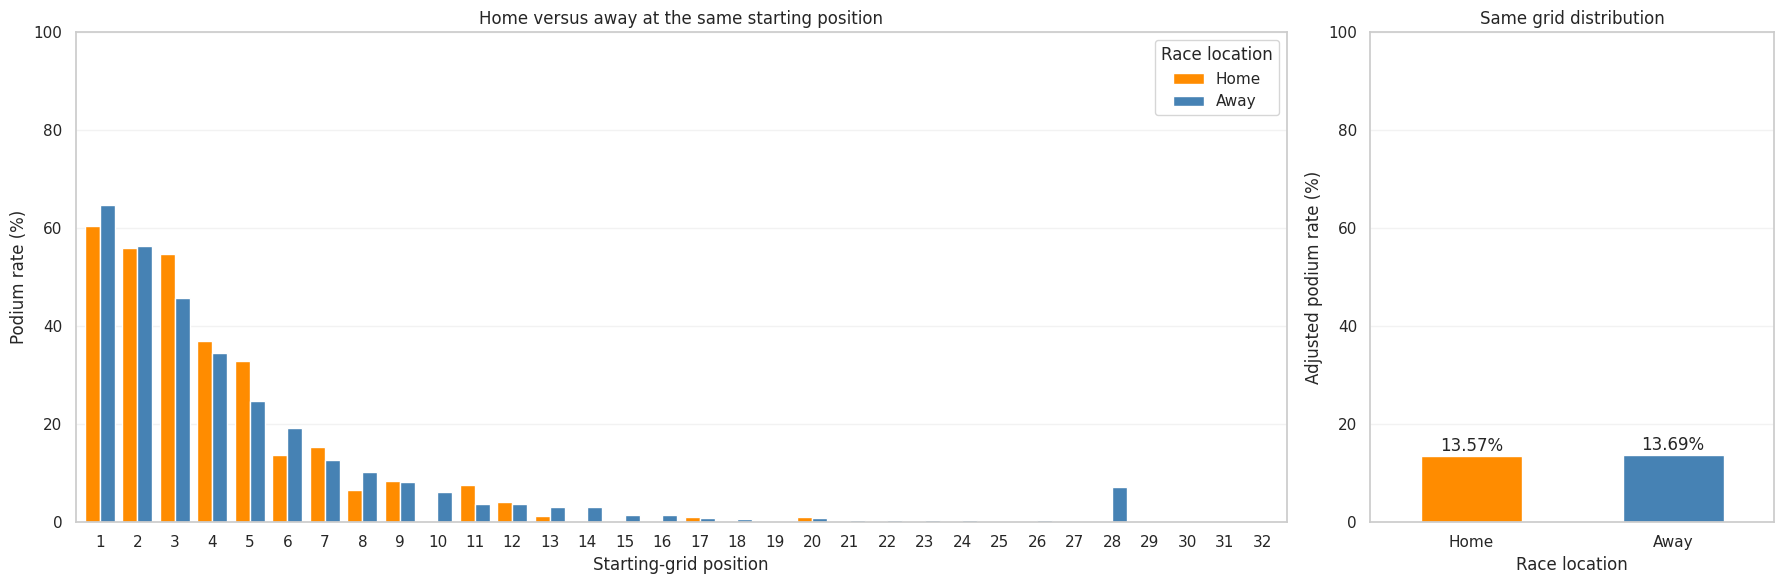

In [77]:
# 1. Join only the information needed for this question
q2 = (
    results[
        ['raceId', 'driverId', 'grid', 'positionOrder', 'statusId', 'laps']
    ]
    .merge(
        races[['raceId', 'year', 'name', 'circuitId']],
        on='raceId', how='left', validate='many_to_one'
    )
    .merge(
        circuits[['circuitId', 'country']],
        on='circuitId', how='left', validate='many_to_one'
    )
    .merge(
        drivers[['driverId', 'nationality']],
        on='driverId', how='left', validate='many_to_one'
    )
)

assert len(q2) == len(results)
assert not q2[['raceId', 'driverId']].isna().any().any()
assert not q2.duplicated(['raceId', 'driverId']).any()


# 2. Convert nationality labels into country names
# Nationality is used as a proxy for home country.
# Dual nationalities stay unmapped rather than choosing a country.
nationality_to_country = {
    'American': 'USA',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czechia',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

q2['driver_country'] = (
    q2['nationality'].str.strip().map(nationality_to_country)
)


# 3. Report exclusions
indy = (
    q2['name'].eq('Indianapolis 500')
    & q2['year'].between(1950, 1960)
)

required = [
    'year', 'name', 'country',
    'driver_country', 'grid', 'positionOrder'
]

print('EXCLUSIONS: THESE COUNTS CAN OVERLAP')
display(
    pd.Series({
        'Indianapolis 500 entries': int(indy.sum()),
        'Missing required information': int(
            q2[required].isna().any(axis=1).sum()
        ),
        'Zero or negative grid': int(q2['grid'].le(0).sum())
    }, name='Entries')
)

print('NATIONALITIES WITHOUT AN UNAMBIGUOUS COUNTRY MAPPING')
display(
    q2.loc[q2['driver_country'].isna(), 'nationality']
    .value_counts(dropna=False)
    .rename('Entries')
)

q2 = q2.loc[~indy].dropna(subset=required).copy()
q2 = q2.loc[q2['grid'].gt(0)].copy()


# NEW: Exclude explicit non-starts; retain other zero-lap entries.
# Looking up the relevant status IDs avoids adding another join.
nonstart_ids = status.loc[
    status['status'].isin({
        'Did not qualify',
        'Did not prequalify',
        'Withdrew',
        '107% Rule'
    }),
    'statusId'
]

q2_nonstart = (
    q2['statusId'].isin(nonstart_ids)
    & q2['laps'].eq(0)
)

print(
    'Explicit non-starts excluded after the above filters:',
    int(q2_nonstart.sum())
)

q2 = q2.loc[~q2_nonstart].copy()


q2['location'] = np.where(
    q2['country'].eq(q2['driver_country']),
    'Home',
    'Away'
)

q2['podium'] = q2['positionOrder'].le(3).astype(int)


# 4. Compare Home and Away at each exact grid position
q2_by_grid = (
    q2.groupby(['grid', 'location'])
    .agg(
        entries=('podium', 'size'),
        podiums=('podium', 'sum')
    )
    .reset_index()
)

q2_by_grid['podium_rate_pct'] = (
    100 * q2_by_grid['podiums'] / q2_by_grid['entries']
)

counts = q2_by_grid.pivot(
    index='grid', columns='location', values='entries'
)

rates = q2_by_grid.pivot(
    index='grid', columns='location', values='podium_rate_pct'
)

# Use only positions where both Home and Away observations exist.
common_grid = counts.dropna(subset=['Home', 'Away']).index

print(
    'Entries excluded because their grid position has no comparison group:',
    int((~q2['grid'].isin(common_grid)).sum())
)

q2_by_grid = q2_by_grid.loc[
    q2_by_grid['grid'].isin(common_grid)
].copy()

print('PODIUM RATES AND SAMPLE SIZES AT THE SAME GRID POSITION')
display(q2_by_grid.round(2))


# 5. Calculate an overall comparison with the same grid distribution
weights = counts.loc[common_grid, ['Home', 'Away']].sum(axis=1)
weights = weights / weights.sum()

adjusted_rates = (
    rates.loc[common_grid, ['Home', 'Away']]
    .mul(weights, axis=0)
    .sum()
)

print('OVERALL PODIUM RATES AFTER CONTROLLING FOR GRID POSITION')
display(
    adjusted_rates.rename('Adjusted podium rate (%)').round(2)
)

difference = adjusted_rates['Home'] - adjusted_rates['Away']
print(f'Home minus Away: {difference:+.2f} percentage points')


# 6. Plot the exact-grid comparison and adjusted overall rates
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6),
    gridspec_kw={'width_ratios': [3, 1]}
)

plot_rates = rates.loc[common_grid, ['Home', 'Away']].copy()
plot_rates.index = plot_rates.index.astype(int)

plot_rates.plot.bar(
    ax=axes[0],
    color=['darkorange', 'steelblue'],
    width=0.8
)

axes[0].set(
    title='Home versus away at the same starting position',
    xlabel='Starting-grid position',
    ylabel='Podium rate (%)',
    ylim=(0, 100)
)

axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Race location')
axes[0].grid(axis='y', alpha=0.25)
axes[0].grid(axis='x', visible=False)

adjusted_rates.plot.bar(
    ax=axes[1],
    color=['darkorange', 'steelblue'],
    rot=0
)

axes[1].set(
    title='Same grid distribution',
    xlabel='Race location',
    ylabel='Adjusted podium rate (%)',
    ylim=(0, 100)
)

axes[1].grid(axis='y', alpha=0.25)
axes[1].grid(axis='x', visible=False)

for x, value in enumerate(adjusted_rates):
    axes[1].text(
        x, value + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

**Answer to Question 2**

- **No overall home advantage was found.** After matching drivers by starting position,
  the podium rate was **13.52% at home** and **13.65% away**, a difference of only
  **−0.13 percentage points**.
- **Individual grid positions are mixed** (left chart). From grid P3, home drivers
  reached the podium more often (**54.79% vs 45.78%**); from P6 less often (**13.75% vs
  19.18%**).
- **The right chart** combines all grid positions using the same mix of starting
  positions for both groups, and the two rates come out almost identical.

How it was calculated:
- A driver's nationality is matched to the circuit's country to decide "home".
- **4 entries** with dual nationalities were left out instead of guessing a country.
- Grid 0 or negative grid values were left out because they are not normal starting
  slots.
- The **381** historical Indianapolis 500 entries were left out, because those races had
  a largely separate set of drivers.
- Only grid positions that appear in both groups are compared. Home groups are smaller,
  so their rates move more by chance.
- Matching on grid does not control for team, driver or year, so this does not prove
  that racing at home has no effect at all.

### Question 3 · Which constructors have the highest mechanical-retirement rate?

Which constructors had the highest share of races ended by a car failure in 2014–2021,
and which in 2022–2024?

MISSING INFORMATION WITHIN 2014-2024


,Missing entries
name,0
status,0
laps,0


RACE-START DENOMINATOR CHECK


,recorded_entries,excluded_nonstarts,other_zero_lap_entries
era,,,
2014-2021,"3,267",7,97
2022-2024,"1,359",4,32


STATUS CLASSIFICATION: 1 = INCLUDED AS MECHANICAL, 0 = NOT INCLUDED


status,mechanical,Entries
+1 Lap,0,"1,178"
+2 Laps,0,208
+3 Laps,0,24
+4 Laps,0,6
+5 Laps,0,1
+6 Laps,0,2
+7 Laps,0,1
+8 Laps,0,2
Accident,0,85
Battery,1,5


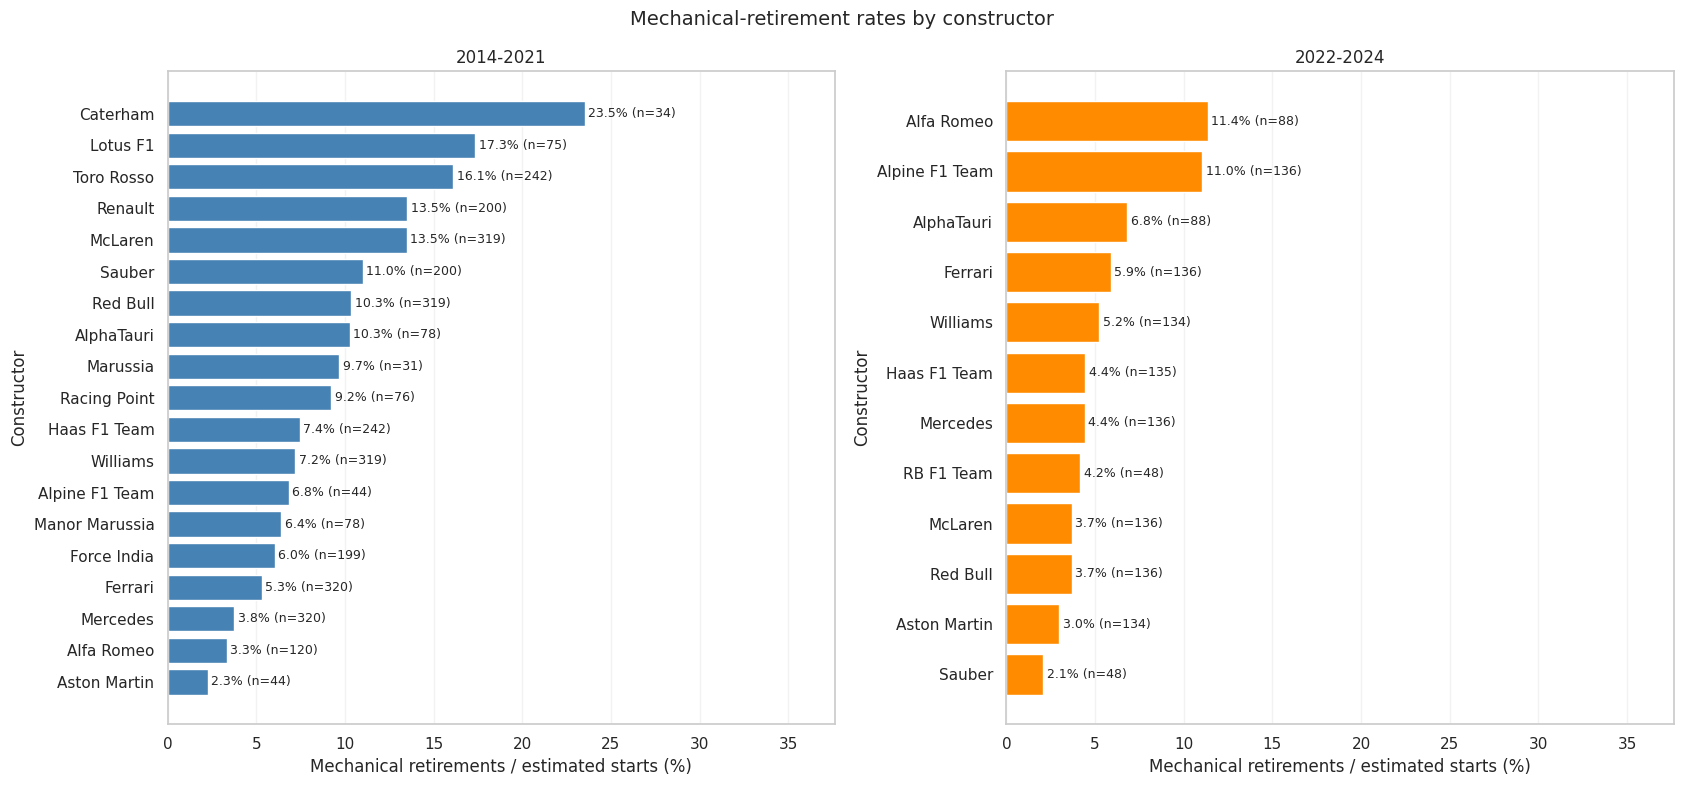

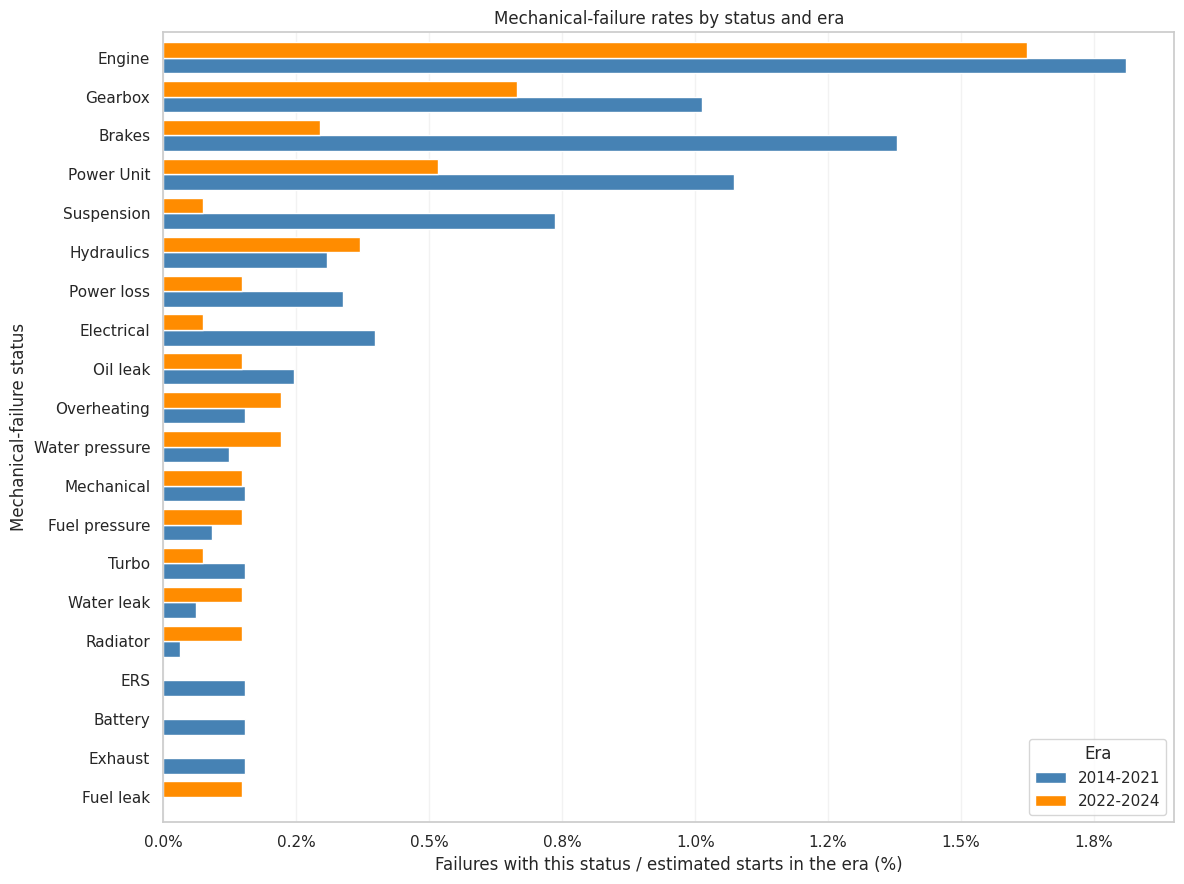

In [78]:
# QUESTION 3: Mechanical-retirement rates by constructor and era

# 1. Join only the required information
q3 = (
    results[['raceId', 'driverId', 'constructorId', 'statusId', 'laps']]
    .merge(
        races[['raceId', 'year']],
        on='raceId', how='left', validate='many_to_one'
    )
    .merge(
        status[['statusId', 'status']],
        on='statusId', how='left', validate='many_to_one'
    )
    .merge(
        constructors[['constructorId', 'name']],
        on='constructorId', how='left', validate='many_to_one'
    )
)

assert len(q3) == len(results)
assert not q3[['raceId', 'driverId']].isna().any().any()
assert not q3.duplicated(['raceId', 'driverId']).any()
assert q3['year'].notna().all(), 'Some entries cannot be assigned to an era.'

q3 = q3.loc[q3['year'].between(2014, 2024)].copy()

q3['era'] = np.where(
    q3['year'].le(2021),
    '2014-2021',
    '2022-2024'
)


# TABLE 1: Missing information
print('MISSING INFORMATION WITHIN 2014-2024')
display(
    q3[['name', 'status', 'laps']]
    .isna().sum().rename('Missing entries')
)

q3 = q3.dropna(subset=['name', 'status', 'laps']).copy()


# 2. Identify explicit non-starts
# Other zero-lap records stay because they can be first-lap retirements.
nonstart_statuses = {
    'Did not qualify',
    'Did not prequalify',
    'Withdrew',
    '107% Rule'
}

q3['nonstart'] = (
    q3['status'].isin(nonstart_statuses)
    & q3['laps'].eq(0)
)

q3['zero_lap_uncertain'] = (
    q3['laps'].eq(0)
    & ~q3['nonstart']
)


# TABLE 2: Race-start denominator check
print('RACE-START DENOMINATOR CHECK')
display(
    q3.groupby('era').agg(
        recorded_entries=('driverId', 'size'),
        excluded_nonstarts=('nonstart', 'sum'),
        other_zero_lap_entries=('zero_lap_uncertain', 'sum')
    )
)

q3 = q3.loc[~q3['nonstart']].copy()


# 3. Apply the same status classification to every retained entry
# Vague labels such as Retired and Technical are not counted as
# confirmed mechanical failures.
mechanical_statuses = {
    'Engine', 'Gearbox', 'Transmission', 'Clutch',
    'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
    'Brakes', 'Differential', 'Overheating', 'Mechanical',
    'Driveshaft', 'Fuel pressure', 'Water pressure', 'Throttle',
    'Steering', 'Electronics', 'Exhaust', 'Oil leak',
    'Water leak', 'Fuel pump', 'Oil pressure', 'Fuel system',
    'Power loss', 'Drivetrain', 'Battery', 'Fuel leak',
    'Turbo', 'Water pump', 'Spark plugs', 'Power Unit',
    'ERS', 'Brake duct', 'Cooling system'
}

q3['mechanical'] = (
    q3['status'].isin(mechanical_statuses).astype(int)
)


# TABLE 3: Status classification and frequencies
print(
    'STATUS CLASSIFICATION: '
    '1 = INCLUDED AS MECHANICAL, 0 = NOT INCLUDED'
)

display(
    q3.groupby(['status', 'mechanical'])
    .size()
    .reset_index(name='Entries')
)


# 4. Calculate mechanical-retirement rates per constructor and era
q3_summary = (
    q3.groupby(['constructorId', 'name', 'era'])
    .agg(
        estimated_starts=('driverId', 'size'),
        mechanical_retirements=('mechanical', 'sum')
    )
    .reset_index()
)

q3_summary['mechanical_rate_pct'] = (
    100
    * q3_summary['mechanical_retirements']
    / q3_summary['estimated_starts']
)

q3_summary = q3_summary.sort_values(
    ['era', 'mechanical_rate_pct', 'name'],
    ascending=[True, False, True]
)


# PLOTS 1 AND 2: Constructor rates in each era
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

maximum_rate = q3_summary['mechanical_rate_pct'].max()

for ax, era, color in zip(
    axes,
    ['2014-2021', '2022-2024'],
    ['steelblue', 'darkorange']
):
    part = q3_summary.loc[q3_summary['era'].eq(era)]

    ax.barh(
        part['name'],
        part['mechanical_rate_pct'],
        color=color
    )

    ax.invert_yaxis()
    ax.set(
        title=era,
        xlabel='Mechanical retirements / estimated starts (%)',
        ylabel='Constructor',
        xlim=(0, maximum_rate * 1.6)
    )

    ax.grid(axis='x', alpha=0.25)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(True)

    for y, (_, entry) in enumerate(part.iterrows()):
        ax.text(
            entry['mechanical_rate_pct'] + 0.2,
            y,
            f"{entry['mechanical_rate_pct']:.1f}% "
            f"(n={int(entry['estimated_starts'])})",
            va='center',
            fontsize=9
        )

fig.suptitle(
    'Mechanical-retirement rates by constructor',
    fontsize=14
)

plt.tight_layout()
plt.show()


# PLOT 3: Mechanical-failure statuses as a percentage of starts in each era
from matplotlib.ticker import PercentFormatter

# Count failures by status and era.
mechanical_counts = (
    q3.loc[q3['mechanical'].eq(1)]
    .groupby(['status', 'era'])
    .size()
    .unstack('era', fill_value=0)
    .reindex(
        columns=['2014-2021', '2022-2024'],
        fill_value=0
    )
)

# Denominator: ALL estimated starts in each era, including non-failures.
era_starts = (
    q3.groupby('era')
    .size()
    .reindex(['2014-2021', '2022-2024'])
)

# Divide each era's failure counts by that era's estimated starts.
mechanical_rates = (
    mechanical_counts
    .div(era_starts, axis='columns')
    .mul(100)
)

# Choose the top 20 using the average percentage across the two eras.
# This gives both eras equal weight when selecting the displayed statuses.
plot_order = (
    mechanical_rates.mean(axis=1)
    .nlargest(20)
    .sort_values()
    .index
)

plot_statuses = mechanical_rates.loc[plot_order]

ax = plot_statuses.plot.barh(
    figsize=(12, 9),
    color=['steelblue', 'darkorange'],
    width=0.8
)

ax.set(
    title='Mechanical-failure rates by status and era',
    xlabel='Failures with this status / estimated starts in the era (%)',
    ylabel='Mechanical-failure status'
)

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=1)
)

ax.legend(title='Era')
ax.grid(axis='x', alpha=0.25)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Answer to Question 3**

- **2014–2021:** Caterham had the highest estimated mechanical-retirement rate,
  **23.5%** (8 failures in 34 estimated starts), followed by Lotus F1 (**17.3%**) and
  Toro Rosso (**16.1%**).
- **2022–2024:** Alfa Romeo was highest at **11.4%** (10 failures in 88 estimated starts),
  followed by Alpine (**11.0%**) and AlphaTauri (**6.8%**).
- **Sample size matters:** Caterham's figure is based on few starts, so it is less
  certain than the others.
- The last chart compares individual failure types (engine, gearbox and so on) as a
  share of all starts in each era, so the two eras can be compared despite different
  numbers of races.

How it was calculated:
- A **mechanical retirement** is a start that ended because a part of the car failed.
  Crashes, driver errors and rule decisions do not count. Vague labels such as "Retired"
  or "Technical" are also not counted, so a few real failures may be missed.
- Teams that changed names keep separate IDs and are not merged.
- There were no missing team names, status labels or lap counts in these seasons.
- **7 confirmed non-starts in 2014–2021 and 4 in 2022–2024** are excluded. The remaining
  **97 and 32 zero-lap entries** are kept because they include first-lap retirements, so
  the number of starts is an estimate.
- Race status and laps are after-race information. They are used here to describe
  history, never to predict the same race.

<a id="feature-selection"></a>
## 6. Feature selection and engineering

This section turns the cleaned tables into the **inputs (features)** the models will use.
Every feature only uses information that is already known **after qualifying and before
the race starts**. Anything from the race itself (finishing position, points scored,
laps, pit stops) is never used, because the model would then be "seeing the answer".

What happens, step by step:

- **6.1** Count how often each driver and team appears. This shows why the raw ID
  numbers are a poor input.
- **6.2** Replace each driver and team ID with **its podium rate in earlier races**.
- **6.3** Add **championship points before the race**, also as a share of the leader's
  points.
- **6.4** Describe the **circuit** with three numbers instead of its ID.
- **6.5** Define three **feature sets ("trials")** and the plotting tools.
- **6.6–6.8** Build each trial's table (features plus the `podium` target) and plot how
  each feature relates to the podium rate.
- **6.9** Summary of the three tables, which are handed over to Section 7.

Nothing is trained in this section. Splitting the data, preparing it for the models and
training all happen in Section 7.

### 6.1 How often each driver and team appears

The code below counts how many races each driver and each team (constructor) entered
across **all seasons (1950–2024)** and plots the 20 most frequent of each. A two-car team
normally counts twice per race.

The orange line marks a cut-off (`MIN_APPEARANCES`, currently **80 entries**). IDs below
it are grouped as `Other`.

**What this shows:** most drivers and teams appear only a handful of times. Giving every
ID its own yes/no column would create hundreds of mostly-empty columns that the models
could barely learn from. That is why 6.2 describes each driver and team with a single
number instead. The `Other` grouping is kept only for reference; the final feature
tables in 6.6–6.8 do **not** contain any raw IDs.

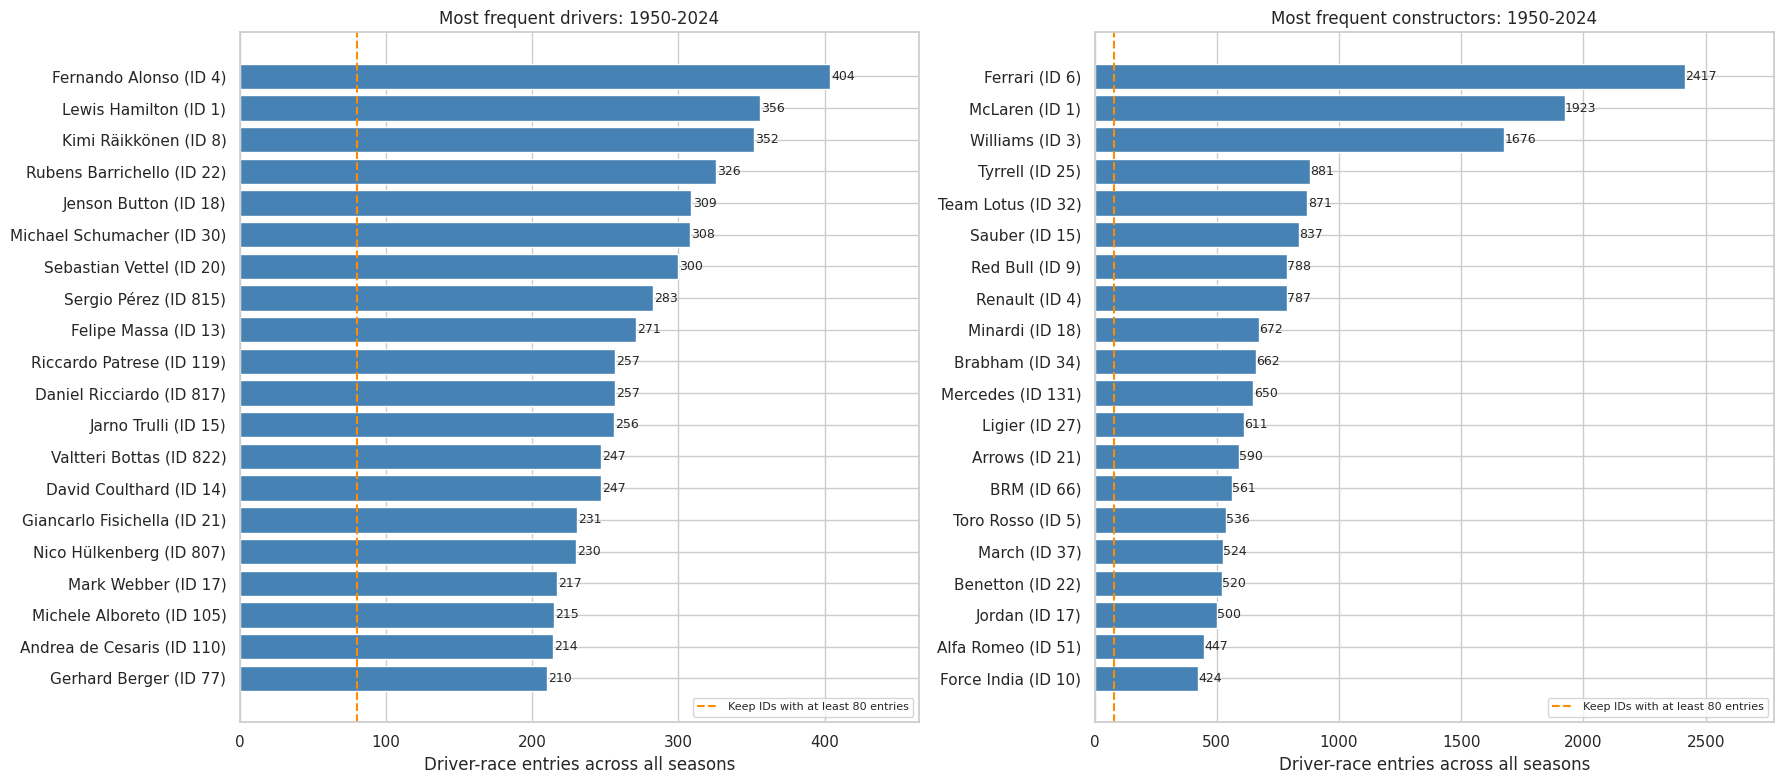

Column,Minimum appearances,Total IDs,IDs kept,IDs grouped as Other,Entries grouped as Other
driverId,80,861,112,749,"9,332"
constructorId,80,210,63,147,"2,612"


In [79]:
# Explore frequent identities and group rare IDs using all available seasons.
MIN_APPEARANCES = {
    'driverId': 80,
    'constructorId': 80
}

frequency_entries = results[['raceId', 'driverId', 'constructorId']].merge(
    races[['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
frequency_year_start = int(frequency_entries['year'].min())
frequency_year_end = int(frequency_entries['year'].max())

# Both frequencies count driver-race entries, matching the model's row unit.
# A two-driver constructor normally contributes two entries in one race.
id_frequencies = {
    column: frequency_entries[column].value_counts()
    for column in ['driverId', 'constructorId']
}

driver_names = drivers.assign(
    driver_name=drivers['forename'] + ' ' + drivers['surname']
).set_index('driverId')['driver_name']

constructor_names = constructors.set_index('constructorId')['name']

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, column, names, title in [
    (axes[0], 'driverId', driver_names, 'Most frequent drivers'),
    (axes[1], 'constructorId', constructor_names, 'Most frequent constructors')
]:
    threshold = MIN_APPEARANCES[column]

    # Show 20 for readability; the threshold considers every ID.
    top = id_frequencies[column].head(20).sort_values()
    labels = [
        f'{names.get(identity, str(identity))} (ID {identity})'
        for identity in top.index
    ]

    ax.barh(labels, top.to_numpy(), color='steelblue')

    for row, value in enumerate(top):
        ax.text(value + 0.8, row, str(value), va='center', fontsize=9)

    ax.axvline(
        threshold,
        color='darkorange',
        linestyle='--',
        label=f'Keep IDs with at least {threshold} entries'
    )

    ax.set(
        title=f'{title}: {frequency_year_start}-{frequency_year_end}',
        xlabel='Driver-race entries across all seasons',
        ylabel='',
        xlim=(0, max(float(top.max()) * 1.15, threshold * 1.3))
    )
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

frequent_ids = {
    column: set(counts.index[counts.ge(MIN_APPEARANCES[column])])
    for column, counts in id_frequencies.items()
}


def group_rare_ids(frame):
    # Apply the same full-dataset mapping without changing source tables or join keys.
    grouped = frame.copy()

    for column, kept_ids in frequent_ids.items():
        if column in grouped.columns:
            grouped[column] = grouped[column].astype(str).where(
                grouped[column].isin(kept_ids), 'Other'
            )

    return grouped


grouping_summary = pd.DataFrame([
    {
        'Column': column,
        'Minimum appearances': MIN_APPEARANCES[column],
        'Total IDs': len(counts),
        'IDs kept': len(frequent_ids[column]),
        'IDs grouped as Other': int(
            counts.lt(MIN_APPEARANCES[column]).sum()
        ),
        'Entries grouped as Other': int(
            counts.loc[counts.lt(MIN_APPEARANCES[column])].sum()
        )
    }
    for column, counts in id_frequencies.items()
])

display(grouping_summary)

### 6.2 Past podium rate for each driver and team

Each driver ID and team ID is replaced by **how often that driver (or team) reached the
podium in all earlier races**. To avoid extreme values for newcomers, the rate is pulled
towards the overall podium rate when there is little history:

$$\text{rate} = \frac{\text{earlier podiums} + 10 \times \text{overall podium rate}}{\text{earlier races} + 10}$$

The "+10" acts like 10 imaginary average races. A newcomer therefore starts at the
overall average, and the more real races they have, the more their own record counts.

**No peeking at the future:** races are processed in date order. Everyone in a race is
given their rate from **earlier dates only**, and only then is that race's result added
to the history. So neither the driver's own result nor a team-mate's result from the
same race can leak in. Before the very first race in the data, a fixed starting value of
0.15 (about 3 podiums for 20 cars) is used.

In [80]:
from collections import defaultdict

# Tune these independently using validation results.
DRIVER_SMOOTHING = 10.0
CONSTRUCTOR_SMOOTHING = 10.0

# Used only when no earlier race results exist.
# This is a fixed starting assumption, not calculated from future outcomes.
INITIAL_PODIUM_RATE = 0.15

assert DRIVER_SMOOTHING > 0 and CONSTRUCTOR_SMOOTHING > 0

encoded_entries = results[
    ['raceId', 'driverId', 'constructorId', 'podium']
].merge(
    races[['raceId', 'date']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

encoded_entries['date'] = pd.to_datetime(encoded_entries['date'])

assert not encoded_entries.duplicated(['raceId', 'driverId']).any()
assert not encoded_entries[
    ['driverId', 'constructorId', 'date', 'podium']
].isna().any().any()
assert encoded_entries['podium'].isin([0, 1]).all()

# Each identity stores: [earlier podiums, earlier driver-race entries].
history = {
    'driverId': defaultdict(lambda: [0, 0]),
    'constructorId': defaultdict(lambda: [0, 0])
}

total_podiums = 0
total_entries = 0

encoding_settings = [
    ('driverId', 'driver_podium_rate_pre_race', DRIVER_SMOOTHING),
    ('constructorId', 'constructor_podium_rate_pre_race',
     CONSTRUCTOR_SMOOTHING)
]

# Process chronologically. All entries on the same date are encoded together,
# before adding any of that date's outcomes to the history.
for race_date, current_entries in (
    encoded_entries.sort_values('date').groupby('date', sort=True)
):
    overall_rate = (
        total_podiums / total_entries
        if total_entries > 0
        else INITIAL_PODIUM_RATE
    )

    # Calculate BOTH encodings using only earlier dates.
    for identity_column, encoded_column, smoothing in encoding_settings:
        encoded_entries.loc[current_entries.index, encoded_column] = [
            (
                history[identity_column][identity][0]
                + smoothing * overall_rate
            )
            / (
                history[identity_column][identity][1]
                + smoothing
            )
            for identity in current_entries[identity_column]
        ]

    # Only after encoding everyone do we add the completed race outcomes.
    # This also prevents a teammate's current-race result from leaking.
    for identity_column in history:
        for identity, group in current_entries.groupby(identity_column):
            history[identity_column][identity][0] += int(
                group['podium'].sum()
            )
            history[identity_column][identity][1] += len(group)

    total_podiums += int(current_entries['podium'].sum())
    total_entries += len(current_entries)

TARGET_ENCODED_COLUMNS = {
    'driverId': 'driver_podium_rate_pre_race',
    'constructorId': 'constructor_podium_rate_pre_race'
}

past_target_encoding = encoded_entries[
    ['raceId', 'driverId', 'constructorId']
    + list(TARGET_ENCODED_COLUMNS.values())
].copy()


def encode_feature_table(frame, feature_columns):
    """Replace selected identity features with their past-only podium rates."""
    encoded = frame.copy()

    for identity_column, encoded_column in TARGET_ENCODED_COLUMNS.items():
        if identity_column in feature_columns:
            lookup = past_target_encoding[
                ['raceId', identity_column, encoded_column]
            ].drop_duplicates(['raceId', identity_column])

            encoded = encoded.merge(
                lookup,
                on=['raceId', identity_column],
                how='left',
                validate='many_to_one'
            )

    updated_features = [
        TARGET_ENCODED_COLUMNS.get(column, column)
        for column in feature_columns
    ]

    return encoded[updated_features].copy(), updated_features


display(past_target_encoding.head())

raceId,driverId,constructorId,driver_podium_rate_pre_race,constructor_podium_rate_pre_race
18,1,1,0.489,0.322
18,2,2,0.057,0.065
18,3,3,0.027,0.294
18,4,4,0.437,0.202
18,5,1,0.082,0.322


### 6.3 Championship points before the race

`driver_points_pre_race` and `constructor_points_pre_race` are the championship points
**after the previous round of the same season**, taken from the standings tables.
Using the previous round keeps the points from the current race out.

- Season openers and drivers making their first appearance of the season start at **0**.
- Team points before **1958** stay missing, because the Constructors' Championship did not
  exist yet.
- Sprint points from the same weekend are not included.

**Points as a share of the leader (used in the models).** The points system changed
several times. For example, a win was worth 10 points in 2003–2009 and 25 points from
2010, so "50 points" means very different things in 2005 and 2015. The models therefore
use each driver's (and team's) points **divided by the championship leader's points**
before the race:

- the leader has a share of 1.0;
- a driver with half the leader's points has 0.5;
- at a season opener, when nobody has points yet, every share is 0.

The raw points are also kept in the table for reference.

In [81]:
# PRE-RACE CHAMPIONSHIP POINTS (standings after the previous round)
STANDINGS_FEATURES = ['driver_points_pre_race', 'constructor_points_pre_race']

# Match each entry to the previous round's standings within the same season.
calendar = races[['raceId', 'year', 'round']].sort_values(['year', 'round']).copy()
calendar['previous_raceId'] = calendar.groupby('year')['raceId'].shift().astype('Int64')
pre_race_standings = results[['raceId', 'driverId', 'constructorId']].merge(
    calendar, on='raceId', how='left', validate='many_to_one')

for entity, standings, feature, first_year in [
    ('driverId', driver_standings, 'driver_points_pre_race', 1950),
    ('constructorId', constructor_standings, 'constructor_points_pre_race', 1958)
]:
    lookup = standings[['raceId', entity, 'points']].rename(
        columns={'raceId': 'previous_raceId', 'points': feature})
    lookup['_snapshot_present'] = True
    pre_race_standings = pre_race_standings.merge(
        lookup, on=['previous_raceId', entity], how='left', validate='many_to_one')
    first_entry = pre_race_standings['round'].eq(
        pre_race_standings.groupby(['year', entity])['round'].transform('min'))
    debut_zero = (first_entry & ~pre_race_standings['_snapshot_present'].eq(True)
        & pre_race_standings['previous_raceId'].isin(standings['raceId']))
    championship_exists = pre_race_standings['year'].ge(first_year)
    known_zero = championship_exists & (pre_race_standings['round'].eq(1) | debut_zero)
    pre_race_standings.loc[known_zero, feature] = 0.0
    pre_race_standings.loc[~championship_exists, feature] = np.nan
    pre_race_standings = pre_race_standings.drop(columns='_snapshot_present')

# Era-comparable version: points as a share of the leader's points before the race.
STANDINGS_SHARE_FEATURES = ['driver_points_share_pre_race',
                            'constructor_points_share_pre_race']
for standings, points_column, share_column in [
    (driver_standings, 'driver_points_pre_race', 'driver_points_share_pre_race'),
    (constructor_standings, 'constructor_points_pre_race',
     'constructor_points_share_pre_race')
]:
    leader_points = standings.groupby('raceId')['points'].max()
    leader_before_race = pre_race_standings['previous_raceId'].map(leader_points)
    points = pre_race_standings[points_column]
    pre_race_standings[share_column] = points / leader_before_race.where(
        leader_before_race > 0)
    # Nobody has scored yet (openers) or the entry has 0 points: share is a known 0.
    pre_race_standings.loc[points.eq(0), share_column] = 0.0
    # Missing points (e.g. constructors before 1958) stay missing.
    pre_race_standings.loc[points.isna(), share_column] = np.nan

pre_race_standings = pre_race_standings[
    ['raceId', 'driverId'] + STANDINGS_FEATURES + STANDINGS_SHARE_FEATURES]
assert not pre_race_standings.duplicated(['raceId', 'driverId']).any()
shares = pre_race_standings[STANDINGS_SHARE_FEATURES]
assert shares.dropna().ge(0).all().all() and shares.dropna().le(1 + 1e-9).all().all()

display(pre_race_standings[STANDINGS_FEATURES + STANDINGS_SHARE_FEATURES]
        .describe().round(3))

,driver_points_pre_race,constructor_points_pre_race,driver_points_share_pre_race,constructor_points_share_pre_race
count,"26,218","24,988","26,218","24,988"
mean,17.119,36.416,0.181,0.263
std,41.029,80.902,0.276,0.331
min,0,0,0,0
25%,0,0,0,0
50%,2,8,0.038,0.105
75%,14,33,0.25,0.429
max,549,822,1,1


### 6.4 Describing the circuit with three numbers

Giving each circuit a podium rate (as in 6.2) would not work: every race has exactly
three podium places, so every circuit's podium rate is simply 3 divided by the number
of cars, about 14–15% everywhere. One yes/no column per circuit also fails, because
some circuits (Miami, Las Vegas, Jeddah, Losail, Zandvoort, Imola) only appear in the
most recent seasons, so the model would never have seen them during training.

Instead, each circuit is described by three numbers, all calculated from **earlier races
only**, the same way as in 6.2:

- **`circuit_front_row_conversion_pre_race`:** how often drivers starting from grid P1 or
  P2 at this circuit went on to finish on the podium (this links to Question 1). It is
  pulled towards the all-circuit average when the circuit has little history.
- **`driver_circuit_lift_pre_race`:** how much better (or worse) this driver has done at
  this circuit than they do on average. A driver at a circuit for the first time gets
  exactly 0.
- **`constructor_circuit_lift_pre_race`:** the same idea for the team (does the car suit
  this track?).

The front row is defined by the actual starting grid (after penalties), not the
qualifying result. A brand-new circuit gets the all-circuit average. Checks at the end of
the code confirm that the very first race gets the fixed starting value and that every
driver's first visit to a circuit gets a lift of exactly 0.

In [82]:
# CIRCUIT ENCODINGS: three past-only, smoothed features that replace circuitId.
#
# A plain podium-rate encoding of circuitId is uninformative: every race awards
# exactly three podiums, so each circuit's podium rate is just 3 / field size.
# Instead, circuitId is described by three numeric features:
#   1. circuit_front_row_conversion_pre_race
#        How often grid P1/P2 starters have finished on the podium at this circuit
#        (Question 1), shrunk toward the all-circuit front-row rate.
#   2. driver_circuit_lift_pre_race
#        This driver's earlier podium rate at this circuit minus their overall
#        pre-race podium rate, shrunk toward 0 (no circuit-specific evidence).
#   3. constructor_circuit_lift_pre_race
#        The same idea for the constructor (car-track fit).
#
# Leakage control mirrors the driver/constructor encoding above: entries are
# processed date by date, every entry on a date is encoded from EARLIER dates
# only, and that date's outcomes are added to the history afterwards.

# Tune these independently using validation results.
CIRCUIT_CONVERSION_SMOOTHING = 10.0   # pseudo front-row starts
CIRCUIT_PAIR_SMOOTHING = 5.0          # pseudo visits for driver/constructor-at-circuit

# Used only before any front-row history exists (first race in the data).
# A fixed starting assumption, not calculated from future outcomes.
INITIAL_FRONT_ROW_RATE = 0.70

assert CIRCUIT_CONVERSION_SMOOTHING > 0 and CIRCUIT_PAIR_SMOOTHING > 0

circuit_entries = (
    results[['raceId', 'driverId', 'constructorId', 'grid', 'podium']]
    .merge(races[['raceId', 'date', 'circuitId']],
           on='raceId', how='left', validate='many_to_one')
    .merge(past_target_encoding[['raceId', 'driverId',
                                 'driver_podium_rate_pre_race',
                                 'constructor_podium_rate_pre_race']],
           on=['raceId', 'driverId'], how='left', validate='one_to_one')
)
circuit_entries['date'] = pd.to_datetime(circuit_entries['date'])
# Actual starting grid (after penalties), not qualifying position.
# Grid 0 (pit-lane start) is not a front-row start.
circuit_entries['front_row'] = circuit_entries['grid'].isin([1, 2])

assert not circuit_entries.duplicated(['raceId', 'driverId']).any()
assert not circuit_entries[
    ['circuitId', 'date', 'podium',
     'driver_podium_rate_pre_race', 'constructor_podium_rate_pre_race']
].isna().any().any()

# Histories store: [earlier podiums, earlier entries (or front-row starts)].
circuit_front_row_history = defaultdict(lambda: [0, 0])     # circuitId
circuit_pair_history = {
    'driverId': defaultdict(lambda: [0, 0]),                # (driverId, circuitId)
    'constructorId': defaultdict(lambda: [0, 0])            # (constructorId, circuitId)
}
total_front_row_podiums = 0
total_front_row_starts = 0

pair_settings = [
    ('driverId', 'driver_podium_rate_pre_race', 'driver_circuit_lift_pre_race'),
    ('constructorId', 'constructor_podium_rate_pre_race',
     'constructor_circuit_lift_pre_race')
]

for race_date, current_entries in (
    circuit_entries.sort_values('date').groupby('date', sort=True)
):
    # ---- 1) Encode every entry on this date using ONLY earlier dates. ----
    overall_front_row_rate = (
        total_front_row_podiums / total_front_row_starts
        if total_front_row_starts > 0
        else INITIAL_FRONT_ROW_RATE
    )

    circuit_entries.loc[current_entries.index,
                        'circuit_front_row_conversion_pre_race'] = [
        (circuit_front_row_history[circuit][0]
         + CIRCUIT_CONVERSION_SMOOTHING * overall_front_row_rate)
        / (circuit_front_row_history[circuit][1] + CIRCUIT_CONVERSION_SMOOTHING)
        for circuit in current_entries['circuitId']
    ]

    for identity_column, own_rate_column, lift_column in pair_settings:
        lifts = []
        for identity, circuit, own_rate in zip(
            current_entries[identity_column],
            current_entries['circuitId'],
            current_entries[own_rate_column]
        ):
            podiums, entries = circuit_pair_history[identity_column][(identity, circuit)]
            # Shrink toward the entity's OWN pre-race rate, then subtract it:
            # no earlier visits -> lift exactly 0.
            smoothed_rate = (
                (podiums + CIRCUIT_PAIR_SMOOTHING * own_rate)
                / (entries + CIRCUIT_PAIR_SMOOTHING)
            )
            lifts.append(smoothed_rate - own_rate)
        circuit_entries.loc[current_entries.index, lift_column] = lifts

    # ---- 2) Only after encoding everyone, add this date's outcomes. ----
    # This also prevents a teammate's current-race result from leaking.
    front_row_entries = current_entries[current_entries['front_row']]
    for circuit, group in front_row_entries.groupby('circuitId'):
        circuit_front_row_history[circuit][0] += int(group['podium'].sum())
        circuit_front_row_history[circuit][1] += len(group)
    total_front_row_podiums += int(front_row_entries['podium'].sum())
    total_front_row_starts += len(front_row_entries)

    for identity_column in circuit_pair_history:
        for key, group in current_entries.groupby([identity_column, 'circuitId']):
            circuit_pair_history[identity_column][key][0] += int(group['podium'].sum())
            circuit_pair_history[identity_column][key][1] += len(group)

CIRCUIT_ENCODED_COLUMNS = [
    'circuit_front_row_conversion_pre_race',
    'driver_circuit_lift_pre_race',
    'constructor_circuit_lift_pre_race'
]

past_circuit_encoding = circuit_entries[
    ['raceId', 'driverId'] + CIRCUIT_ENCODED_COLUMNS
].copy()

# Leakage sanity checks.
assert not past_circuit_encoding[CIRCUIT_ENCODED_COLUMNS].isna().any().any()
first_ever_race = circuit_entries['date'].eq(circuit_entries['date'].min())
assert np.allclose(
    circuit_entries.loc[first_ever_race, 'circuit_front_row_conversion_pre_race'],
    INITIAL_FRONT_ROW_RATE)
first_driver_visit = ~circuit_entries.sort_values('date').duplicated(
    ['driverId', 'circuitId']).sort_index()
assert np.allclose(
    circuit_entries.loc[first_driver_visit, 'driver_circuit_lift_pre_race'], 0.0)


def encode_circuit_features(frame, feature_columns):
    """Replace 'circuitId' with the three past-only circuit encodings.

    `frame` must still contain raceId and driverId (call this before slicing the
    table down to its feature columns). The original index is preserved so the
    rows stay aligned with y_A / y_B / y_C.
    """
    if 'circuitId' not in feature_columns:
        return frame, list(feature_columns)

    encoded = frame.merge(
        past_circuit_encoding, on=['raceId', 'driverId'],
        how='left', validate='one_to_one'
    )
    encoded.index = frame.index
    assert not encoded[CIRCUIT_ENCODED_COLUMNS].isna().any().any()

    updated_features = []
    for column in feature_columns:
        updated_features += CIRCUIT_ENCODED_COLUMNS if column == 'circuitId' else [column]
    return encoded, updated_features


display(past_circuit_encoding[CIRCUIT_ENCODED_COLUMNS].describe().round(4))

,circuit_front_row_conversion_pre_race,driver_circuit_lift_pre_race,constructor_circuit_lift_pre_race
count,"26,668","26,668","26,668"
mean,0.54,-0,-0.001
std,0.087,0.051,0.057
min,0.317,-0.258,-0.225
25%,0.488,-0.017,-0.019
50%,0.542,-0.004,-0.003
75%,0.602,0,0.004
max,1,0.349,0.371


### 6.5 Three feature sets ("trials")

The features are grouped into three **nested** sets. Each trial keeps everything from
the previous one and adds one new kind of information:

- **Trial 1, this weekend's pace:** grid position, qualifying position and the Q1 gap to
  the fastest car. Starting from pole is the strongest single signal for a podium.
- **Trial 2, plus who is in which car:** adds the driver's and the team's past podium rate
  (6.2) and their points share (6.3).
- **Trial 3, plus where the race is:** adds the three circuit numbers (6.4).

**Why driver and team are added together:** both describe how strong someone has been
before this race, and they overlap a lot (team-mates share a car, and a dominant car
boosts its drivers' points). Adding them in separate steps would let the order decide
which one gets the credit. Section 8 removes each group separately to measure them one
by one.

**Why Q1 is a percentage gap:** a Q1 lap takes about 70 seconds at Monaco and about 105
seconds at Spa, so the raw time mostly tells you which circuit it is. Instead, Q1 is
measured as **how many percent slower than the fastest car in that session** the driver
was.

**How the plots work:** for a yes/no target, the average of `podium` in a group *is* the
podium rate of that group. Each feature is split into ranges ("bins") and a **bar chart
shows the podium rate in each range**, with the number of entries under each bar so
small groups are not over-read. The thin black line on each bar shows how uncertain that
rate is (a 95% confidence interval). A **correlation heatmap** shows how strongly each
feature moves together with `podium` (from −1 to +1; a rank-based correlation is used
because positions are ranks). For features that only matter *together with* the grid, a
**heatmap of podium rate by grid group and the feature** is shown.

**Seasons in the plots:** the plots use **2014–2024**. Qualifying data barely exists
before the mid-1990s and the points system changed in 2010, so mixing all eras would
blur the picture. The tables themselves keep every season; Section 7 decides which
seasons to train on.

In [83]:
# PLOTTING HELPERS FOR THE TRIAL FEATURES
PLOT_START_YEAR = 2014
TARGET = 'podium'

# Fixed, interpretable bins for positions, gaps and points.
FEATURE_BINS = {
    'grid': ([-0.5, 0.5, 1.5, 2.5, 3.5, 6.5, 10.5, 15.5, np.inf],
             ['Pit lane', '1', '2', '3', '4–6', '7–10', '11–15', '16+']),
    'qualifying_position': ([0.5, 1.5, 2.5, 3.5, 6.5, 10.5, 15.5, np.inf],
                            ['1', '2', '3', '4–6', '7–10', '11–15', '16+']),
    'q1_gap_percentage': ([-np.inf, 0.0, 0.5, 1, 2, 3, np.inf],
                          ['Fastest', '0–0.5%', '0.5–1%', '1–2%', '2–3%', '>3%']),
    'driver_points_share_pre_race': ([-np.inf, 0, 0.1, 0.25, 0.5, 0.75, 0.999, np.inf],
                                     ['0', '0–10%', '10–25%', '25–50%', '50–75%',
                                      '75–<100%', 'Leader']),
    'constructor_points_share_pre_race': ([-np.inf, 0, 0.1, 0.25, 0.5, 0.75, 0.999, np.inf],
                                          ['0', '0–10%', '10–25%', '25–50%', '50–75%',
                                           '75–<100%', 'Leader']),
    'driver_points_pre_race': ([-np.inf, 0, 10, 25, 50, 100, 200, np.inf],
                               ['0', '1–10', '11–25', '26–50', '51–100', '101–200', '>200']),
    'constructor_points_pre_race': ([-np.inf, 0, 25, 50, 100, 200, 400, np.inf],
                                    ['0', '1–25', '26–50', '51–100', '101–200', '201–400', '>400']),
    'driver_circuit_lift_pre_race': ([-np.inf, -0.01, 0.01, np.inf],
                                     ['Below own rate', 'No clear difference', 'Above own rate']),
    'constructor_circuit_lift_pre_race': ([-np.inf, -0.01, 0.01, np.inf],
                                          ['Below own rate', 'No clear difference', 'Above own rate']),
}
# Rates have no natural cut points, so they use equal-count (quantile) bins.
QUANTILE_BINS = 6

FEATURE_LABELS = {
    'grid': 'Grid position',
    'qualifying_position': 'Qualifying position',
    'q1_gap_percentage': 'Q1 gap to fastest',
    'driver_podium_rate_pre_race': 'Driver past podium rate',
    'driver_points_pre_race': 'Driver points before race',
    'driver_points_share_pre_race': "Driver points (share of leader's)",
    'constructor_points_share_pre_race': "Constructor points (share of leader's)",
    'constructor_podium_rate_pre_race': 'Constructor past podium rate',
    'constructor_points_pre_race': 'Constructor points before race',
    'circuit_front_row_conversion_pre_race': 'Circuit front-row conversion',
    'driver_circuit_lift_pre_race': 'Driver lift at this circuit',
    'constructor_circuit_lift_pre_race': 'Constructor lift at this circuit',
    'podium': 'Podium (target)',
}


def bin_feature(values, feature):
    """Return an ordered categorical of bins for one feature (NaN stays NaN)."""
    if feature in FEATURE_BINS:
        edges, labels = FEATURE_BINS[feature]
        return pd.cut(values, bins=edges, labels=labels)
    binned = pd.qcut(values, q=QUANTILE_BINS, duplicates='drop')
    labels = [f'{interval.left:.0%}–{interval.right:.0%}'
              for interval in binned.cat.categories]
    return binned.cat.rename_categories(labels)


def plot_podium_rate_by_feature(table, features, title, ncols=2):
    """Bar plot of podium rate per feature bin (rate per group)."""
    window = table[table.index.get_level_values('year') >= PLOT_START_YEAR]
    overall_rate = window[TARGET].mean()
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 4.2 * nrows), squeeze=False)

    for ax, feature in zip(axes.flat, features):
        plot_frame = pd.DataFrame({
            'bin': bin_feature(window[feature], feature),
            TARGET: window[TARGET]
        }).dropna(subset=['bin'])
        counts = plot_frame['bin'].value_counts().reindex(plot_frame['bin'].cat.categories)
        sns.barplot(data=plot_frame, x='bin', y=TARGET, errorbar=('ci', 95),
                    color='steelblue', ax=ax)
        ax.axhline(overall_rate, color='darkorange', linestyle='--',
                   label=f'Overall podium rate ({overall_rate:.1%})')
        ax.set_xticks(range(len(counts)))
        ax.set_xticklabels([f'{label}\nn={count:,}' for label, count in counts.items()],
                           fontsize=8)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
        missing_share = window[feature].isna().mean()
        ax.set(title=FEATURE_LABELS.get(feature, feature)
               + (f'  ({missing_share:.1%} missing, excluded)' if missing_share > 0 else ''),
               xlabel='', ylabel='Podium rate', ylim=(0, 1))
        ax.legend(loc='upper right', fontsize=8)

    for ax in list(axes.flat)[len(features):]:
        ax.set_visible(False)
    fig.suptitle(f'{title} · podium rate by feature bin, {PLOT_START_YEAR}–'
                 f'{int(window.index.get_level_values("year").max())}', y=1.0)
    plt.tight_layout()
    plt.show()


def plot_correlation_with_podium(table, features, title):
    """Spearman correlation heatmap of the trial features and the target."""
    window = table[table.index.get_level_values('year') >= PLOT_START_YEAR]
    columns = features + [TARGET]
    corr = window[columns].corr(method='spearman')
    order = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).index.tolist()
    corr = corr.loc[order + [TARGET], order + [TARGET]]
    labels = [FEATURE_LABELS.get(c, c) for c in corr.columns]

    size = 1.0 + 0.85 * len(columns)
    fig, ax = plt.subplots(figsize=(size + 2, size))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                center=0, square=True, xticklabels=labels, yticklabels=labels,
                cbar_kws={'label': 'Spearman correlation'}, ax=ax)
    ax.set_title(f'{title} · correlations with podium, {PLOT_START_YEAR}+ '
                 '(sorted by |correlation with podium|)')
    plt.tight_layout()
    plt.show()

    return corr[TARGET].drop(TARGET).rename('Spearman correlation with podium').to_frame()


def plot_grid_interaction(window, row_bins, row_title, title):
    """Pivot-table heatmap: podium rate by grid group x another
    feature's bins. Each cell shows the podium rate and, below it, the entry count."""
    frame = pd.DataFrame({
        'Grid group': bin_feature(window['grid'], 'grid'),
        row_title: row_bins,
        TARGET: window[TARGET]
    }).dropna()
    rate = pd.pivot_table(frame, index=row_title, columns='Grid group', values=TARGET,
                          aggfunc='mean', observed=False)
    count = pd.pivot_table(frame, index=row_title, columns='Grid group', values=TARGET,
                           aggfunc='size', observed=False).reindex_like(rate)
    annotations = rate.map(lambda v: '' if pd.isna(v) else f'{v:.0%}') + '\n' + \
        count.fillna(0).astype(int).map(lambda n: f'n={n:,}')
    fig, ax = plt.subplots(figsize=(12, 0.9 * len(rate) + 1.6))
    sns.heatmap(rate, annot=annotations, fmt='', cmap='coolwarm', vmin=0, vmax=1,
                cbar_kws={'label': 'Podium rate'}, annot_kws={'fontsize': 8}, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis='y', rotation=0)
    plt.tight_layout()
    plt.show()

### 6.6 Trial 1 · Grid and qualifying

**Idea:** the starting grid and the qualifying result describe this weekend's pace
directly, so they should carry most of the signal. Grid and qualifying positions differ
in about a quarter of entries (penalties, pit-lane starts), so both are kept, together
with the Q1 gap.

The code builds **one shared table with every candidate feature**, the `podium` target and
the IDs. Trials 2 and 3 only pick more columns from it, so all three trials have
**exactly the same rows and targets**. Each trial table holds that trial's features plus
the `podium` column. `raceId`, `driverId` and `year` are kept as row labels (not as
features) so the data can still be split by season in Section 7.

In [84]:
# TRIAL 1: Grid + qualifying
GRID_FEATURES = ['grid']
QUALIFYING_FEATURES = ['qualifying_position', 'q1_gap_percentage']
DRIVER_FEATURES = ['driver_podium_rate_pre_race', 'driver_points_share_pre_race']
CONSTRUCTOR_FEATURES = ['constructor_podium_rate_pre_race',
                        'constructor_points_share_pre_race']
CIRCUIT_FEATURES = CIRCUIT_ENCODED_COLUMNS
KEY_COLUMNS = ['raceId', 'driverId', 'year']

trial_qualifying = qualifying[['raceId', 'driverId', 'position', 'q1']].rename(
    columns={'position': 'qualifying_position'})
# Q1 as the % gap to the race's fastest Q1 time (comparable across circuits).
trial_qualifying['q1_gap_percentage'] = 100 * (
    trial_qualifying['q1']
    / trial_qualifying.groupby('raceId')['q1'].transform('min') - 1)

trial_base = (
    results[['raceId', 'driverId', 'grid', TARGET]]
    .merge(races[['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
    .merge(trial_qualifying[['raceId', 'driverId'] + QUALIFYING_FEATURES],
           on=['raceId', 'driverId'], how='left', validate='one_to_one')
    .merge(past_target_encoding[['raceId', 'driverId',
                                 'driver_podium_rate_pre_race',
                                 'constructor_podium_rate_pre_race']],
           on=['raceId', 'driverId'], how='left', validate='one_to_one')
    .merge(pre_race_standings[['raceId', 'driverId'] + STANDINGS_SHARE_FEATURES],
           on=['raceId', 'driverId'], how='left', validate='one_to_one')
    .merge(past_circuit_encoding, on=['raceId', 'driverId'],
           how='left', validate='one_to_one')
    .set_index(KEY_COLUMNS)
)
assert len(trial_base) == len(results)
assert not trial_base.index.duplicated().any()
assert trial_base[TARGET].isin([0, 1]).all()

features_trial_1 = GRID_FEATURES + QUALIFYING_FEATURES
table_trial_1 = trial_base[features_trial_1 + [TARGET]].copy()


def summarise_trial_table(table, features):
    in_window = table.index.get_level_values('year') >= PLOT_START_YEAR
    return pd.DataFrame({
        'Missing, all seasons (%)': table[features].isna().mean().mul(100).round(1),
        f'Missing, {PLOT_START_YEAR}+ (%)':
            table.loc[in_window, features].isna().mean().mul(100).round(1),
    })


display(table_trial_1.head())
display(summarise_trial_table(table_trial_1, features_trial_1))
print(f'Rows: {len(table_trial_1):,} · podium rate: {table_trial_1[TARGET].mean():.1%}')

,"Missing, all seasons (%)","Missing, 2014+ (%)"
grid,0,0
qualifying_position,60.6,0.3
q1_gap_percentage,61.2,1.4


Rows: 26,668 · podium rate: 12.7%


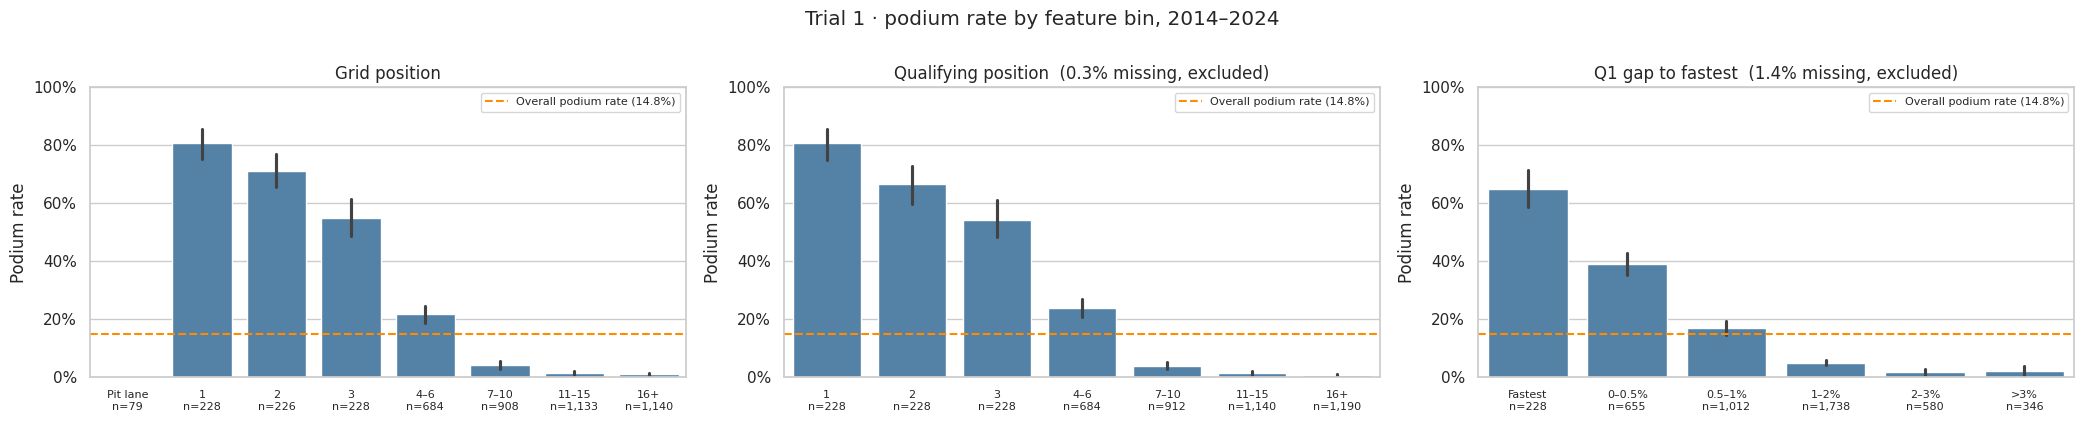

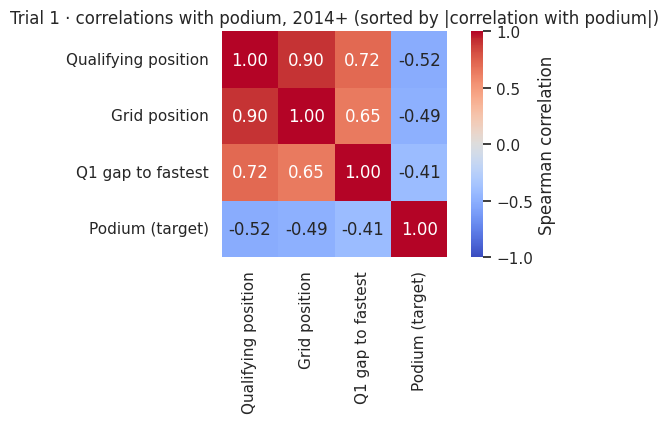

,Spearman correlation with podium
qualifying_position,-0.521
grid,-0.493
q1_gap_percentage,-0.415


In [85]:
# TRIAL 1 PLOTS: how grid and qualifying relate to the podium rate
plot_podium_rate_by_feature(table_trial_1, features_trial_1, 'Trial 1', ncols=3)
trial_1_correlations = plot_correlation_with_podium(
    table_trial_1, features_trial_1, 'Trial 1')
display(trial_1_correlations.round(3))

**What Trial 1 shows (2014–2024)**

- **All three features clearly separate podium finishers from the rest.** From grid P1 the
  podium rate is about **80%**. It drops to about 71% from P2, 55% from P3, 22% from
  P4–6, and below 5% from P7 onward. The overall rate is 14.8%. Pit-lane starters (79
  entries) never reached the podium. Qualifying position shows the same pattern.
- **The Q1 gap adds a pace measure.** The fastest car in Q1 reaches the podium about 65%
  of the time, cars within 0.5% of it about 39%, and cars more than 1% slower almost never.
- **The three features largely tell the same story.** Qualifying position and grid move
  together very strongly (correlation 0.90), and both move together with the Q1 gap
  (about 0.7). Their correlations with `podium` are −0.52 (qualifying), −0.49 (grid) and
  −0.41 (Q1 gap). They are negative because a *smaller* position number is better. Both
  positions are kept because penalties can make them differ; Section 8 tests whether the
  models really need both.
- **Missing values are mainly an old-seasons issue.** Qualifying is missing for about 61%
  of all entries since 1950, but for only **0.3%** (position) and **1.4%** (Q1 gap) of
  entries from 2014 onward.

### 6.7 Trial 2 · Adding driver and team form

**Idea:** two drivers starting from the same grid slot do not have the same chances. The
one in the stronger car, or with the better record, reaches the podium more often. The
past podium rates (6.2) describe long-term strength and the points shares (6.3) describe
this season's form, so they should add something the grid alone does not have.

In [86]:
# TRIAL 2: Grid + qualifying + driver and constructor form/standings
features_trial_2 = features_trial_1 + DRIVER_FEATURES + CONSTRUCTOR_FEATURES
table_trial_2 = trial_base[features_trial_2 + [TARGET]].copy()

display(table_trial_2.head())
display(summarise_trial_table(table_trial_2, features_trial_2))

,"Missing, all seasons (%)","Missing, 2014+ (%)"
grid,0,0
qualifying_position,60.6,0.3
q1_gap_percentage,61.2,1.4
driver_podium_rate_pre_race,0,0
driver_points_share_pre_race,1.7,0
constructor_podium_rate_pre_race,0,0
constructor_points_share_pre_race,6.3,0


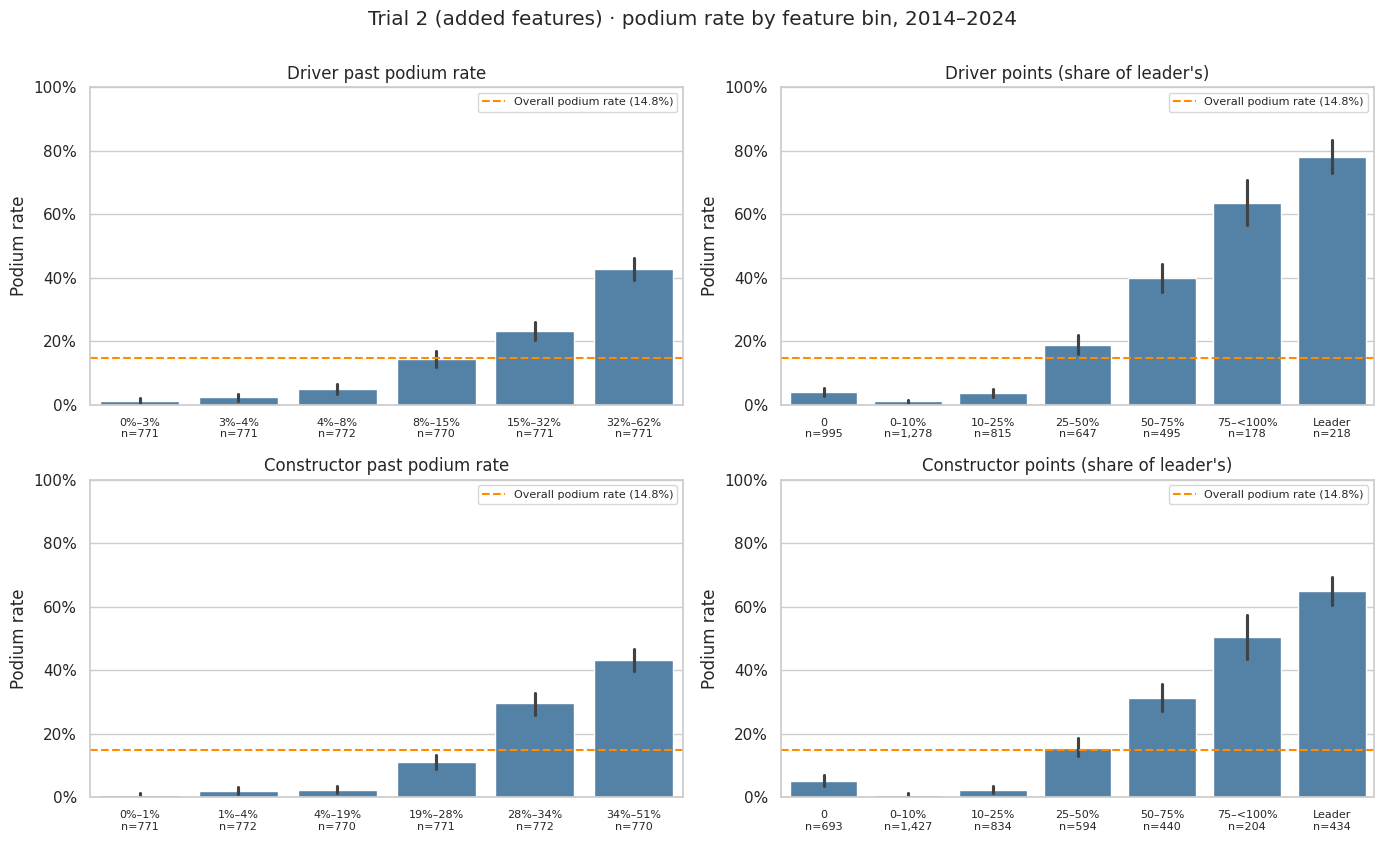

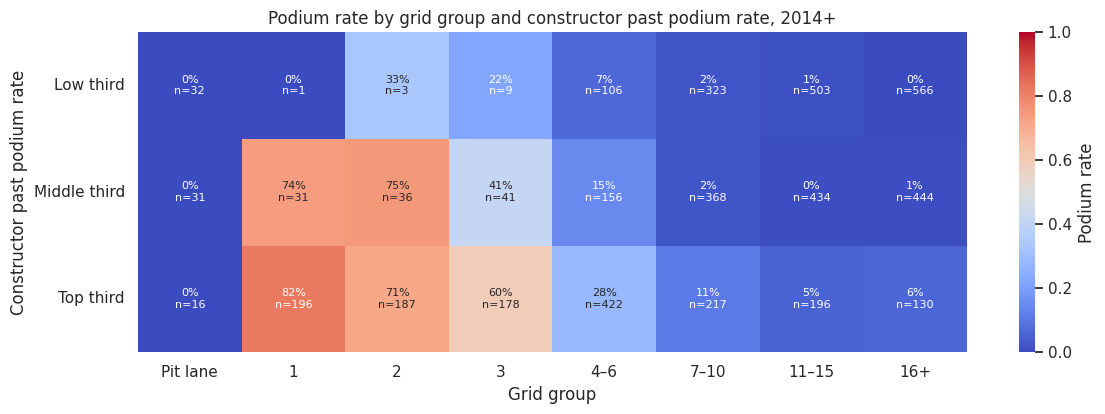

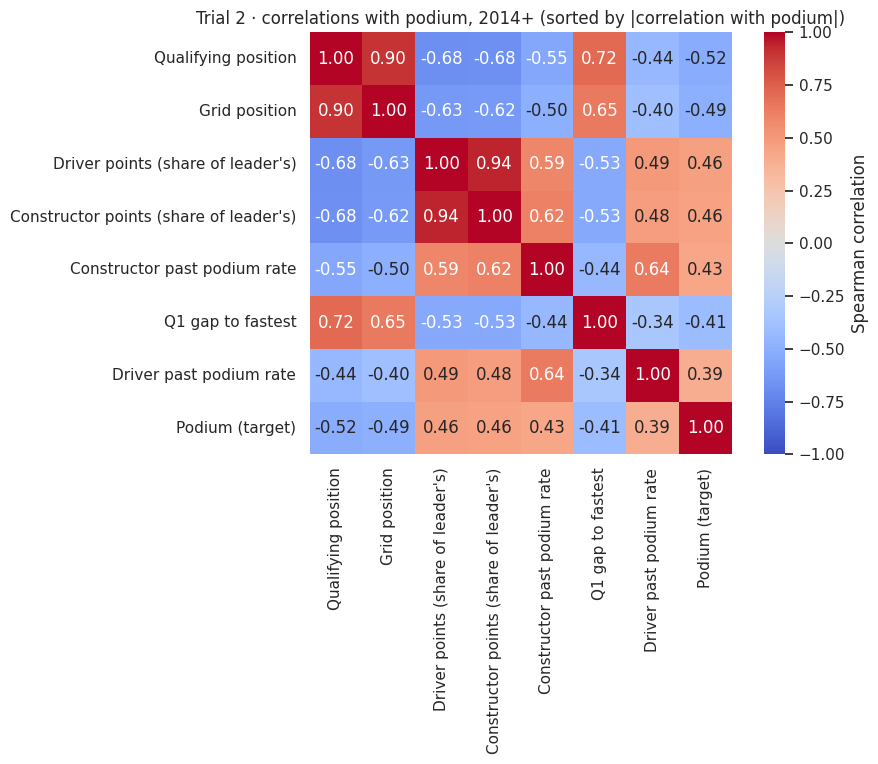

,Spearman correlation with podium
qualifying_position,-0.521
grid,-0.493
driver_points_share_pre_race,0.464
constructor_points_share_pre_race,0.458
constructor_podium_rate_pre_race,0.43
q1_gap_percentage,-0.415
driver_podium_rate_pre_race,0.393


In [87]:
# TRIAL 2 PLOTS: the newly added form features, then all Trial 2 features together
new_trial_2_features = DRIVER_FEATURES + CONSTRUCTOR_FEATURES
plot_podium_rate_by_feature(table_trial_2, new_trial_2_features, 'Trial 2 (added features)')

# Does form add anything beyond the grid? Podium rate by grid group x constructor form.
window_2 = table_trial_2[table_trial_2.index.get_level_values('year') >= PLOT_START_YEAR]
plot_grid_interaction(
    window_2,
    pd.qcut(window_2['constructor_podium_rate_pre_race'], q=3,
            labels=['Low third', 'Middle third', 'Top third']),
    'Constructor past podium rate',
    f'Podium rate by grid group and constructor past podium rate, {PLOT_START_YEAR}+')

trial_2_correlations = plot_correlation_with_podium(
    table_trial_2, features_trial_2, 'Trial 2')
display(trial_2_correlations.round(3))

**What Trial 2 shows (2014–2024)**

- **Every form feature separates podium chances strongly.** Drivers in the top sixth by
  past podium rate reach the podium about **42%** of the time, against about 1% for the
  bottom sixth. The current championship leader reaches the podium about **78%** of the
  time, drivers with 75–99% of the leader's points about 63%, and drivers with less than
  25% almost never. The team features show the same pattern. The slightly higher rate in
  the "0" group than in "0–10%" is because every driver, including the strong ones,
  starts the season on 0.
- **The points share works better than raw points.** Its correlation with `podium` is
  **0.46** for both driver and team, against about 0.40 for raw points. It also means
  the same thing under every scoring system.
- **Form adds something the grid does not have.** The grid-by-team-strength heatmap
  compares cars that start from the same grid group. From P3, a car from the strongest
  third of teams reaches the podium about **60%** of the time, against 41% for a
  middle-third team. From P4–6 it is **28% vs 15% vs 7%**, and from P7–10 a strong car
  still reaches the podium 11% of the time, against 2% for the others. (The weakest
  teams' cells for P1–P3 hold only 1–9 entries and should not be over-read.)
- **Overlap to keep in mind:** the driver and team points shares move together very
  strongly (0.94), because team-mates share a car. Section 8 tests whether both are
  needed.
- **Missing values:** team points are missing before 1958 (no team championship) and
  driver points for a few entries. From 2014 onward, none of the form features are
  missing.

### 6.8 Trial 3 · Adding the circuit

**Idea:** some circuits reward a front-row start more than others (Question 1), and some
drivers or cars may do unusually well at certain tracks. If so, the circuit numbers
should add information on top of grid and form.

Every race has exactly three podiums, so the circuit's front-row conversion is the same
for every driver in a race and cannot change the podium rate on its own. It can only
matter **together with the grid** (mainly for the front-row starters), so it is shown as a
heatmap of grid group against circuit conversion rather than as a bar chart.

In [88]:
# TRIAL 3: Grid + qualifying + driver/constructor form + circuit encodings
features_trial_3 = features_trial_2 + CIRCUIT_FEATURES
table_trial_3 = trial_base[features_trial_3 + [TARGET]].copy()

display(table_trial_3.head())
display(summarise_trial_table(table_trial_3, features_trial_3))

,"Missing, all seasons (%)","Missing, 2014+ (%)"
grid,0,0
qualifying_position,60.6,0.3
q1_gap_percentage,61.2,1.4
driver_podium_rate_pre_race,0,0
driver_points_share_pre_race,1.7,0
constructor_podium_rate_pre_race,0,0
constructor_points_share_pre_race,6.3,0
circuit_front_row_conversion_pre_race,0,0
driver_circuit_lift_pre_race,0,0
constructor_circuit_lift_pre_race,0,0


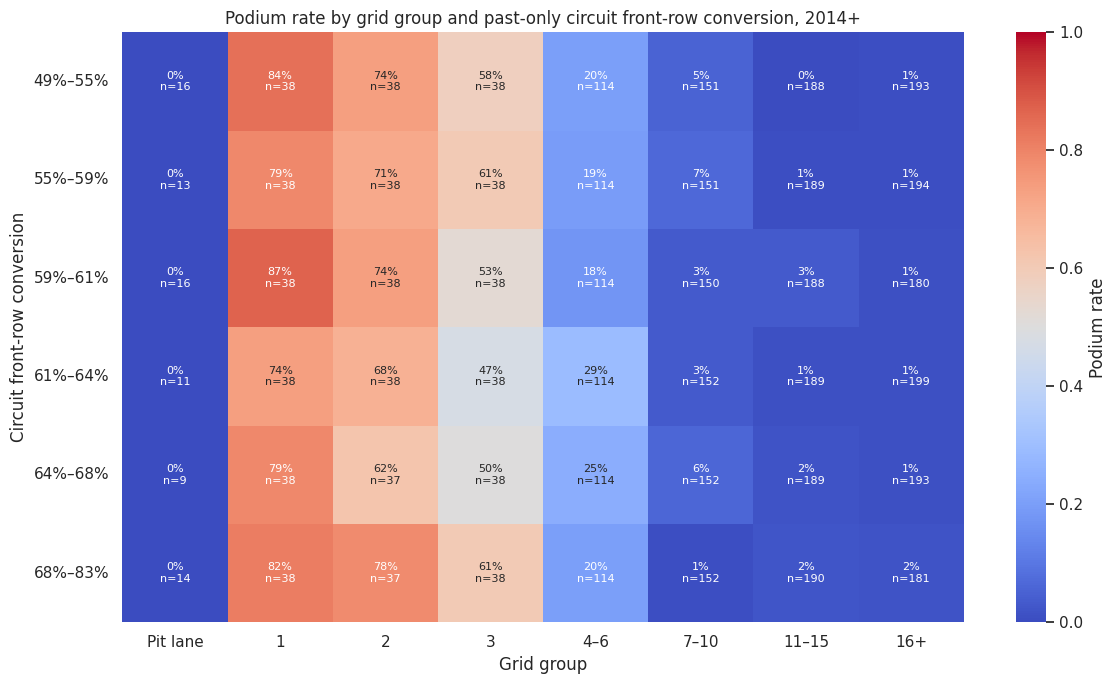

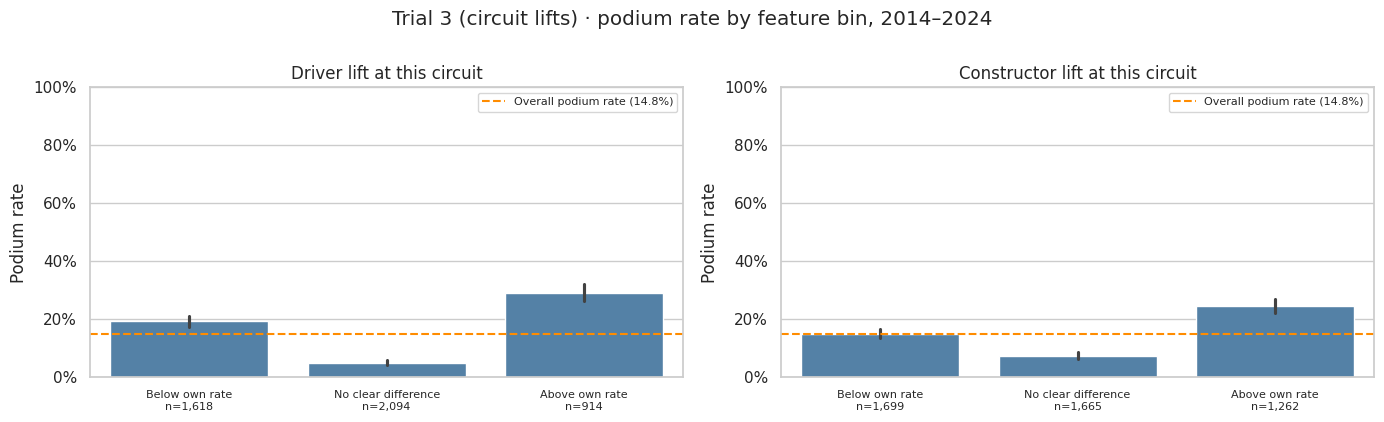

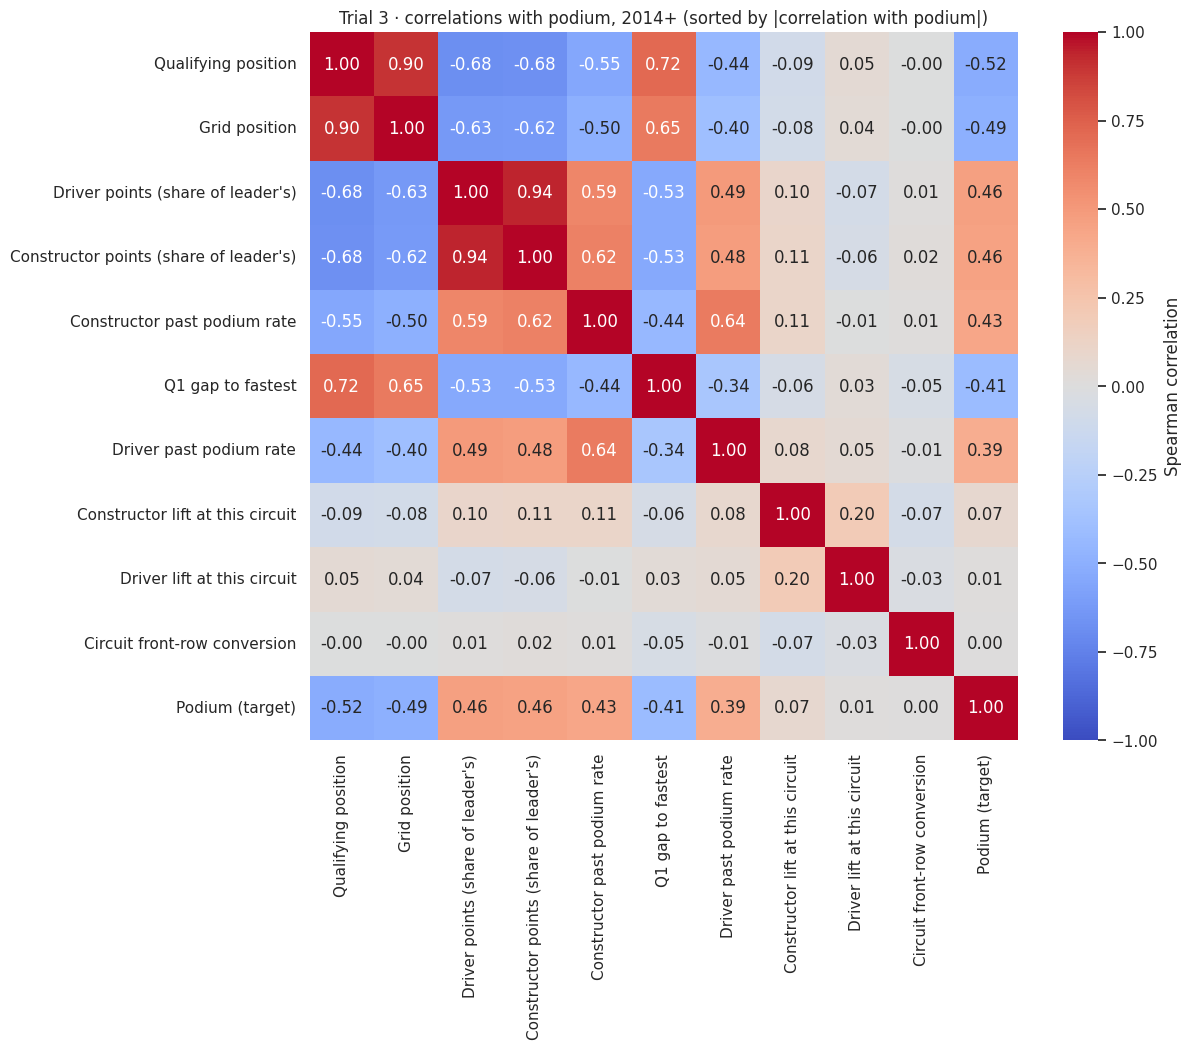

,Spearman correlation with podium
qualifying_position,-0.521
grid,-0.493
driver_points_share_pre_race,0.464
constructor_points_share_pre_race,0.458
constructor_podium_rate_pre_race,0.43
q1_gap_percentage,-0.415
driver_podium_rate_pre_race,0.393
constructor_circuit_lift_pre_race,0.075
driver_circuit_lift_pre_race,0.01
circuit_front_row_conversion_pre_race,0.002


In [89]:
# TRIAL 3 PLOTS: the circuit encodings, then all Trial 3 features together
window_3 = table_trial_3[table_trial_3.index.get_level_values('year') >= PLOT_START_YEAR]

# Front-row conversion only makes sense together with the grid (interaction heatmap).
plot_grid_interaction(
    window_3,
    bin_feature(window_3['circuit_front_row_conversion_pre_race'],
                'circuit_front_row_conversion_pre_race'),
    'Circuit front-row conversion',
    'Podium rate by grid group and past-only circuit front-row conversion, '
    f'{PLOT_START_YEAR}+')

plot_podium_rate_by_feature(
    table_trial_3,
    ['driver_circuit_lift_pre_race', 'constructor_circuit_lift_pre_race'],
    'Trial 3 (circuit lifts)')

trial_3_correlations = plot_correlation_with_podium(
    table_trial_3, features_trial_3, 'Trial 3')
display(trial_3_correlations.round(3))

**What Trial 3 shows (2014–2024)**

- **Front-row conversion shows no clear pattern.** In the heatmap, front-row starters
  (P1–P2) reach the podium roughly 70–80% of the time in every band of circuit
  conversion, with no rise from the "low conversion" to the "high conversion" circuits.
  A circuit's past conversion does not predict its future conversion well: with only
  about two front-row starts per circuit per season, the history is short and noisy. Its
  correlation with `podium` is about **0**, as expected, because it is the same for every
  driver in a race.
- **The circuit "lifts" point the right way, but partly repeat what is already known.**
  Entries that did better than usual at this circuit before reach the podium more often
  than entries that did worse: **29% vs 19%** for drivers and **24% vs 15%** for teams.
  However, the "no clear difference" group has the *lowest* podium rate (about 5–7%).
  That group is mostly drivers who rarely reach the podium anywhere, or who are at the
  circuit for the first time, and their lift is close to zero by design. So the size of
  the lift partly just reflects how good the driver already is. Its direct correlation
  with `podium` is small: **0.01** for drivers and **0.07** for teams.
- **Conclusion:** the evidence for the circuit features is much weaker than for Trials 1
  and 2. Trial 3 is kept as a fair test of whether the models can use these numbers in
  combination with the others; Section 7 decides on the validation seasons. Correlation
  only shows what moves together with podiums, not what *causes* them.

### 6.9 Summary of the trial tables

The table below is generated from the feature lists. All three tables share the same
rows and the same row labels `(raceId, driverId, year)`.

**Hand-over to Section 7:** Section 7 takes these three tables, splits them by season
(training up to 2019, validation 2020–2021, test from 2022), prepares the numbers using
the training seasons only, and trains the models. Which of the three trials is used for
the final models is decided there, on the validation seasons.

In [90]:
# 6.9 SUMMARY OF THE TRIAL TABLES (generated from the feature lists)
trial_summary = pd.DataFrame({
    'Table': ['table_trial_1', 'table_trial_2', 'table_trial_3'],
    'Number of features': [len(features_trial_1), len(features_trial_2),
                           len(features_trial_3)],
    'Features': [', '.join(features_trial_1),
                 '+ ' + ', '.join(f for f in features_trial_2 if f not in features_trial_1),
                 '+ ' + ', '.join(f for f in features_trial_3 if f not in features_trial_2)],
    'Rows': [len(table_trial_1), len(table_trial_2), len(table_trial_3)],
    'Target': 'podium',
}, index=['Trial 1', 'Trial 2', 'Trial 3'])
display(trial_summary)

,Table,Number of features,Features,Rows,Target
Trial 1,table_trial_1,3,"grid, qualifying_position, q1_gap_percentage","26,668",podium
Trial 2,table_trial_2,7,"+ driver_podium_rate_pre_race, driver_points_share_pre_race, constructor_podium_rate_pre_race, constructor_points_share_pre_race","26,668",podium
Trial 3,table_trial_3,10,"+ circuit_front_row_conversion_pre_race, driver_circuit_lift_pre_race, constructor_circuit_lift_pre_race","26,668",podium


<a id="modeling"></a>
## 7. Predictive modeling

Section 6 built the feature tables. This section trains models that read a driver's
situation just before the race and output a **probability that the driver finishes on
the podium**. The models learn from older seasons, are compared and tuned on the middle
seasons, and are checked **once** at the very end on the newest seasons, which they have
never seen.

What happens, step by step (each step uses the result of the one before):

- **7.1** Split the seasons into training, validation and test sets.
- **7.2** Prepare the numbers (fill gaps, put features on a common scale) and show what
  that changes.
- **7.3** Train two quick models many times to compare start years, feature sets and
  the order of the preparation steps.
- **7.4** Pick the **start year** and the **feature set** from 7.3.
- **7.5** Train the final statistical models and a simple baseline **on the choices from
  7.3 and 7.4**, and pick the best gradient-boosting settings.
- **7.6** Train the shallow neural network on **exactly the same rows and features**.
- **7.7** Compare all models on validation and, for the first time, on the test seasons.
- **7.8** How the models work, and their limitations.
- **7.9** Summary.

### How the models are scored
Each model gives every driver a probability. Five measures are reported:

- **PR-AUC:** if you sort the drivers from most to least likely, how many of the model's
  top picks really reached the podium. 1.0 is perfect; random guessing scores about the
  podium rate (about 0.13–0.15).
- **ROC-AUC:** how often a real podium finisher gets a higher probability than a driver
  who did not finish on the podium. 0.5 is a coin flip, 1.0 is perfect.
- **F1:** after turning probabilities into yes/no with a cut-off (the **threshold**), one
  score that balances precision and recall.
- **Precision:** of the drivers predicted "podium", the share that really were.
- **Recall:** of the real podium finishers, the share the model caught.

**Main measure: PR-AUC.** Only about 1 in 7 entries is a podium. ROC-AUC can look
excellent just by ranking the many back-markers correctly, while PR-AUC focuses on the
rare podium finishers that matter here. **Second measure: F1**, because it scores the
final yes/no answer a user would actually see.

**The threshold** of each model is the cut-off that gives the best F1 **on the validation
seasons**. That same threshold is then reused, unchanged, on the test seasons.

**The test seasons stay locked until 7.7.** Every choice in this section (start year,
feature set, preparation order, model settings, thresholds) is made with the training
and validation seasons only.

### 7.1 Splitting the seasons into training, validation and test

The split follows time, because the model will always be used on races that happen
*after* the data it learned from. A random split would let the model learn from 2023 to
"predict" 2015, which is not how it would be used.

- **Training (up to 2019):** the models learn from these seasons. The first training
  season is chosen in 7.4.
- **Validation (2020–2021):** used to compare options and choose settings.
- **Test (2022 onward):** locked away and used once, at the end, for the final score.

One change is made, to the modeling copy only: **grid position 0 means a pit-lane start**,
which has no numbered grid slot. It is treated as missing (and filled in during 7.2), so
the models do not read 0 as "better than pole position". The cleaned data is not
changed.

The table below is generated from the split and shows the seasons, entries and podium
rate in each set.

,first_season,last_season,entries,podiums,podium_rate
split,,,,,
Train,"1,950","2,019","24,529","3,074",0.125
Validation,"2,020","2,021",780,117,0.15
Test,"2,022","2,024","1,359",204,0.15


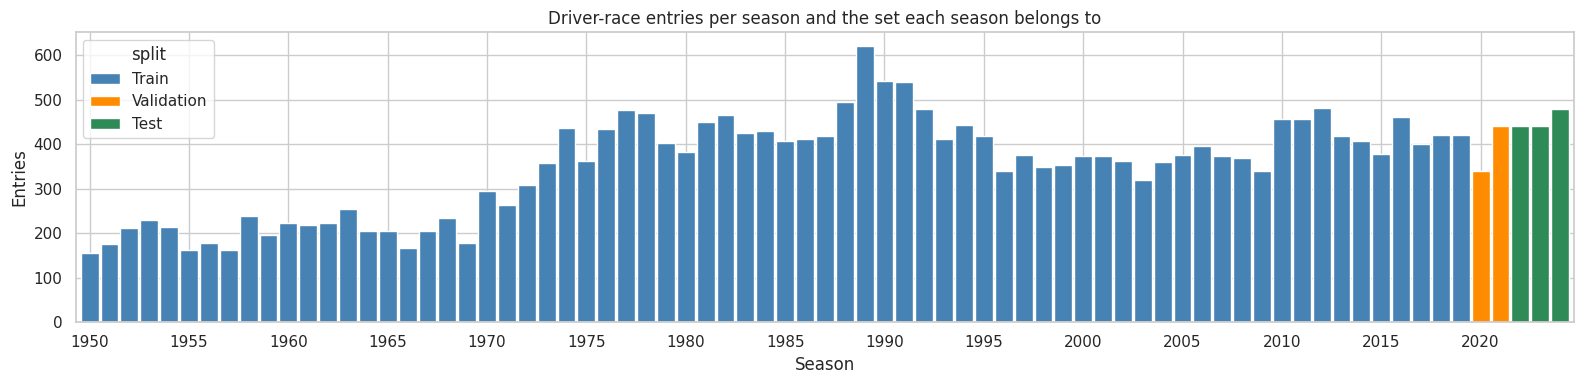

In [91]:
# 7.1 SPLIT THE SEASONS (time-based)
from IPython.display import Markdown

RANDOM_STATE = 42
TRAIN_END_YEAR = 2019
VALIDATION_YEARS = (2020, 2021)
TEST_START_YEAR = 2022

model_table = trial_base.copy()
model_table['grid'] = model_table['grid'].mask(model_table['grid'].eq(0))  # pit lane -> missing
season = model_table.index.get_level_values('year')
model_table['split'] = np.select(
    [season <= TRAIN_END_YEAR, season <= VALIDATION_YEARS[1]],
    ['Train', 'Validation'], default='Test')

train_all = model_table[model_table['split'] == 'Train']
validation = model_table[model_table['split'] == 'Validation']
test = model_table[model_table['split'] == 'Test']
assert len(train_all) + len(validation) + len(test) == len(model_table)

split_summary = model_table.groupby('split', sort=False).agg(
    first_season=('podium', lambda s: s.index.get_level_values('year').min()),
    last_season=('podium', lambda s: s.index.get_level_values('year').max()),
    entries=('podium', 'size'),
    podiums=('podium', 'sum'),
    podium_rate=('podium', 'mean'))
display(split_summary.round(3))

rows_per_season = model_table.groupby([season, 'split']).size().unstack(fill_value=0)
rows_per_season[['Train', 'Validation', 'Test']].plot(
    kind='bar', stacked=True, width=0.9, figsize=(16, 4),
    color=['steelblue', 'darkorange', 'seagreen'])
plt.xticks(ticks=range(0, len(rows_per_season), 5),
           labels=rows_per_season.index[::5], rotation=0)
plt.title('Driver-race entries per season and the set each season belongs to')
plt.xlabel('Season')
plt.ylabel('Entries')
plt.tight_layout()
plt.show()

### 7.2 Preparing the numbers: filling gaps and scaling

Two standard preparation steps are applied before training:

1. **Filling gaps with the median:** a missing value (for example, no qualifying time) is
   replaced by the middle value of that feature in the **training** seasons.
2. **Standard scaling:** every feature is shifted and stretched so that its average is 0
   and its spread (standard deviation) is 1. Without this, a feature measured in big
   numbers (grid position, up to 34) would outweigh a feature measured in small numbers
   (points share, 0 to 1) in logistic regression and the neural network. Gradient
   boosting does not need scaling but is not harmed by it.

Both steps **learn their numbers (the medians, averages and spreads) from the training
seasons only** and then apply those same numbers to the validation and test seasons. That
way no information from later seasons leaks into training.

The table and plots below show what the steps do (training seasons, all Trial 3
features). After scaling, each feature keeps its shape but is now centred on 0. Filled
gaps show up as one tall bar at the median. This is very visible for the Q1 gap, because
qualifying times are missing for most seasons before the mid-1990s.

,Missing before (%),Average before,Spread before,Min before,Max before,Missing after (%),Average after,Spread after
grid,6.433,12.012,6.902,1,34,0,0,1
qualifying_position,65.934,11.376,6.369,1,28,0,0,1
q1_gap_percentage,66.485,2.141,10.351,0,922.862,0,-0,1
driver_podium_rate_pre_race,0,0.131,0.118,0.007,0.624,0,-0,1
driver_points_share_pre_race,1.835,0.176,0.275,0,1,0,0,1
constructor_podium_rate_pre_race,0,0.139,0.115,0.002,0.478,0,-0,1
constructor_points_share_pre_race,6.849,0.26,0.33,0,1,0,0,1
circuit_front_row_conversion_pre_race,0,0.533,0.085,0.317,1,0,-0,1
driver_circuit_lift_pre_race,0,-0,0.051,-0.241,0.35,0,0,1
constructor_circuit_lift_pre_race,0,-0,0.056,-0.222,0.371,0,0,1


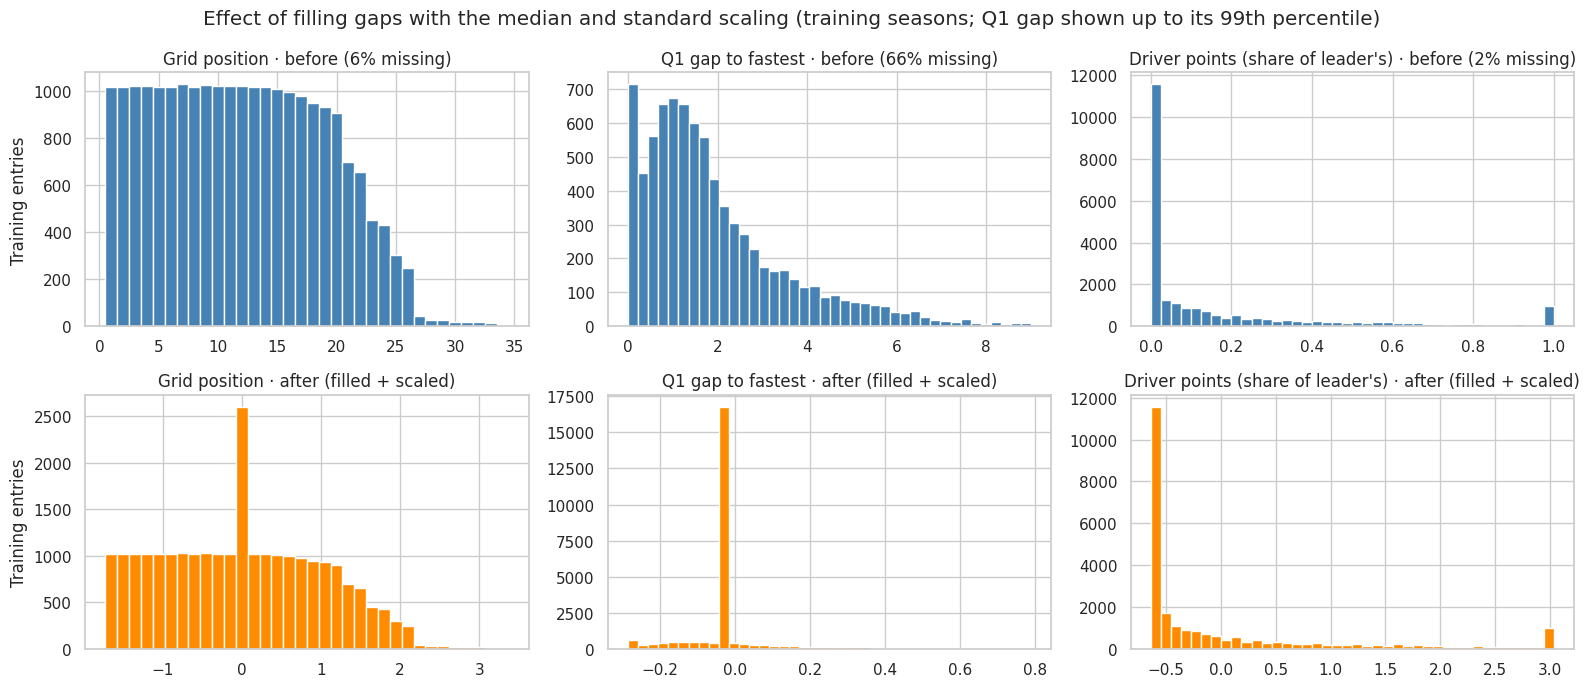

In [92]:
# 7.2 PREPROCESSING AND ITS EFFECT ON THE DATA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


def preprocessing_steps(order='impute → scale'):
    """Median imputation and standard scaling, in the requested order."""
    impute = ('impute', SimpleImputer(strategy='median'))
    scale = ('scale', StandardScaler())
    return [impute, scale] if order == 'impute → scale' else [scale, impute]


def one_bar_per_value(values):
    """Bin edges centred on each distinct value, so whole-number features such as
    grid position get exactly one bar per value (no empty gaps between bars)."""
    distinct = np.sort(pd.Series(values).dropna().unique())
    half_step = np.diff(distinct).min() / 2
    return np.append(distinct - half_step, distinct[-1] + half_step)


example_features = features_trial_3
preprocessor = Pipeline(preprocessing_steps()).fit(train_all[example_features])
train_prepared = pd.DataFrame(preprocessor.transform(train_all[example_features]),
                              columns=example_features, index=train_all.index)

effect_summary = pd.DataFrame({
    'Missing before (%)': train_all[example_features].isna().mean().mul(100),
    'Average before': train_all[example_features].mean(),
    'Spread before': train_all[example_features].std(),
    'Min before': train_all[example_features].min(),
    'Max before': train_all[example_features].max(),
    'Missing after (%)': train_prepared.isna().mean().mul(100),
    'Average after': train_prepared.mean(),
    'Spread after': train_prepared.std(),
})
display(effect_summary.round(3))

shown = ['grid', 'q1_gap_percentage', 'driver_points_share_pre_race']
fig, axes = plt.subplots(2, len(shown), figsize=(16, 7))
for column, feature in enumerate(shown):
    raw = train_all[feature].dropna()
    after = train_prepared[feature]
    if feature == 'q1_gap_percentage':   # a few extreme gaps would squash the plot
        raw = raw[raw <= raw.quantile(0.99)]
        after = after[after <= after.quantile(0.99)]
    raw_bins = one_bar_per_value(raw) if feature == 'grid' else 40
    after_bins = one_bar_per_value(after) if feature == 'grid' else 40
    axes[0, column].hist(raw, bins=raw_bins, color='steelblue')
    axes[0, column].set_title(f'{FEATURE_LABELS[feature]} · before '
                              f'({train_all[feature].isna().mean():.0%} missing)')
    axes[1, column].hist(after, bins=after_bins, color='darkorange')
    axes[1, column].set_title(f'{FEATURE_LABELS[feature]} · after (filled + scaled)')
for ax in axes[:, 0]:
    ax.set_ylabel('Training entries')
fig.suptitle('Effect of filling gaps with the median and standard scaling '
             '(training seasons; Q1 gap shown up to its 99th percentile)')
plt.tight_layout()
plt.show()

**How to read these plots**

- **Grid position (left):** the shape is unchanged; positions 1 to about 34 now run from
  about −1.6 to +3. The tall bar at 0 is the entries with no grid number (mostly pit-lane
  starts). They were all filled with the median grid slot, which becomes 0 after scaling.
- **Q1 gap (middle):** about two-thirds of the training entries had no Q1 time (mostly
  seasons before the mid-1990s), so they all became the median: that is the huge single
  bar. A few extreme gaps (hundreds of percent) also stretch the scale, so the normal
  values (0–9%) end up squeezed into a narrow band. This is a known limitation of plain
  median filling and scaling.
- **Driver points share (right):** the shape is unchanged and almost nothing had to be
  filled. 0 points maps to about −0.6 and the championship leader (1.0) to about +3.

**Why 2003 is one of the start years tested in 7.3.** The plot below shows, for every
season, the share of entries that have a qualifying position and a Q1 time.

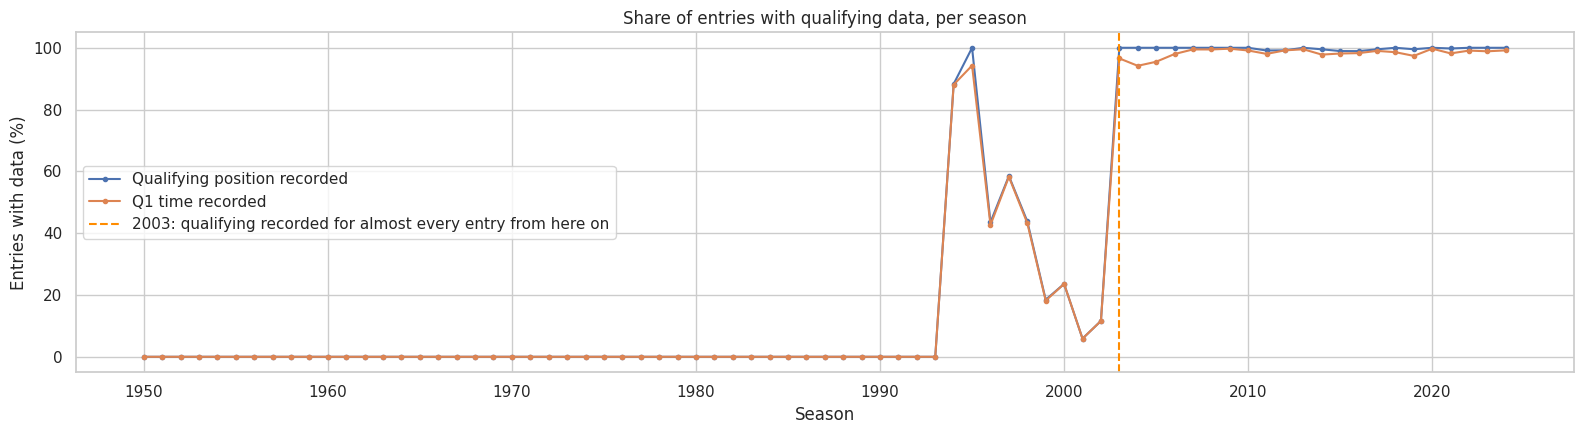

,Qualifying position recorded (%),Q1 time recorded (%)
year,,
1990,0,0
1991,0,0
1992,0,0
1993,0,0
1994,88.3,88.1
1995,100,94.3
1996,43.5,42.6
1997,58.5,58.2
1998,43.8,43.3


In [93]:
# WHY 2003 IS A CANDIDATE START YEAR: qualifying coverage per season
coverage = (model_table[['qualifying_position', 'q1_gap_percentage']].notna()
            .groupby(model_table.index.get_level_values('year')).mean().mul(100))

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(coverage.index, coverage['qualifying_position'], marker='o', markersize=3,
        label='Qualifying position recorded')
ax.plot(coverage.index, coverage['q1_gap_percentage'], marker='o', markersize=3,
        label='Q1 time recorded')
ax.axvline(2003, color='darkorange', linestyle='--',
           label='2003: qualifying recorded for almost every entry from here on')
ax.set(title='Share of entries with qualifying data, per season',
       xlabel='Season', ylabel='Entries with data (%)', ylim=(-5, 105))
ax.legend(loc='center left')
plt.tight_layout()
plt.show()

display(coverage.loc[1990:2006].round(1).rename(columns={
    'qualifying_position': 'Qualifying position recorded (%)',
    'q1_gap_percentage': 'Q1 time recorded (%)'}))

Before 1994 there is no qualifying data at all. 1994–1995 are well covered, but
1996–2002 are patchy. From **2003** onward, almost every entry has both a qualifying
position and a Q1 time. So 2003 is the first season from which a model can be trained
with practically no filled-in qualifying values, which is why it is tested next to the
decade start years.

### 7.3 Comparing start years, feature sets and preparation orders

Before training the final models, two quick models are trained many times to answer
three questions:

1. **From which season should training start?** Older seasons give more examples, but
   the sport was different and most qualifying data is missing before the mid-1990s.
2. **Which feature set (Trial 1, 2 or 3 from Section 6) works best?**
3. **Does the order of the two preparation steps from 7.2 matter?** Order A fills gaps
   first and then scales; order B scales first and then fills gaps.

What is tried:

- **First training season:** 1950, 1960, 1970, 1980, 1990, 2000, **2003** (first season
  with complete qualifying data, see above), 2010 and **2014** (start of the hybrid era).
- **Feature set:** Trial 1, Trial 2, Trial 3.
- **Preparation order:** A (fill → scale) and B (scale → fill).
- **Model:** logistic regression and gradient boosting, both with their default settings.

Every combination is trained once (9 × 3 × 2 × 2 = **108** models) and scored on the
validation seasons. The slower neural network is only trained after these choices are
made (7.6).

In [94]:
# 7.3 TRAIN LOGISTIC REGRESSION AND GRADIENT BOOSTING FOR EVERY COMBINATION
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score)

START_YEARS = [1950, 1960, 1970, 1980, 1990, 2000, 2003, 2010, 2014]
ORDERS = ['impute → scale', 'scale → impute']
TRIAL_FEATURES = {'Trial 1': features_trial_1,
                  'Trial 2': features_trial_2,
                  'Trial 3': features_trial_3}
SWEEP_MODELS = {
    'Logistic regression': lambda: LogisticRegression(max_iter=2000),
    'Gradient boosting': lambda: GradientBoostingClassifier(random_state=RANDOM_STATE),
}

train_season = train_all.index.get_level_values('year')
y_validation = validation[TARGET]

sweep_rows, window_rows = [], []
sweep_probabilities = {}   # reused by the start-year check in 7.4
for start_year in START_YEARS:
    train_window = train_all[train_season >= start_year]
    window_rows.append({
        'Start year': start_year,
        'Training entries': len(train_window),
        'Training podiums': int(train_window[TARGET].sum()),
        'Qualifying missing (%)': 100 * train_window['qualifying_position'].isna().mean(),
    })
    for trial, features in TRIAL_FEATURES.items():
        for order in ORDERS:
            for model_name, make_model in SWEEP_MODELS.items():
                model = Pipeline(preprocessing_steps(order) + [('model', make_model())])
                model.fit(train_window[features], train_window[TARGET])
                p_val = model.predict_proba(validation[features])[:, 1]
                sweep_probabilities[(start_year, trial, order, model_name)] = p_val
                sweep_rows.append({
                    'Start year': start_year, 'Trial': trial, 'Order': order,
                    'Model': model_name,
                    'Validation PR-AUC': average_precision_score(y_validation, p_val),
                    'Validation ROC-AUC': roc_auc_score(y_validation, p_val),
                })

window_summary = pd.DataFrame(window_rows).set_index('Start year')
sweep_results = pd.DataFrame(sweep_rows)
print(f'{len(sweep_results)} models trained · validation: {len(validation):,} entries, '
      f'{int(y_validation.sum())} podiums')
display(window_summary.round(1))

108 models trained · validation: 780 entries, 117 podiums


,Training entries,Training podiums,Qualifying missing (%)
Start year,,,
1950,"24,529","3,074",65.9
1960,"22,607","2,803",63
1970,"20,499","2,502",59.2
1980,"16,693","2,070",49.9
1990,"12,190","1,602",31.5
2000,"7,940","1,116",12.3
2003,"6,831",963,0.3
2010,"4,297",594,0.5
2014,"2,487",363,0.6


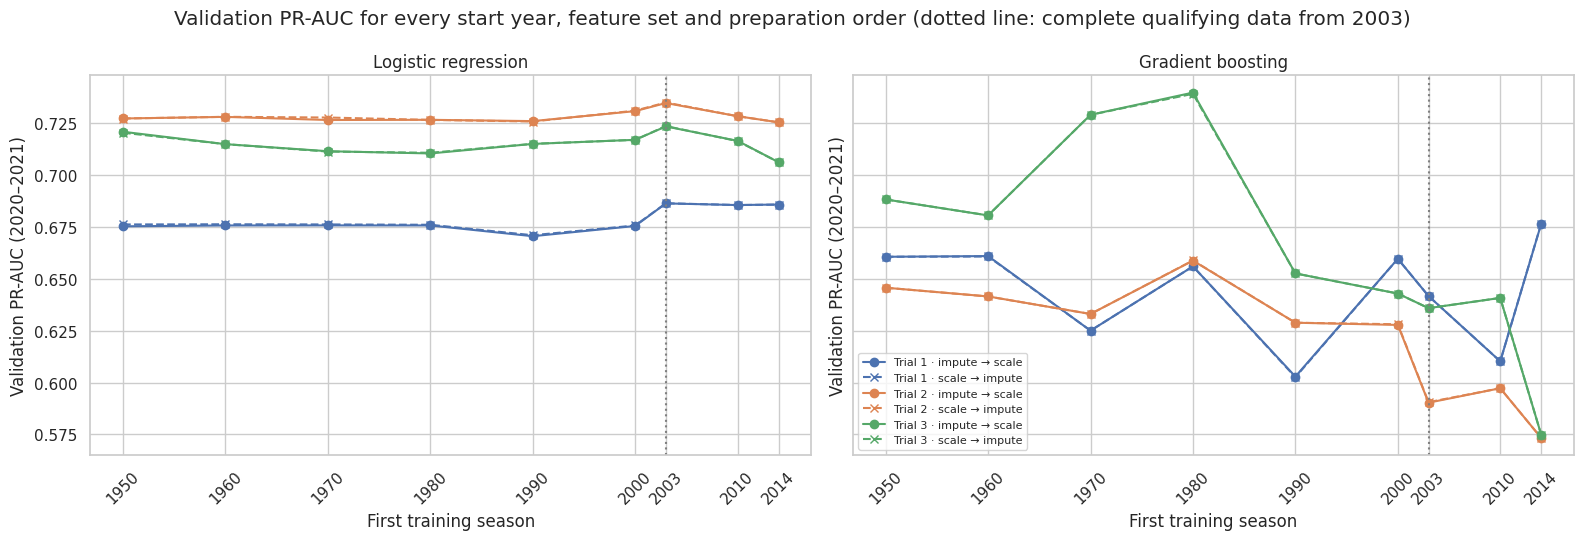

In [95]:
# 7.3 RESULT A: validation PR-AUC by start year, feature set and order
trial_colors = dict(zip(TRIAL_FEATURES, sns.color_palette('deep', 3)))
order_styles = {'impute → scale': '-', 'scale → impute': '--'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, model_name in zip(axes, SWEEP_MODELS):
    for trial in TRIAL_FEATURES:
        for order, style in order_styles.items():
            run = sweep_results.query(
                'Model == @model_name and Trial == @trial and Order == @order')
            ax.plot(run['Start year'], run['Validation PR-AUC'], style,
                    marker='o' if style == '-' else 'x', color=trial_colors[trial],
                    label=f'{trial} · {order}')
    ax.axvline(2003, color='grey', linestyle=':')
    ax.set(title=model_name, xticks=START_YEARS, xlabel='First training season',
           ylabel='Validation PR-AUC (2020–2021)')
    ax.tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8, loc='lower left')
fig.suptitle('Validation PR-AUC for every start year, feature set and preparation order '
             '(dotted line: complete qualifying data from 2003)')
plt.tight_layout()
plt.show()

**How to read this plot**

- **Each panel is one model**, the x-axis is the first training season and the y-axis
  is the validation PR-AUC (higher is better).
- **Colour = feature set** (Trial 1, 2 or 3 from Section 6).
- **Line style = preparation order:** solid line with dots = order A (fill → scale),
  dashed line with crosses = order B (scale → fill). Where the two orders give the same
  score, the dashed line sits exactly on top of the solid one and is hard to see. That
  overlap is itself the result of the order experiment.
- **Logistic regression (left)** gives almost flat lines: the start year matters little,
  and the gaps between the colours show how much each feature set helps.
- **Gradient boosting (right)** zig-zags much more from one start year to the next: it
  is more sensitive to exactly which seasons it is trained on.

,pairs,average_difference,largest_difference
Model,,,
Gradient boosting,27,-0,0.001
Logistic regression,27,0,0.001


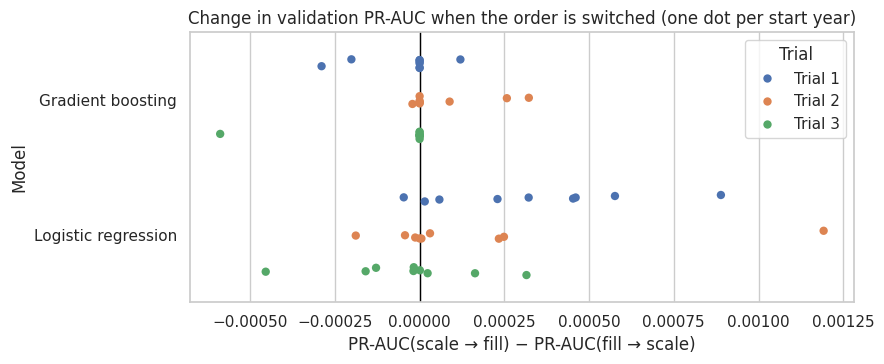

**Result of the order experiment (this run).** Over 27 pairs per model, the largest change caused by switching the order is **0.001** PR-AUC for logistic regression and **0.001** for gradient boosting.

In [96]:
# 7.3 RESULT B: the preparation-order experiment (same runs, only the order differs)
order_effect = sweep_results.pivot_table(
    index=['Start year', 'Trial', 'Model'], columns='Order', values='Validation PR-AUC')
order_effect['B − A'] = order_effect['scale → impute'] - order_effect['impute → scale']
order_summary = (order_effect.groupby(level='Model')['B − A']
                 .agg(pairs='size', average_difference='mean',
                      largest_difference=lambda d: d.abs().max()))
display(order_summary.round(4))

plt.figure(figsize=(9, 3.8))
sns.stripplot(data=order_effect.reset_index(), x='B − A', y='Model', hue='Trial',
              dodge=True, size=6, palette=trial_colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Change in validation PR-AUC when the order is switched '
          '(one dot per start year)')
plt.xlabel('PR-AUC(scale → fill) − PR-AUC(fill → scale)')
plt.tight_layout()
plt.show()

largest = order_summary['largest_difference']
text = (f"**Result of the order experiment (this run).** Over "
        f"{int(order_summary['pairs'].iloc[0])} pairs per model, the largest change caused "
        f"by switching the order is **{largest['Logistic regression']:.3f}** PR-AUC for "
        f"logistic regression and **{largest['Gradient boosting']:.3f}** for gradient "
        f"boosting.")
if largest.max() > 0.005:
    text += (" The occasional larger gap for gradient boosting comes from tiny rounding "
             "differences that change one split inside a tree, not from a real effect "
             "of the order.")
display(Markdown(text))

**How to read this table**

For every combination of *start year × feature set × model*, the model was trained
**twice**, once with each order. Everything else (rows, features, settings) is identical,
so any difference in score comes **only from the order**. For each pair we take:

> **B − A** = validation PR-AUC with order B − validation PR-AUC with order A

- **pairs:** how many such pairs each model has (9 start years × 3 feature sets).
- **average_difference:** the mean of all B − A values. Around 0 means neither order is
  better on average. ("-0" is a tiny negative number that rounds to 0.)
- **largest_difference:** the biggest gap in any single pair, ignoring the sign.

The dots in the plot are the individual pairs; they sit on (or right next to) the zero
line.

**Conclusion:** the order makes no practical difference. That is expected: filling with
the median and scaling only shift and stretch each feature, so both orders give the
models the same information. **Order A (fill → scale) is used for every model from here
on**, including the neural network and Sections 8 and 9.

### 7.4 Choosing the start year and the feature set

**Uses from 7.3:** the 108 validation results and their predictions.

**Start year.** The validation seasons hold only 44 races, so a score can move by a few
hundredths just by luck. To avoid picking a start year that only got lucky, the 44
validation races are **re-drawn at random 500 times** (some races twice, some not at
all, like replaying the seasons slightly differently), and every start year is scored on
each re-draw. This shows how much the gap between two start years wobbles by chance.

- The **score** of a start year is its validation PR-AUC on the real 44 races, averaged
  over both models and all three feature sets (order A).
- A start year counts as **"as good as the best"** when, across the 500 re-draws, the
  middle 95% of its gaps to the best year still includes 0 (sometimes better, sometimes
  worse, so the difference could be luck).
- Among the start years that are as good as the best, the **latest** one is chosen,
  because newer seasons are closer to today's sport and need less filling-in of missing
  qualifying data.

**Feature set.** For the chosen start year, the trial with the highest validation PR-AUC
(averaged over both models) is chosen.

**Hand-over:** the chosen start year, the chosen feature set and order A from 7.3 are
stored as `CHOSEN_START_YEAR`, `CHOSEN_TRIAL` / `FINAL_FEATURES` and `CHOSEN_ORDER`.
**Every final model in 7.5 and 7.6, the ablation in Section 8 and the explanations in
Section 9 use exactly these choices.**

,Average validation PR-AUC,Gap to best,95% range low,95% range high,As good as best,Training entries,Training podiums,Qualifying missing (%)
Start year,,,,,,,,
1950,0.686,-0.008,-0.018,-0,No,"24,529","3,074",65.934
1960,0.684,-0.011,-0.022,0.002,Yes,"22,607","2,803",63.038
1970,0.683,-0.011,-0.018,-0.003,No,"20,499","2,502",59.237
1980,0.695,0,0,0,Yes,"16,693","2,070",49.943
1990,0.666,-0.029,-0.044,-0.012,No,"12,190","1,602",31.452
2000,0.676,-0.019,-0.033,-0.003,No,"7,940","1,116",12.343
2003,0.669,-0.026,-0.043,-0.008,No,"6,831",963,0.337
2010,0.663,-0.031,-0.05,-0.01,No,"4,297",594,0.535
2014,0.657,-0.038,-0.058,-0.016,No,"2,487",363,0.603


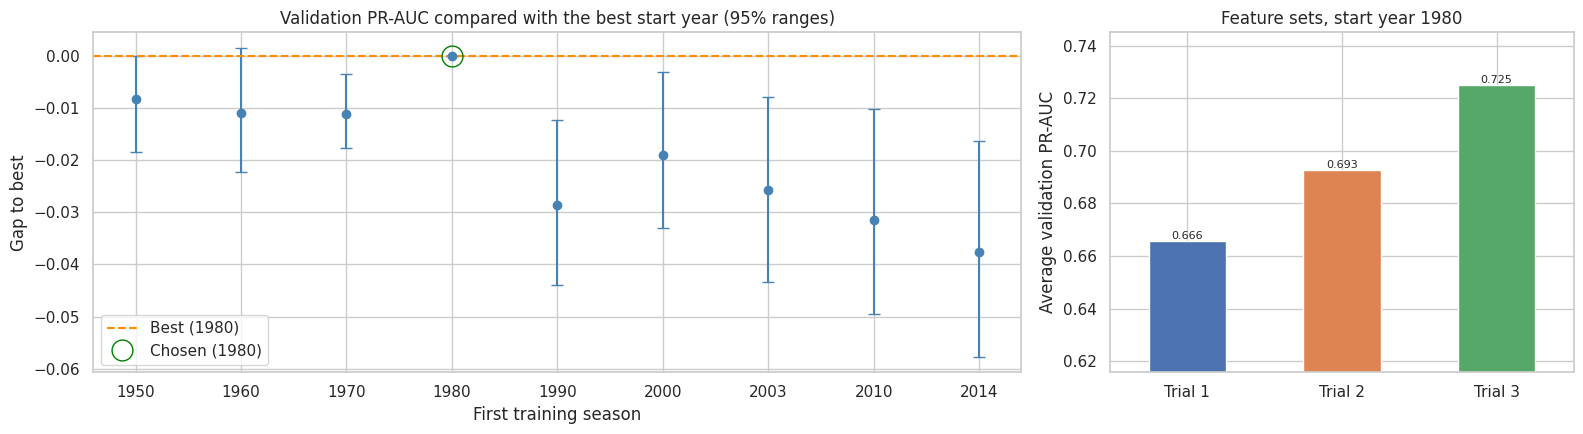

**What was chosen (this run).**

- **Start year: 1980.** The best average validation PR-AUC belongs to 1980 (0.695; this is the average of all six model/feature-set scores, the per-trial values are in the bar chart). Start years that are as good as the best: 1960, 1980. The latest of these is chosen.
- **Feature set: Trial 3** (10 features), the best of the three trials at that start year.
- **Each model on its own:** logistic regression scores best from 2003, gradient boosting from 1980. When they disagree, the combined score decides.
- **Trade-off:** training from 1980 uses 16,693 training entries, but 50% of them have no qualifying data and are filled with the median.

Chosen start year: 1980 · chosen feature set: Trial 3 (10 features: grid, qualifying_position, q1_gap_percentage, driver_podium_rate_pre_race, driver_points_share_pre_race, constructor_podium_rate_pre_race, constructor_points_share_pre_race, circuit_front_row_conversion_pre_race, driver_circuit_lift_pre_race, constructor_circuit_lift_pre_race) · preparation order: impute → scale


In [97]:
# 7.4 CHOOSE THE START YEAR (race-level re-draws) AND THE FEATURE SET
CHOSEN_ORDER = 'impute → scale'
RESAMPLES = 500
y_val_array = y_validation.to_numpy()
val_races = validation.index.get_level_values('raceId').to_numpy()
rows_of_race = {race: np.flatnonzero(val_races == race) for race in np.unique(val_races)}
rng = np.random.default_rng(RANDOM_STATE)
redraws = [np.concatenate([rows_of_race[r] for r in
                           rng.choice(list(rows_of_race), len(rows_of_race))])
           for _ in range(RESAMPLES)]


def start_year_score(start_year, rows=slice(None)):
    """Validation PR-AUC averaged over both models and all trials (order A)."""
    return np.mean([
        average_precision_score(
            y_val_array[rows],
            sweep_probabilities[(start_year, trial, CHOSEN_ORDER, model)][rows])
        for trial in TRIAL_FEATURES for model in SWEEP_MODELS])


observed = pd.Series({year: start_year_score(year) for year in START_YEARS})
best_year = int(observed.idxmax())
redraw_scores = pd.DataFrame([{year: start_year_score(year, rows) for year in START_YEARS}
                              for rows in redraws])
gap_to_best = redraw_scores.sub(redraw_scores[best_year], axis=0)

start_year_table = pd.DataFrame({
    'Average validation PR-AUC': observed,
    'Gap to best': observed - observed[best_year],
    '95% range low': gap_to_best.quantile(0.025),
    '95% range high': gap_to_best.quantile(0.975),
})
start_year_table['As good as best'] = start_year_table['95% range high'] >= 0
CHOSEN_START_YEAR = int(start_year_table.index[start_year_table['As good as best']].max())

trial_scores = (sweep_results.query('`Start year` == @CHOSEN_START_YEAR '
                                    'and Order == @CHOSEN_ORDER')
                .groupby('Trial')['Validation PR-AUC'].mean())
CHOSEN_TRIAL = trial_scores.idxmax()
FINAL_FEATURES = TRIAL_FEATURES[CHOSEN_TRIAL]

start_year_table.index.name = 'Start year'
display(start_year_table.join(window_summary).round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [2, 1]})
x = start_year_table.index.astype(str)
axes[0].errorbar(x, start_year_table['Gap to best'],
                 yerr=[start_year_table['Gap to best'] - start_year_table['95% range low'],
                       start_year_table['95% range high'] - start_year_table['Gap to best']],
                 fmt='o', capsize=4, color='steelblue')
axes[0].axhline(0, color='darkorange', linestyle='--', label=f'Best ({best_year})')
axes[0].plot(list(start_year_table.index).index(CHOSEN_START_YEAR),
             start_year_table.loc[CHOSEN_START_YEAR, 'Gap to best'], 'o', markersize=15,
             markerfacecolor='none', markeredgecolor='green',
             label=f'Chosen ({CHOSEN_START_YEAR})')
axes[0].set(title='Validation PR-AUC compared with the best start year (95% ranges)',
            xlabel='First training season', ylabel='Gap to best')
axes[0].legend()
trial_scores.plot(kind='bar', ax=axes[1], color=[trial_colors[t] for t in trial_scores.index])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.3f', fontsize=8)
axes[1].set(title=f'Feature sets, start year {CHOSEN_START_YEAR}',
            ylabel='Average validation PR-AUC', xlabel='',
            ylim=(trial_scores.min() - 0.05, trial_scores.max() + 0.02))
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# Written summary generated from this run.
ties = [y for y in START_YEARS if start_year_table.loc[y, 'As good as best']]
per_model_best = (sweep_results.query('Order == @CHOSEN_ORDER')
                  .groupby(['Model', 'Start year'])['Validation PR-AUC'].mean()
                  .groupby(level='Model').idxmax().map(lambda pair: pair[1]))
missing_share = window_summary.loc[CHOSEN_START_YEAR, 'Qualifying missing (%)']
display(Markdown(
    f"**What was chosen (this run).**\n\n"
    f"- **Start year: {CHOSEN_START_YEAR}.** The best average validation PR-AUC belongs to "
    f"{best_year} ({observed[best_year]:.3f}; this is the average of all six model/feature-set "
    f"scores, the per-trial values are in the bar chart). Start years that are as good as "
    f"the best: {', '.join(map(str, ties))}. The latest of these is chosen.\n"
    f"- **Feature set: {CHOSEN_TRIAL}** ({len(FINAL_FEATURES)} features), the best of the three "
    f"trials at that start year.\n"
    f"- **Each model on its own:** logistic regression scores best from "
    f"{per_model_best['Logistic regression']}, gradient boosting from "
    f"{per_model_best['Gradient boosting']}. When they disagree, the combined score decides.\n"
    f"- **Trade-off:** training from {CHOSEN_START_YEAR} uses "
    f"{int(window_summary.loc[CHOSEN_START_YEAR, 'Training entries']):,} training entries, "
    f"but {missing_share:.0f}% of them have no qualifying data and are filled with the median."))
print(f'Chosen start year: {CHOSEN_START_YEAR} · chosen feature set: {CHOSEN_TRIAL} '
      f'({len(FINAL_FEATURES)} features: {", ".join(FINAL_FEATURES)}) · '
      f'preparation order: {CHOSEN_ORDER}')

### 7.5 Final statistical models and the baseline

**Uses from 7.3 and 7.4:** every model below is trained on **the training seasons from
the chosen start year (`CHOSEN_START_YEAR`) to 2019**, uses **the chosen feature set
(`FINAL_FEATURES`)** and prepares the data with **order A (fill gaps with the median,
then scale)**, fitted on those training rows.

- **Baseline (the reference point):** logistic regression using **only the grid
  position**. It answers the question "how well can we do just by knowing where the car
  starts?". Every other model has to beat it to be worth its extra complexity.
- **Logistic regression:** the same type of model, now with all chosen features.
- **Gradient boosting:** four versions are trained, combining two **learning rates** (0.05
  and 0.1: how big a correction each new tree makes) with two **tree depths** (2 and 3: how
  many yes/no questions each tree may ask in a row), each with 200 trees.

**The best of the four gradient-boosting versions, the one with the highest validation
PR-AUC, is the one kept.** That single version is the "Gradient boosting" model trained
on the training seasons and then scored on validation and on the test seasons in 7.7. Its
settings are also reused in Sections 8 and 9.

In [98]:
# 7.5 BASELINE, LOGISTIC REGRESSION AND GRADIENT BOOSTING ON THE CHOSEN SETUP
final_train = train_all[train_season >= CHOSEN_START_YEAR]
X_train, y_train = final_train[FINAL_FEATURES], final_train[TARGET]
X_val, y_val = validation[FINAL_FEATURES], validation[TARGET]
X_test, y_test = test[FINAL_FEATURES], test[TARGET]


def make_model(estimator):
    return Pipeline(preprocessing_steps(CHOSEN_ORDER) + [('model', estimator)])


baseline_model = make_model(LogisticRegression(max_iter=2000)).fit(
    final_train[['grid']], y_train)
logistic_model = make_model(LogisticRegression(max_iter=2000)).fit(X_train, y_train)

boosting_versions = []
for learning_rate in [0.05, 0.1]:
    for max_depth in [2, 3]:
        candidate = make_model(GradientBoostingClassifier(
            n_estimators=200, learning_rate=learning_rate, max_depth=max_depth,
            random_state=RANDOM_STATE)).fit(X_train, y_train)
        boosting_versions.append({
            'learning_rate': learning_rate, 'max_depth': max_depth,
            'Train PR-AUC': average_precision_score(
                y_train, candidate.predict_proba(X_train)[:, 1]),
            'Validation PR-AUC': average_precision_score(
                y_val, candidate.predict_proba(X_val)[:, 1]),
            'model': candidate})
boosting_versions = pd.DataFrame(boosting_versions)
best_boosting = boosting_versions.loc[boosting_versions['Validation PR-AUC'].idxmax()]
boosting_model = best_boosting['model']          # the version used from here on
BEST_LEARNING_RATE = best_boosting['learning_rate']
BEST_MAX_DEPTH = int(best_boosting['max_depth'])

boosting_table = boosting_versions.drop(columns='model').copy()
boosting_table['Kept'] = np.where(boosting_table.index == best_boosting.name, 'Yes', '')
display(boosting_table.round(4))

overfit = boosting_table.assign(gap=boosting_table['Train PR-AUC']
                                - boosting_table['Validation PR-AUC']).loc[
    lambda t: t['gap'].idxmax()]
display(Markdown(
    f"**Kept gradient-boosting version (this run): learning rate {BEST_LEARNING_RATE}, "
    f"depth {BEST_MAX_DEPTH}** (validation PR-AUC {best_boosting['Validation PR-AUC']:.3f}). "
    f"This version is the one trained for the final comparison and tested on the test "
    f"seasons in 7.7.\n\n"
    f"The version with learning rate {overfit['learning_rate']} and depth "
    f"{int(overfit['max_depth'])} fits the training seasons best relative to validation "
    f"(train {overfit['Train PR-AUC']:.3f}, validation {overfit['Validation PR-AUC']:.3f}): "
    f"the bigger the gap, the more a version has memorised the training data instead of "
    f"learning patterns that carry over to new seasons.\n\n"
    f"Training PR-AUC can be *lower* than validation PR-AUC: the training seasons reach back "
    f"to {CHOSEN_START_YEAR}, when fields were bigger and podiums rarer and harder to predict, "
    f"while 2020–2021 had about 20 cars per race."))
print(f'Setup used by all final models: training {CHOSEN_START_YEAR}–{TRAIN_END_YEAR} '
      f'({len(final_train):,} entries), {CHOSEN_TRIAL} ({len(FINAL_FEATURES)} features), '
      f'preparation: {CHOSEN_ORDER}')

learning_rate,max_depth,Train PR-AUC,Validation PR-AUC,Kept
0.05,2,0.655,0.724,Yes
0.05,3,0.696,0.721,
0.1,2,0.686,0.707,
0.1,3,0.752,0.712,


**Kept gradient-boosting version (this run): learning rate 0.05, depth 2** (validation PR-AUC 0.724). This version is the one trained for the final comparison and tested on the test seasons in 7.7.

The version with learning rate 0.1 and depth 3 fits the training seasons best relative to validation (train 0.752, validation 0.712): the bigger the gap, the more a version has memorised the training data instead of learning patterns that carry over to new seasons.

Training PR-AUC can be *lower* than validation PR-AUC: the training seasons reach back to 1980, when fields were bigger and podiums rarer and harder to predict, while 2020–2021 had about 20 cars per race.

Setup used by all final models: training 1980–2019 (16,693 entries), Trial 3 (10 features), preparation: impute → scale


### 7.6 Shallow neural network

**Uses from 7.4 and 7.5:** the network is trained on **exactly the same training rows,
features and data preparation** as the models in 7.5 (start year `CHOSEN_START_YEAR`,
features `FINAL_FEATURES`, fill → scale fitted on the training rows), so all scores in 7.7
can be compared directly.

**How it works:** a neural network passes the features through layers of simple
"neurons". Each neuron combines the previous layer's outputs with learned weights, and
the last neuron squeezes the result into a probability between 0 and 1. A *shallow*
network has only one or two hidden layers.

- **Layout:** the features → 32 neurons → 16 neurons → 1 output. Between the first two
  layers, 20% of the neurons are switched off at random during training ("dropout"), so
  the network cannot simply memorise the training data.
- **Training:** the weights are adjusted step by step to reduce the prediction error,
  using small batches of 64 entries, for up to 100 passes over the training data
  ("epochs").
- **Two versions are trained:** (1) all 100 epochs; (2) with **early stopping**, which
  stops as soon as the validation error has not improved for 10 epochs and keeps the best
  weights seen. **The version with the higher validation PR-AUC is kept**, and that is the
  network scored on the test seasons in 7.7. Its layout and early-stopping rule are reused
  in Sections 8 and 9.

,Epochs run,Validation PR-AUC,Kept
No early stopping,100,0.752,
Early stopping,63,0.756,Yes


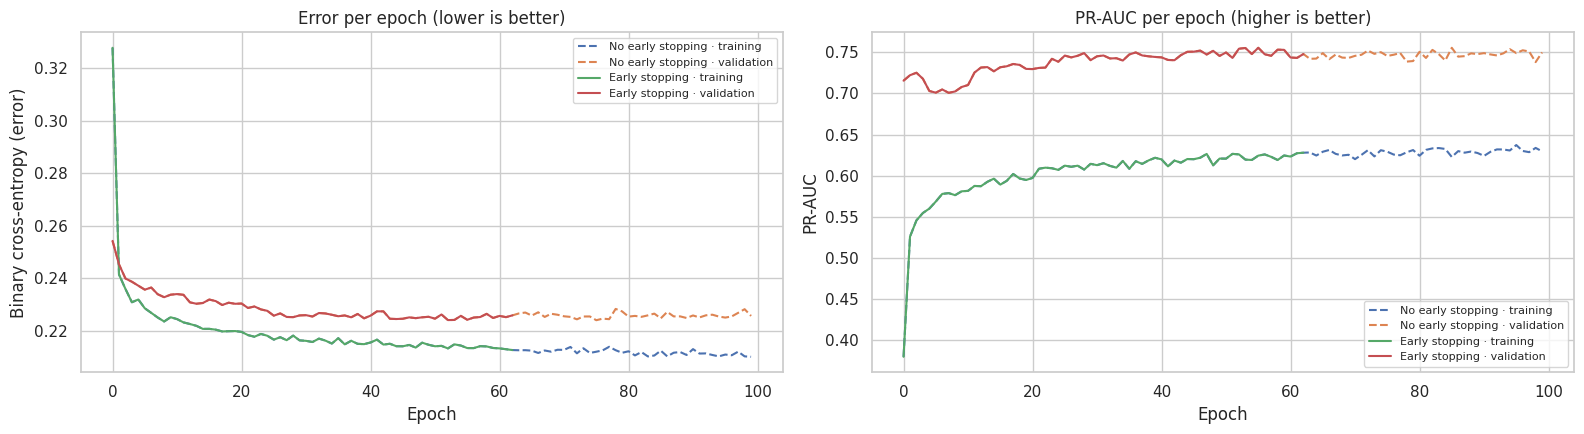

**Kept network (this run): Early stopping.** Early stopping ended training after **63 epochs**. Validation PR-AUC: 0.752 without and 0.756 with early stopping. The kept version is the one scored on the test seasons in 7.7.

In [99]:
# 7.6 SHALLOW NEURAL NETWORK (same rows, features and preparation as 7.5)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

nn_preprocessor = Pipeline(preprocessing_steps(CHOSEN_ORDER)).fit(X_train)
X_train_nn = nn_preprocessor.transform(X_train)
X_val_nn = nn_preprocessor.transform(X_val)
X_test_nn = nn_preprocessor.transform(X_test)


def build_shallow_network(n_features):
    keras.utils.set_random_seed(RANDOM_STATE)
    network = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid'),
    ])
    network.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                    loss='binary_crossentropy',
                    metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')])
    return network


def train_network(X_tr, y_tr, X_va, y_va, early_stopping=True):
    callbacks = ([EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)]
                 if early_stopping else [])
    network = build_shallow_network(X_tr.shape[1])
    history = network.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=100,
                          batch_size=64, callbacks=callbacks, verbose=0)
    return network, history.history


network_versions = {}
for version, early_stopping in [('No early stopping', False), ('Early stopping', True)]:
    network, history = train_network(X_train_nn, y_train, X_val_nn, y_val, early_stopping)
    network_versions[version] = {
        'network': network, 'history': history, 'Epochs run': len(history['loss']),
        'Validation PR-AUC': average_precision_score(
            y_val, network.predict(X_val_nn, verbose=0).ravel()),
    }

network_table = pd.DataFrame({name: {'Epochs run': v['Epochs run'],
                                     'Validation PR-AUC': v['Validation PR-AUC']}
                              for name, v in network_versions.items()}).T
KEPT_NETWORK = network_table['Validation PR-AUC'].idxmax()
NETWORK_EARLY_STOPPING = KEPT_NETWORK == 'Early stopping'
network_table['Kept'] = np.where(network_table.index == KEPT_NETWORK, 'Yes', '')
display(network_table.round(4))
neural_network = network_versions[KEPT_NETWORK]['network']

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for name, v in network_versions.items():
    style = '-' if name == 'Early stopping' else '--'
    axes[0].plot(v['history']['loss'], style, label=f'{name} · training')
    axes[0].plot(v['history']['val_loss'], style, label=f'{name} · validation')
    axes[1].plot(v['history']['pr_auc'], style, label=f'{name} · training')
    axes[1].plot(v['history']['val_pr_auc'], style, label=f'{name} · validation')
axes[0].set(title='Error per epoch (lower is better)', xlabel='Epoch',
            ylabel='Binary cross-entropy (error)')
axes[1].set(title='PR-AUC per epoch (higher is better)', xlabel='Epoch', ylabel='PR-AUC')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

stopped = network_versions['Early stopping']['Epochs run']
display(Markdown(
    f"**Kept network (this run): {KEPT_NETWORK}.** Early stopping ended training after "
    f"**{stopped} epochs**. Validation PR-AUC: "
    f"{network_versions['No early stopping']['Validation PR-AUC']:.3f} without and "
    f"{network_versions['Early stopping']['Validation PR-AUC']:.3f} with early stopping. "
    f"The kept version is the one scored on the test seasons in 7.7."))

**How to read the training curves**

After every epoch the network is scored twice: on the **training** seasons (the data it
learns from) and on the **validation** seasons (2020–2021, which it never learns from).
Both versions start from the same random starting point, so their curves are identical
until early stopping ends the solid lines; the dashed lines then continue to epoch 100.

- **Healthy training:** both curves improve and then flatten out together.
- **Memorising (overfitting):** the training curve keeps improving while the validation
  curve gets worse. In the left plot that would be the validation error rising again.

Here, both curves improve quickly in the first epochs and then level off. Later on, the
training error keeps creeping down while the validation error stays flat: the network is
only getting better at the training seasons, not at new races. Early stopping stops
training at that point. The validation PR-AUC sits *above* the training PR-AUC because
the training seasons reach back to the 1980s, when podiums were harder to predict.

### 7.7 Comparing the models on validation and on the test seasons

**Uses from 7.5 and 7.6:** the four final models (the grid-only baseline, logistic
regression, the kept gradient-boosting version and the kept neural network).

Each model's yes/no **threshold** is the value with the best F1 on the **validation**
seasons (tried from 0.05 to 0.95). That same threshold is then used on the training and
test seasons. **This is the first and only time the test seasons (2022 onward) are
used.** Nothing is changed after seeing the test results.

In [100]:
# 7.7 THRESHOLDS (validation only) AND THE FULL COMPARISON TABLE
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix


def predict_probability(model_name, features_frame):
    """Podium probability of a final model for rows with the original (raw) features."""
    if model_name == 'Baseline (grid only)':
        return baseline_model.predict_proba(features_frame[['grid']])[:, 1]
    if model_name == 'Logistic regression':
        return logistic_model.predict_proba(features_frame[FINAL_FEATURES])[:, 1]
    if model_name == 'Gradient boosting':
        return boosting_model.predict_proba(features_frame[FINAL_FEATURES])[:, 1]
    prepared = nn_preprocessor.transform(features_frame[FINAL_FEATURES])
    return neural_network.predict(prepared, verbose=0, batch_size=4096).ravel()


FINAL_MODELS = ['Baseline (grid only)', 'Logistic regression', 'Gradient boosting',
                'Shallow neural network']
splits = {'Train': final_train, 'Validation': validation, 'Test': test}
probabilities = {(model, split): predict_probability(model, data)
                 for model in FINAL_MODELS for split, data in splits.items()}


def best_f1_threshold(y_true, probability):
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
    scores = [f1_score(y_true, probability >= t, zero_division=0) for t in thresholds]
    return thresholds[int(np.argmax(scores))]


thresholds = {model: best_f1_threshold(y_val, probabilities[(model, 'Validation')])
              for model in FINAL_MODELS}

comparison = []
for (model, split), probability in probabilities.items():
    y_true = splits[split][TARGET]
    predicted = probability >= thresholds[model]
    comparison.append({
        'Model': model, 'Set': split,
        'PR-AUC': average_precision_score(y_true, probability),
        'ROC-AUC': roc_auc_score(y_true, probability),
        'F1': f1_score(y_true, predicted, zero_division=0),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted, zero_division=0),
        'Threshold': thresholds[model],
    })
comparison = pd.DataFrame(comparison)
display(comparison.round(3))

summary_table = comparison.pivot_table(index='Model', columns='Set',
                                       values=['PR-AUC', 'ROC-AUC', 'F1'], sort=False)
summary_table = summary_table[[('PR-AUC', 'Validation'), ('PR-AUC', 'Test'),
                               ('ROC-AUC', 'Test'), ('F1', 'Validation'), ('F1', 'Test')]]
summary_table.columns = ['Validation PR-AUC', 'Test PR-AUC', 'Test ROC-AUC',
                         'Validation F1', 'Test F1']
summary_table = summary_table.loc[FINAL_MODELS]
display(summary_table.round(3))

Model,Set,PR-AUC,ROC-AUC,F1,Precision,Recall,Threshold
Baseline (grid only),Train,0.538,0.902,0.581,0.581,0.581,0.36
Baseline (grid only),Validation,0.639,0.909,0.692,0.692,0.692,0.36
Baseline (grid only),Test,0.647,0.913,0.649,0.65,0.647,0.36
Logistic regression,Train,0.605,0.916,0.594,0.596,0.591,0.4
Logistic regression,Validation,0.71,0.923,0.709,0.709,0.709,0.4
Logistic regression,Test,0.676,0.93,0.655,0.607,0.711,0.4
Gradient boosting,Train,0.655,0.927,0.622,0.512,0.79,0.23
Gradient boosting,Validation,0.724,0.923,0.699,0.613,0.812,0.23
Gradient boosting,Test,0.715,0.937,0.672,0.561,0.838,0.23
Shallow neural network,Train,0.641,0.928,0.62,0.589,0.656,0.37


,Validation PR-AUC,Test PR-AUC,Test ROC-AUC,Validation F1,Test F1
Model,,,,,
Baseline (grid only),0.639,0.647,0.913,0.692,0.649
Logistic regression,0.71,0.676,0.93,0.709,0.655
Gradient boosting,0.724,0.715,0.937,0.699,0.672
Shallow neural network,0.756,0.698,0.935,0.71,0.662


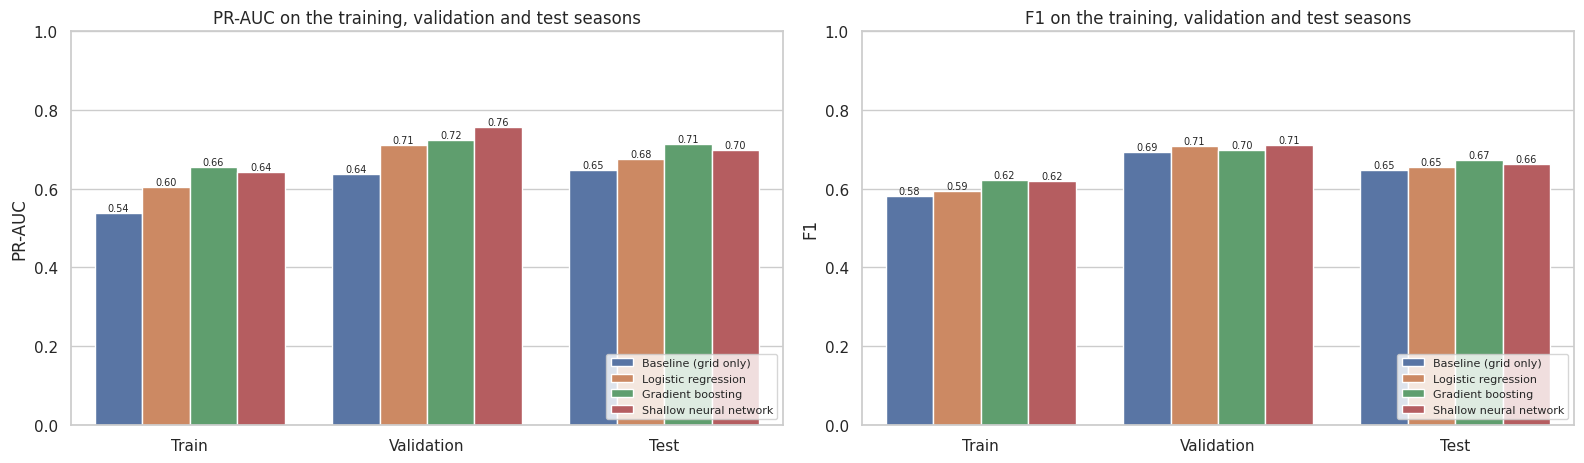

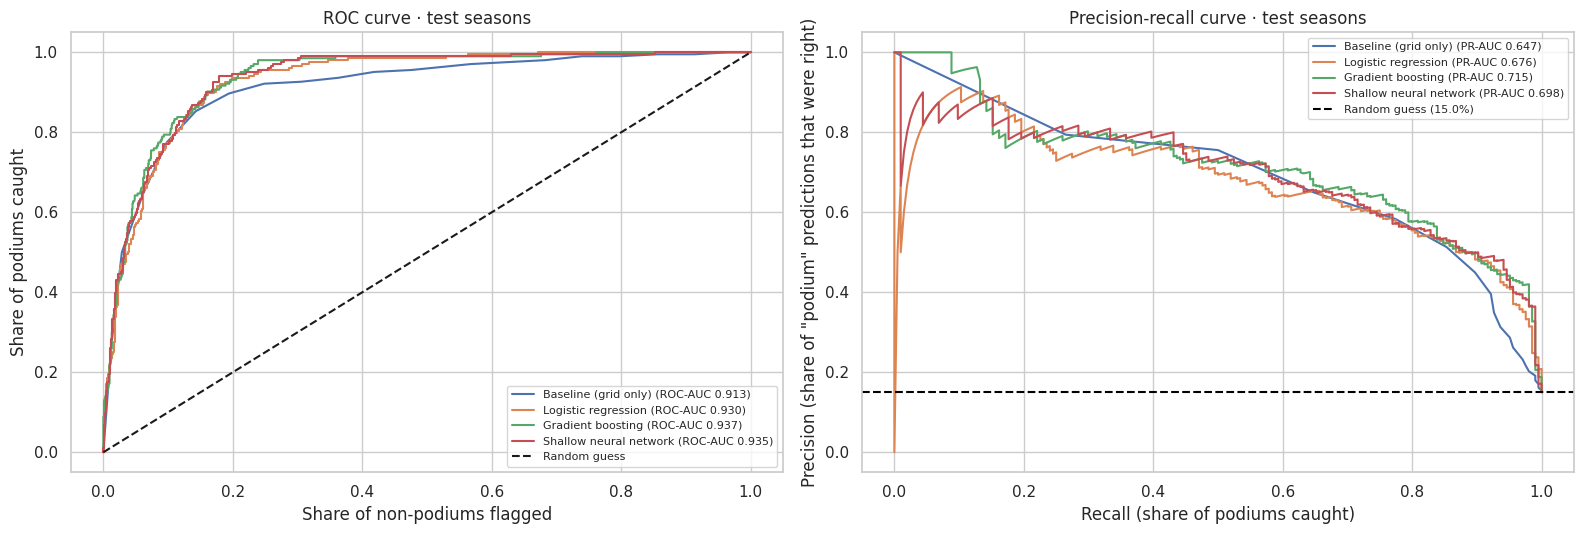

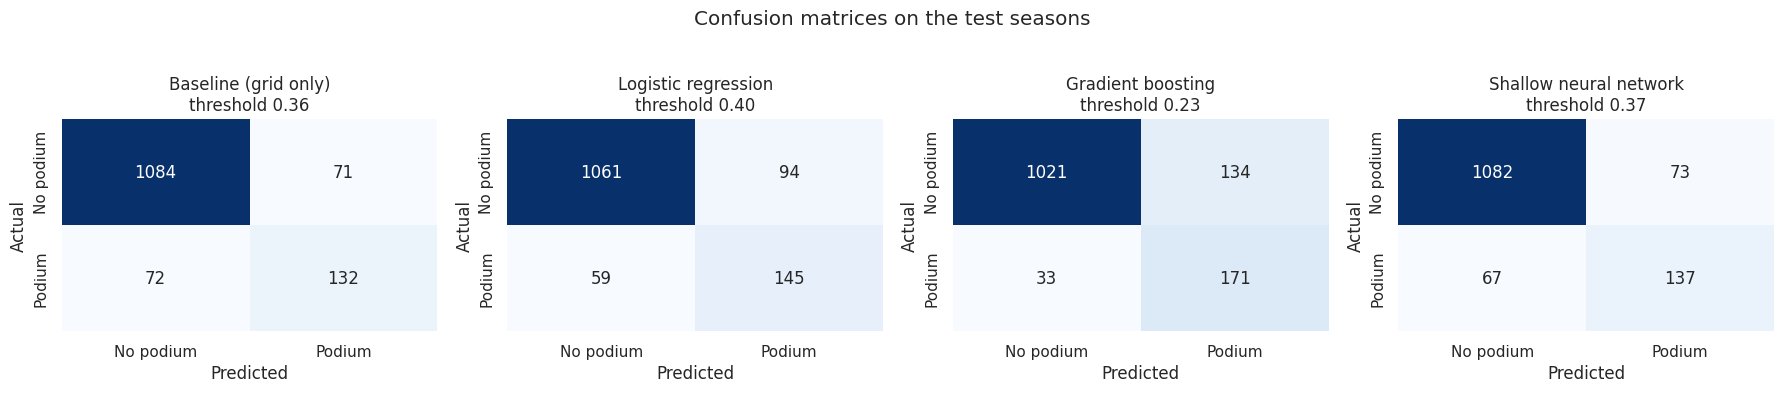

In [101]:
# 7.7 PLOTS: scores per set, curves and confusion matrices on the test seasons
model_colors = dict(zip(FINAL_MODELS, sns.color_palette('deep', len(FINAL_MODELS))))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metric in zip(axes, ['PR-AUC', 'F1']):
    sns.barplot(data=comparison, x='Set', y=metric, hue='Model', ax=ax,
                palette=model_colors)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize=7)
    ax.set(title=f'{metric} on the training, validation and test seasons', ylim=(0, 1),
           xlabel='')
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
podium_rate_test = y_test.mean()
for model in FINAL_MODELS:
    p = probabilities[(model, 'Test')]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=model_colors[model],
                 label=f'{model} (ROC-AUC {roc_auc_score(y_test, p):.3f})')
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[1].plot(recall, precision, color=model_colors[model],
                 label=f'{model} (PR-AUC {average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[1].axhline(podium_rate_test, color='black', linestyle='--',
                label=f'Random guess ({podium_rate_test:.1%})')
axes[0].set(title='ROC curve · test seasons', xlabel='Share of non-podiums flagged',
            ylabel='Share of podiums caught')
axes[1].set(title='Precision-recall curve · test seasons',
            xlabel='Recall (share of podiums caught)',
            ylabel='Precision (share of "podium" predictions that were right)')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(18, 3.8))
for ax, model in zip(axes, FINAL_MODELS):
    matrix = confusion_matrix(y_test, probabilities[(model, 'Test')] >= thresholds[model])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
    ax.set(title=f'{model}\nthreshold {thresholds[model]:.2f}', xlabel='Predicted',
           ylabel='Actual')
fig.suptitle('Confusion matrices on the test seasons', y=1.03)
plt.tight_layout()
plt.show()

**How to read these plots**

- **Bar charts:** each group of bars is one set of seasons. Compare the colours within the
  *Test* group to see which model does best on unseen seasons, and compare a model's
  *Validation* and *Test* bars to see whether it held up on newer data.
- **ROC curve:** the closer a curve gets to the top-left corner, the better. The dashed
  diagonal is random guessing.
- **Precision-recall curve:** the higher and further right, the better. The dashed line
  is the precision of random guessing (the test podium rate).
- **Confusion matrices:** the top-right cell counts false alarms (predicted podium, did not
  happen), the bottom-left cell counts missed podiums, and the diagonal counts correct
  answers, all on the test seasons at each model's validation threshold.

In [102]:
# 7.7 WRITTEN FINDINGS (generated from this run's results)
s = summary_table
baseline_test = s.loc['Baseline (grid only)', 'Test PR-AUC']
contenders = [m for m in FINAL_MODELS if m != 'Baseline (grid only)']
best_val = s.loc[contenders, 'Validation PR-AUC'].idxmax()
best_test = s.loc[contenders, 'Test PR-AUC'].idxmax()
best_test_f1 = s.loc[contenders, 'Test F1'].idxmax()
beat = [m for m in contenders if s.loc[m, 'Test PR-AUC'] > baseline_test]
lost = [m for m in contenders if s.loc[m, 'Test PR-AUC'] <= baseline_test]
drops = (s.loc[contenders, 'Validation PR-AUC'] - s.loc[contenders, 'Test PR-AUC'])
biggest_drop = drops.idxmax()

lines = [
    f"**What the comparison shows (this run)**",
    "",
    f"- **Best on validation (main measure, PR-AUC): {best_val}** "
    f"({s.loc[best_val, 'Validation PR-AUC']:.3f}).",
    f"- **Best on the unseen test seasons: {best_test}** "
    f"(PR-AUC {s.loc[best_test, 'Test PR-AUC']:.3f}); best test F1: **{best_test_f1}** "
    f"({s.loc[best_test_f1, 'Test F1']:.3f}).",
    f"- **Against the grid-only baseline** (test PR-AUC {baseline_test:.3f}): "
    + (f"{', '.join(beat)} beat it" if beat else "no model beats it")
    + (f"; {', '.join(lost)} do{'es' if len(lost) == 1 else ''} not, so for "
       f"{'it' if len(lost) == 1 else 'them'} the extra complexity is not earned."
       if lost else ", so the extra features and complexity are earned."),
    f"- **Holding up on newer seasons:** the biggest fall from validation to test is for "
    f"{biggest_drop} ({drops[biggest_drop]:.3f} PR-AUC lower on test than on validation). The test seasons "
    f"(2022 onward) are a new technical era, so some drop is expected.",
    f"- **ROC-AUC is between {s['Test ROC-AUC'].min():.2f} and {s['Test ROC-AUC'].max():.2f} "
    f"for every model, even the baseline.** Putting back-markers below front-runners is easy, "
    f"which is why PR-AUC, not ROC-AUC, is the main measure here.",
    f"- **Nothing was re-tuned after seeing these test results.** Changing a choice now would "
    f"mean tuning on the test seasons.",
]
display(Markdown('\n'.join(lines)))

**What the comparison shows (this run)**

- **Best on validation (main measure, PR-AUC): Shallow neural network** (0.756).
- **Best on the unseen test seasons: Gradient boosting** (PR-AUC 0.715); best test F1: **Gradient boosting** (0.672).
- **Against the grid-only baseline** (test PR-AUC 0.647): Logistic regression, Gradient boosting, Shallow neural network beat it, so the extra features and complexity are earned.
- **Holding up on newer seasons:** the biggest fall from validation to test is for Shallow neural network (0.059 PR-AUC lower on test than on validation). The test seasons (2022 onward) are a new technical era, so some drop is expected.
- **ROC-AUC is between 0.91 and 0.94 for every model, even the baseline.** Putting back-markers below front-runners is easy, which is why PR-AUC, not ROC-AUC, is the main measure here.
- **Nothing was re-tuned after seeing these test results.** Changing a choice now would mean tuning on the test seasons.

### 7.8 How the models work, and their limitations

**Logistic regression**
- *How it works:* gives each feature a weight, adds them up and turns the total into a
  probability with an S-shaped curve.
- *Strengths:* fast, stable and easy to explain (each weight shows the direction of the
  effect).
- *Limitations:* assumes each feature pushes the probability in one direction on its own.
  It cannot learn combinations such as "the grid matters more for strong cars" unless
  they are built in by hand.

**Gradient boosting**
- *How it works:* builds many small decision trees one after another; each new tree
  corrects the mistakes of the trees before it.
- *Strengths:* learns combinations of features and curved relationships automatically,
  and needs no scaling.
- *Limitations:* can memorise the training data; results can swing a lot with small
  changes in the data or settings (seen in 7.3); harder to explain.

**Shallow neural network**
- *How it works:* layers of neurons combine the features with learned weights, and
  training adjusts the weights to reduce the prediction error.
- *Strengths:* can learn curved relationships and combinations of features.
- *Limitations:* needs scaled inputs and careful stopping; results depend on the random
  starting weights; with only a few, already very informative features, it has little
  room to beat simpler models; hardest to explain.

**Limitations shared by all models**
- **Small validation and test sets.** Two or three seasons hold only about 40–70 races,
  so scores move by a few hundredths from luck alone (see 7.4).
- **Changes between eras.** Rules, car performance and field sizes change between eras.
  A model trained on older seasons may not match today's sport, and the test seasons
  (2022 onward) are a new technical era.
- **Missing qualifying data in older seasons.** It is filled with the median, which hides
  real differences between drivers in those years.
- **Only pre-race information.** Crashes, car failures, weather and safety cars decide
  many podiums and cannot be known before the start.
- **Exactly three podiums per race.** Each driver is scored on their own, so the
  probabilities within one race do not have to add up to 3.
- **Not cause and effect.** A feature the models rely on is not proven to *cause*
  podiums.

### 7.9 Summary of Section 7

The summary below is generated from this run's results.

In [103]:
# 7.9 SUMMARY (generated from this run)
display(Markdown('\n'.join([
    f"- **Training data:** seasons {CHOSEN_START_YEAR}–{TRAIN_END_YEAR} "
    f"({len(final_train):,} entries); validation 2020–2021 ({len(validation):,} entries); "
    f"test {TEST_START_YEAR}–{int(test.index.get_level_values('year').max())} "
    f"({len(test):,} entries).",
    f"- **Choices made on validation only:** start year {CHOSEN_START_YEAR}, {CHOSEN_TRIAL} "
    f"({len(FINAL_FEATURES)} features), preparation order {CHOSEN_ORDER}, gradient boosting "
    f"with learning rate {BEST_LEARNING_RATE} and depth {BEST_MAX_DEPTH}, neural network "
    f"version: {KEPT_NETWORK.lower()}.",
    f"- **Test PR-AUC:** " + ', '.join(
        f"{m} {summary_table.loc[m, 'Test PR-AUC']:.3f}" for m in FINAL_MODELS) + ".",
    f"- **Best model on the test seasons:** {best_test}.",
    "- **Next:** Section 8 measures which feature groups the models rely on, and Section 9 "
    "explains individual predictions.",
])))

- **Training data:** seasons 1980–2019 (16,693 entries); validation 2020–2021 (780 entries); test 2022–2024 (1,359 entries).
- **Choices made on validation only:** start year 1980, Trial 3 (10 features), preparation order impute → scale, gradient boosting with learning rate 0.05 and depth 2, neural network version: early stopping.
- **Test PR-AUC:** Baseline (grid only) 0.647, Logistic regression 0.676, Gradient boosting 0.715, Shallow neural network 0.698.
- **Best model on the test seasons:** Gradient boosting.
- **Next:** Section 8 measures which feature groups the models rely on, and Section 9 explains individual predictions.

<a id="ablation"></a>
## 8. Feature-group ablation

**What an ablation is:** one group of features is removed, the model is trained again
without it, and we measure how much worse it gets. A big drop means the model really
relies on that group. No drop means the remaining features already carry the same
information. A *negative* drop means the model did slightly better without the group.

**Uses from Section 7:** the same training rows (from `CHOSEN_START_YEAR` to 2019), the
same feature set (`FINAL_FEATURES`), the same data preparation (fill → scale) and the
same final settings: logistic regression, gradient boosting with the kept learning rate
and depth from 7.5, and the neural network with the layout and early-stopping rule kept
in 7.6. Only the removed group changes.

The feature groups:

- **Grid:** grid position.
- **Qualifying:** qualifying position and Q1 gap.
- **Driver form:** driver's past podium rate and points share.
- **Team form:** team's past podium rate and points share.
- **Circuit:** the three circuit numbers (only if the chosen feature set includes them).

Section 6 gave the reasons for choosing each feature *before* training. The ablation
measures what each group actually contributes *after* training. Decisions are based on
the **validation** drop; the test drop is shown only as a check. A group the models rely
on is not proven to *cause* podiums.

In [104]:
# 8 FEATURE-GROUP ABLATION: remove one group at a time and retrain all three models
FEATURE_GROUPS = {
    'Grid': GRID_FEATURES,
    'Qualifying': QUALIFYING_FEATURES,
    'Driver form': DRIVER_FEATURES,
    'Team form': CONSTRUCTOR_FEATURES,
    'Circuit': CIRCUIT_FEATURES,
}
FEATURE_GROUPS = {group: columns for group, columns in FEATURE_GROUPS.items()
                  if set(columns) <= set(FINAL_FEATURES)}
ABLATION_MODELS = ['Logistic regression', 'Gradient boosting', 'Shallow neural network']


def ablation_probabilities(model_name, kept):
    """Retrain one final model on the kept features; return validation and test probabilities."""
    if model_name == 'Shallow neural network':
        prep = Pipeline(preprocessing_steps(CHOSEN_ORDER)).fit(final_train[kept])
        network, _ = train_network(prep.transform(final_train[kept]), y_train,
                                   prep.transform(validation[kept]), y_val,
                                   early_stopping=NETWORK_EARLY_STOPPING)
        return (network.predict(prep.transform(validation[kept]), verbose=0).ravel(),
                network.predict(prep.transform(test[kept]), verbose=0).ravel())
    estimator = (LogisticRegression(max_iter=2000) if model_name == 'Logistic regression'
                 else GradientBoostingClassifier(
                     n_estimators=200, learning_rate=BEST_LEARNING_RATE,
                     max_depth=BEST_MAX_DEPTH, random_state=RANDOM_STATE))
    model = make_model(estimator).fit(final_train[kept], y_train)
    return (model.predict_proba(validation[kept])[:, 1],
            model.predict_proba(test[kept])[:, 1])


ablation_rows = []
for removed, columns in [('Nothing (all features)', [])] + list(FEATURE_GROUPS.items()):
    kept = [feature for feature in FINAL_FEATURES if feature not in columns]
    for model_name in ABLATION_MODELS:
        p_val, p_test = ablation_probabilities(model_name, kept)
        ablation_rows.append({
            'Removed group': removed, 'Model': model_name,
            'Validation PR-AUC': average_precision_score(y_val, p_val),
            'Test PR-AUC': average_precision_score(y_test, p_test),
        })
ablation = pd.DataFrame(ablation_rows)
full = ablation[ablation['Removed group'] == 'Nothing (all features)'].set_index('Model')
for split in ['Validation', 'Test']:
    ablation[f'{split} drop'] = (ablation['Model'].map(full[f'{split} PR-AUC'])
                                 - ablation[f'{split} PR-AUC'])
display(ablation.round(4))

Removed group,Model,Validation PR-AUC,Test PR-AUC,Validation drop,Test drop
Nothing (all features),Logistic regression,0.71,0.676,0,0
Nothing (all features),Gradient boosting,0.724,0.715,0,0
Nothing (all features),Shallow neural network,0.756,0.698,0,0
Grid,Logistic regression,0.66,0.612,0.05,0.064
Grid,Gradient boosting,0.707,0.684,0.017,0.031
Grid,Shallow neural network,0.721,0.697,0.036,0.001
Qualifying,Logistic regression,0.71,0.673,0,0.003
Qualifying,Gradient boosting,0.713,0.705,0.011,0.01
Qualifying,Shallow neural network,0.747,0.701,0.01,-0.003
Driver form,Logistic regression,0.668,0.68,0.043,-0.004


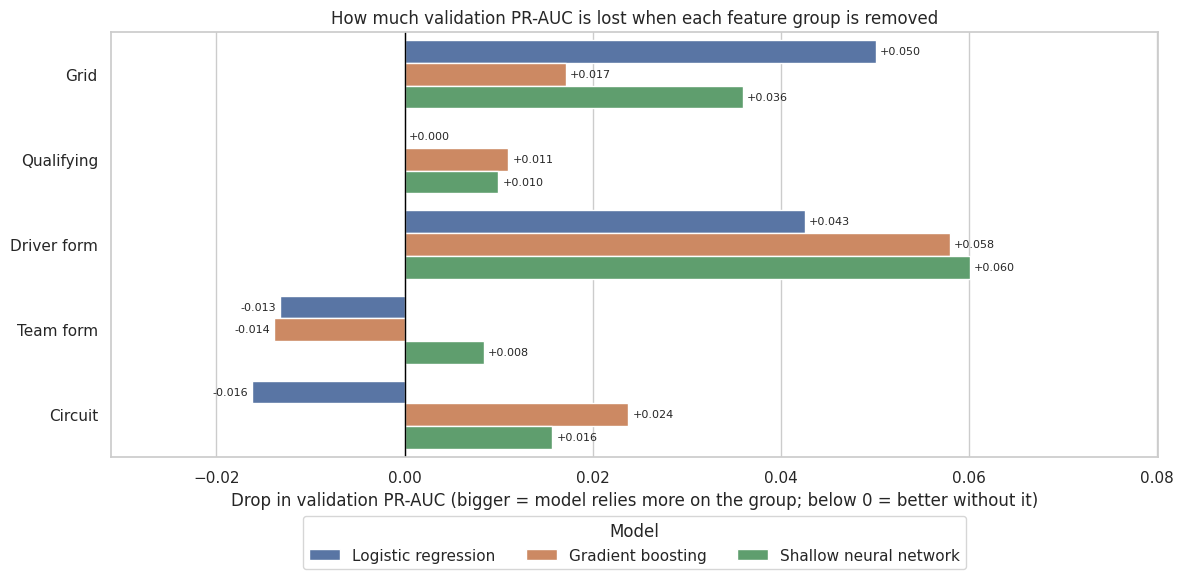

**What the ablation shows (this run, validation drops)**

- **Driver form** (average +0.054; logistic regression +0.043, gradient boosting +0.058, shallow neural network +0.060): all three models clearly rely on this group.
- **Grid** (average +0.034; logistic regression +0.050, gradient boosting +0.017, shallow neural network +0.036): all three models clearly rely on this group.
- **Circuit** (average +0.008; logistic regression -0.016, gradient boosting +0.024, shallow neural network +0.016): the models disagree: gradient boosting, shallow neural network rely on it, while logistic regression does slightly better without it.
- **Qualifying** (average +0.007; logistic regression +0.000, gradient boosting +0.011, shallow neural network +0.010): gradient boosting relies on it; little effect on the other models.
- **Team form** (average -0.006; logistic regression -0.013, gradient boosting -0.014, shallow neural network +0.008): the models do as well or slightly better without it; the other features already carry this information.

A bar of length 0 (label +0.000) means removing the group changed nothing for that model. The test drops in the table above are a check only; with about 70 test races they move more by chance.

In [105]:
# 8 PLOT: drop in validation PR-AUC per removed group (every bar is labelled, including 0)
plot_data = ablation[ablation['Removed group'] != 'Nothing (all features)']
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=plot_data, x='Validation drop', y='Removed group', hue='Model',
            hue_order=ABLATION_MODELS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%+.3f', fontsize=8, padding=3)
ax.axvline(0, color='black', linewidth=1)
low, high = plot_data['Validation drop'].min(), plot_data['Validation drop'].max()
ax.set_xlim(min(low, 0) - 0.015, high + 0.02)
ax.set(title='How much validation PR-AUC is lost when each feature group is removed',
       xlabel='Drop in validation PR-AUC (bigger = model relies more on the group; '
              'below 0 = better without it)', ylabel='')
ax.legend(title='Model', loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()

order_of_groups = (plot_data.groupby('Removed group')['Validation drop'].mean()
                   .sort_values(ascending=False))
pivot = plot_data.pivot_table(index='Removed group', columns='Model',
                              values='Validation drop').loc[order_of_groups.index]
lines = ["**What the ablation shows (this run, validation drops)**", ""]
for group, average in order_of_groups.items():
    per_model = ', '.join(f"{model.lower()} {pivot.loc[group, model]:+.3f}"
                          for model in ABLATION_MODELS)
    relies = [m for m in ABLATION_MODELS if pivot.loc[group, m] > 0.01]
    better = [m for m in ABLATION_MODELS if pivot.loc[group, m] < -0.005]
    if len(relies) == len(ABLATION_MODELS):
        verdict = 'all three models clearly rely on this group'
    elif relies and better:
        verdict = (f"the models disagree: {', '.join(m.lower() for m in relies)} "
                   f"rel{'ies' if len(relies) == 1 else 'y'} on it, while "
                   f"{', '.join(m.lower() for m in better)} "
                   f"do{'es' if len(better) == 1 else ''} slightly better without it")
    elif relies:
        verdict = (f"{', '.join(m.lower() for m in relies)} "
                   f"rel{'ies' if len(relies) == 1 else 'y'} on it; little effect on the "
                   f"other model{'s' if len(ABLATION_MODELS) - len(relies) > 1 else ''}")
    elif better:
        verdict = ('the models do as well or slightly better without it; the other features '
                   'already carry this information')
    else:
        verdict = 'practically no contribution; the other features already carry this information'
    lines.append(f"- **{group}** (average {average:+.3f}; {per_model}): {verdict}.")
lines += ["",
          "A bar of length 0 (label +0.000) means removing the group changed nothing for "
          "that model. The test drops in the table above are a check only; with about 70 "
          "test races they move more by chance."]
display(Markdown('\n'.join(lines)))

**How to read this plot**

Each group of three bars is one removed feature group, and each colour is one model.
The number at the end of each bar is the drop in validation PR-AUC. When a bar has
length 0 (label "+0.000"), removing the group made no difference for that model; the
label is still shown so no model disappears from the plot. Bars to the right of the
black line mean the model got worse without the group; bars to the left mean it got
slightly better.

<a id="xai"></a>
## 9. Explaining the models (XAI)

"XAI" (explainable AI) means showing **which features a model relies on** and **why it
gave a particular prediction**.

- **Global explanations** describe the model as a whole: which features matter most
  across many drivers. Two methods are used: **permutation importance** (9.2) and
  **SHAP** (9.3).
- **Local explanations** describe one single prediction: why *this* driver in *this* race
  got *this* probability. Two methods are used: a **SHAP waterfall** and **LIME** (9.4).

**Important: explanations are not causes.** These methods show what the model *uses* to
make its predictions. A feature being important to the model does **not** prove that it
*causes* podium finishes. For example, a high points share does not make a driver
faster; it is a sign of a strong car and driver, which the model uses as a clue.

**Uses from Section 7:** the final models exactly as trained in 7.5 and 7.6 (chosen start
year, feature set, preparation and settings). No model is retrained here. The
explanations are calculated on the **test seasons**, the data the models never saw; no
choice is made from these results.

In [106]:
# 9.0 MAKE SURE THE EXPLANATION LIBRARIES ARE AVAILABLE (installs them once if missing)
import importlib.util
import subprocess
import sys

for package in ['shap', 'lime']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import shap
from lime.lime_tabular import LimeTabularExplainer
print('shap', shap.__version__, '· lime available')

shap 0.52.0 · lime available


### 9.1 Which model is explained

Permutation importance (9.2) is calculated for all three final models, so they can be
compared. The more detailed SHAP and LIME explanations (9.3–9.4) are shown for **the
final model with the highest validation PR-AUC** in 7.7. That choice is made on the
validation seasons, like every other choice in this notebook.

In [107]:
# 9.1 CHOOSE THE MODEL TO EXPLAIN IN DETAIL (best validation PR-AUC in 7.7)
EXPLAINED_MODELS = ['Logistic regression', 'Gradient boosting', 'Shallow neural network']
EXPLAINED_MODEL = summary_table.loc[EXPLAINED_MODELS, 'Validation PR-AUC'].idxmax()
feature_names = [FEATURE_LABELS.get(f, f) for f in FINAL_FEATURES]
X_explain = test[FINAL_FEATURES]          # unseen test seasons, original (raw) values
y_explain = y_test


def predict_raw(model_name):
    """Probability function that accepts raw feature rows (DataFrame or array)."""
    def predict(rows):
        frame = pd.DataFrame(np.asarray(rows, dtype=float), columns=FINAL_FEATURES)
        return predict_probability(model_name, frame)
    return predict


print(f'Model explained in detail: {EXPLAINED_MODEL} '
      f'(validation PR-AUC {summary_table.loc[EXPLAINED_MODEL, "Validation PR-AUC"]:.3f})')

Model explained in detail: Shallow neural network (validation PR-AUC 0.756)


### 9.2 Global explanation 1: permutation importance

**How it works:** take the test seasons and **shuffle one feature's column at random**,
so that feature no longer matches its driver, while everything else stays the same.
Then measure how much the model's PR-AUC drops. If the model relies on that feature, its
predictions get worse; if not, nothing changes. Each feature is shuffled 10 times and the
drops are averaged. The black line on each bar shows how much the 10 shuffles varied.

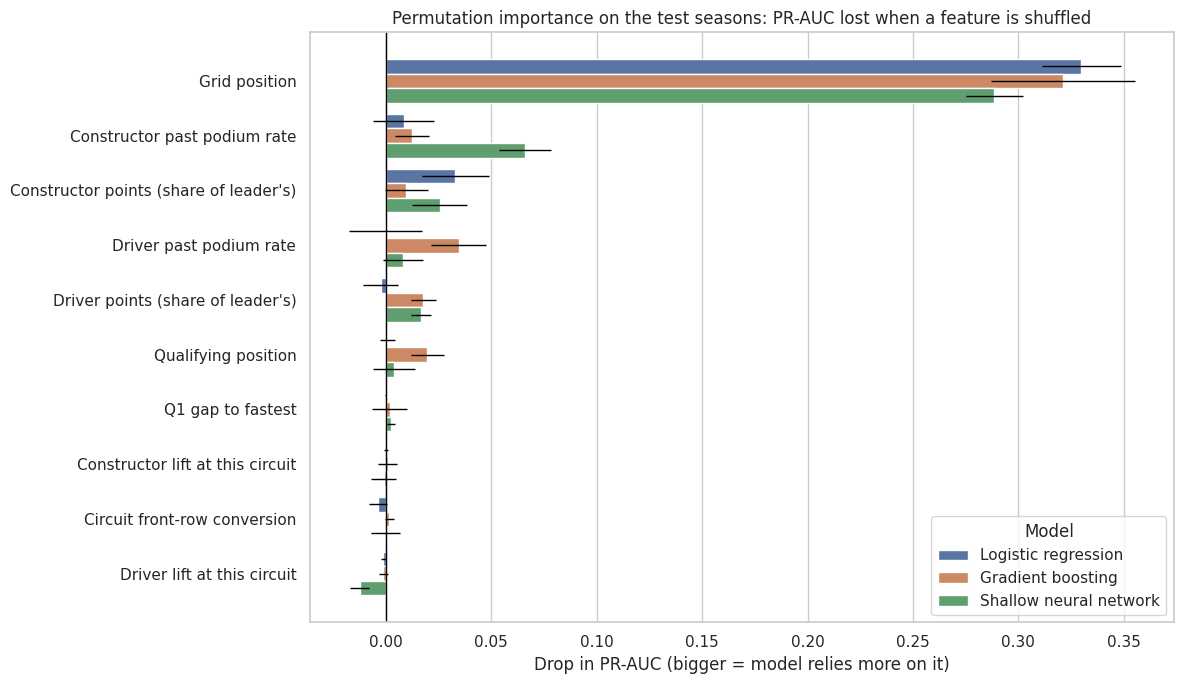

Model,Logistic regression,Gradient boosting,Shallow neural network
Feature,,,
Grid position,0.33,0.321,0.289
Constructor past podium rate,0.009,0.012,0.066
Constructor points (share of leader's),0.033,0.01,0.025
Driver past podium rate,-0,0.035,0.008
Driver points (share of leader's),-0.003,0.018,0.017
Qualifying position,0.001,0.02,0.004
Q1 gap to fastest,-0,0.002,0.003
Constructor lift at this circuit,-0,0.001,-0.001
Circuit front-row conversion,-0.004,0.002,-0


**What permutation importance shows (this run)**

- **Logistic regression:** top three features are Grid position, Constructor points (share of leader's), Constructor past podium rate.
- **Gradient boosting:** top three features are Grid position, Driver past podium rate, Qualifying position.
- **Shallow neural network:** top three features are Grid position, Constructor past podium rate, Constructor points (share of leader's).
- **Common to all three models' top three:** Grid position.
- Features near 0 can be shuffled without hurting the model: either it does not use them, or another feature carries the same information (for example grid and qualifying position move together very strongly, so shuffling only one of them costs little).

In [108]:
# 9.2 PERMUTATION IMPORTANCE on the test seasons, for all three final models
PERMUTATION_REPEATS = 10
rng = np.random.default_rng(RANDOM_STATE)
importance_rows = []
for model_name in EXPLAINED_MODELS:
    predict = predict_raw(model_name)
    base_score = average_precision_score(y_explain, predict(X_explain))
    for feature, label in zip(FINAL_FEATURES, feature_names):
        drops = []
        for _ in range(PERMUTATION_REPEATS):
            shuffled = X_explain.copy()
            shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
            drops.append(base_score - average_precision_score(y_explain, predict(shuffled)))
        importance_rows.append({'Model': model_name, 'Feature': label,
                                'Importance (PR-AUC drop)': np.mean(drops),
                                'Spread': np.std(drops)})
permutation_importance = pd.DataFrame(importance_rows)

feature_order = (permutation_importance.groupby('Feature')['Importance (PR-AUC drop)']
                 .mean().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=permutation_importance, y='Feature', x='Importance (PR-AUC drop)',
            hue='Model', order=feature_order, hue_order=EXPLAINED_MODELS, ax=ax,
            errorbar=None)
for bars, model_name in zip(ax.containers, EXPLAINED_MODELS):
    spread = (permutation_importance[permutation_importance['Model'] == model_name]
              .set_index('Feature').loc[feature_order, 'Spread'])
    centres = [bar.get_y() + bar.get_height() / 2 for bar in bars]
    widths = [bar.get_width() for bar in bars]
    ax.errorbar(widths, centres, xerr=spread.to_numpy(), fmt='none', ecolor='black',
                elinewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Permutation importance on the test seasons: PR-AUC lost when a feature '
             'is shuffled', xlabel='Drop in PR-AUC (bigger = model relies more on it)',
       ylabel='')
ax.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.show()

display(permutation_importance.pivot_table(index='Feature', columns='Model',
                                           values='Importance (PR-AUC drop)')
        .loc[feature_order, EXPLAINED_MODELS].round(4))

top = {m: (permutation_importance[permutation_importance['Model'] == m]
           .nlargest(3, 'Importance (PR-AUC drop)')['Feature'].tolist())
       for m in EXPLAINED_MODELS}
shared = set.intersection(*(set(v) for v in top.values()))
display(Markdown('\n'.join(
    ["**What permutation importance shows (this run)**", ""]
    + [f"- **{m}:** top three features are {', '.join(top[m])}." for m in EXPLAINED_MODELS]
    + [f"- **Common to all three models' top three:** "
       f"{', '.join(sorted(shared)) if shared else 'none'}.",
       "- Features near 0 can be shuffled without hurting the model: either it does not "
       "use them, or another feature carries the same information (for example grid and "
       "qualifying position move together very strongly, so shuffling only one of them "
       "costs little)."])))

### 9.3 Global explanation 2: SHAP

**How it works:** SHAP splits each prediction into **contributions from each feature**.
It starts from the model's average prediction and asks, for every feature, "how much did
this feature's value push *this* driver's probability up or down?". The contributions
always add up exactly to the model's prediction for that driver. SHAP values here are in
probability units: +0.10 means the feature raised the podium probability by 10
percentage points for that driver.

For a global picture, SHAP is calculated for 300 randomly chosen test entries, compared
against 100 randomly chosen training entries as the "average driver".

- **Bar chart:** the average size of each feature's contribution, ignoring direction.
  Longer bars mean more influence overall.
- **Dot chart ("beeswarm"):** one dot per driver per feature. Dots to the right raised the
  probability, dots to the left lowered it. **Red** dots are drivers with a **high** value
  of that feature, **blue** dots a **low** value. For example, if blue grid dots sit on the
  right, a low grid number (near the front) raises the probability.

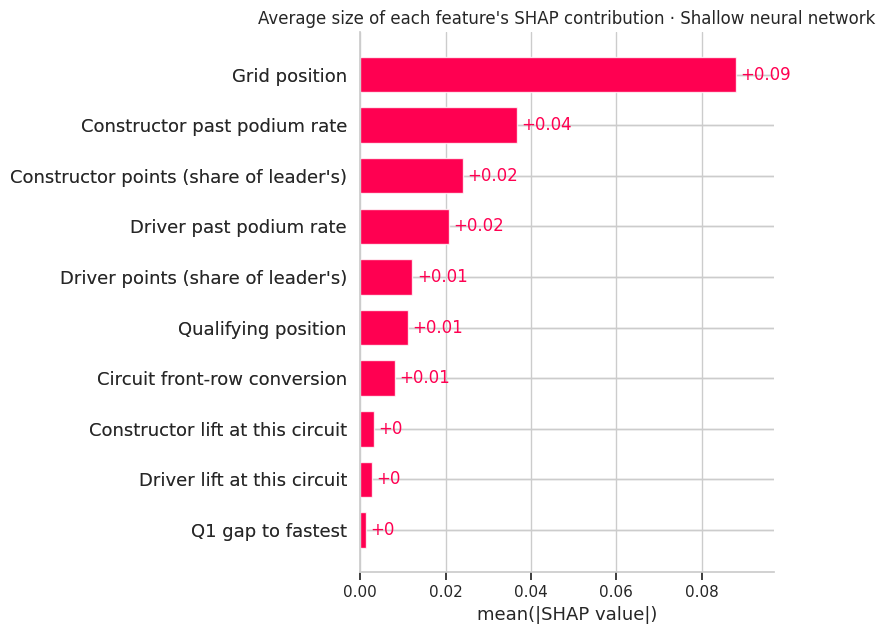

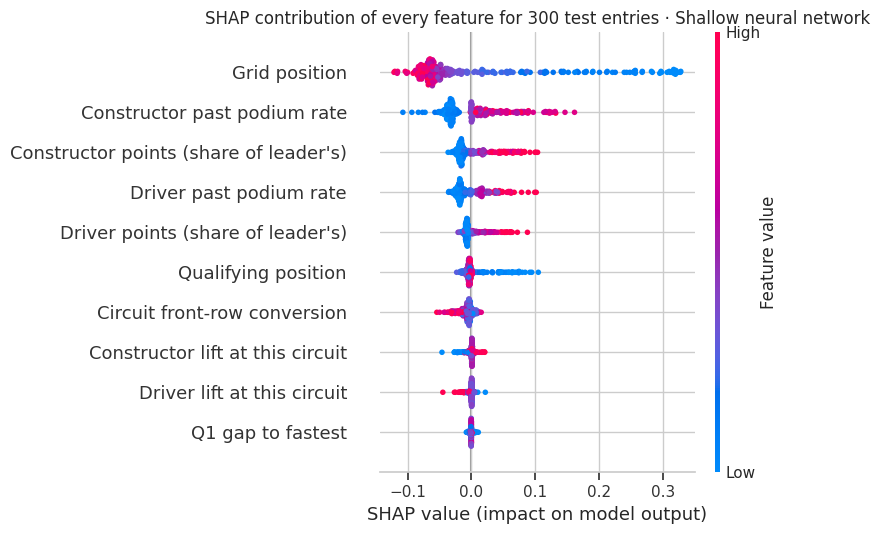

,Average |SHAP| (probability)
Grid position,0.088
Constructor past podium rate,0.037
Constructor points (share of leader's),0.024
Driver past podium rate,0.021
Driver points (share of leader's),0.012
Qualifying position,0.011
Circuit front-row conversion,0.008
Constructor lift at this circuit,0.003
Driver lift at this circuit,0.003
Q1 gap to fastest,0.001


**What SHAP shows for the shallow neural network (this run)**

- **Grid position** (average contribution ±0.088): lower values raise the probability.
- **Constructor past podium rate** (average contribution ±0.037): higher values raise the probability.
- **Constructor points (share of leader's)** (average contribution ±0.024): higher values raise the probability.
- **Driver past podium rate** (average contribution ±0.021): higher values raise the probability.
- The remaining features each move the probability by less than ±0.012 on average.
- **Agreement with permutation importance:** the top feature by SHAP is Grid position; the top feature by permutation importance for this model is Grid position. The two methods measure different things (contribution to each prediction vs. damage to accuracy when shuffled), so their order can differ when features overlap.

In [109]:
# 9.3 SHAP: global view of the model explained in detail
background = final_train[FINAL_FEATURES].sample(100, random_state=RANDOM_STATE).to_numpy()
explain_rows = X_explain.sample(300, random_state=RANDOM_STATE)
shap_explainer = shap.Explainer(predict_raw(EXPLAINED_MODEL),
                                shap.maskers.Independent(background, max_samples=100),
                                feature_names=feature_names, seed=RANDOM_STATE)
shap_values = shap_explainer(explain_rows.to_numpy(), silent=True)  # arrays keep the readable labels

plt.figure()
shap.plots.bar(shap_values, max_display=len(FINAL_FEATURES), show=False)
plt.title(f'Average size of each feature\'s SHAP contribution · {EXPLAINED_MODEL}')
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.beeswarm(shap_values, max_display=len(FINAL_FEATURES), show=False)
plt.title(f'SHAP contribution of every feature for 300 test entries · {EXPLAINED_MODEL}')
plt.tight_layout()
plt.show()

mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0),
                     index=feature_names).sort_values(ascending=False)
display(mean_abs.rename('Average |SHAP| (probability)').round(4).to_frame())


def direction(label):
    """Does a high value of this feature tend to raise (+) or lower (-) the prediction?"""
    column = feature_names.index(label)
    values = pd.Series(explain_rows.iloc[:, column].to_numpy())
    contributions = pd.Series(shap_values.values[:, column])
    valid = values.notna()
    correlation = values[valid].rank().corr(contributions[valid].rank())
    if pd.isna(correlation) or abs(correlation) < 0.2:
        return 'no single clear direction'
    return 'higher values raise the probability' if correlation > 0 else \
        'lower values raise the probability'


display(Markdown('\n'.join(
    [f"**What SHAP shows for the {EXPLAINED_MODEL.lower()} (this run)**", ""]
    + [f"- **{label}** (average contribution ±{mean_abs[label]:.3f}): {direction(label)}."
       for label in mean_abs.index[:4]]
    + [f"- The remaining features each move the probability by less than "
       f"±{mean_abs.iloc[4]:.3f} on average.",
       f"- **Agreement with permutation importance:** the top feature by SHAP is "
       f"{mean_abs.index[0]}; the top feature by permutation importance for this model is "
       f"{top[EXPLAINED_MODEL][0]}. The two methods measure different things (contribution "
       f"to each prediction vs. damage to accuracy when shuffled), so their order can "
       f"differ when features overlap."])))

### 9.4 Local explanations: why did the model give this prediction?

Two test entries are explained, both chosen automatically from the model's predictions:

- **Case A, a clear call:** the actual podium finisher to whom the model gave the
  **highest** probability.
- **Case B, a surprise:** the actual podium finisher to whom the model gave the **lowest**
  probability, a podium the model did not see coming.

Each case is explained in two ways:

- **SHAP waterfall:** starts at the model's average prediction (bottom, `E[f(X)]`) and
  adds each feature's push, red for up and blue for down, until it reaches this driver's
  prediction (top, `f(x)`). The grey numbers next to the feature names are the driver's
  actual values.
- **LIME:** creates thousands of slightly changed copies of this driver's row, sees how
  the model's prediction changes, and fits a simple, easy-to-read model that copies the
  real model **near this one driver**. Green bars pushed the prediction towards "podium",
  red bars away from it. LIME reads values from the data as it was before scaling, with
  gaps filled by the training median.

In [110]:
# 9.4 PICK THE TWO CASES AND DESCRIBE THEM
explained_probability = predict_raw(EXPLAINED_MODEL)(X_explain)
cases = pd.DataFrame({'probability': explained_probability, 'podium': y_explain.to_numpy()},
                     index=X_explain.index)
podium_cases = cases[cases['podium'] == 1]
CASE_A = podium_cases['probability'].idxmax()
CASE_B = podium_cases['probability'].idxmin()

driver_name = (drivers.set_index('driverId')['forename'] + ' '
               + drivers.set_index('driverId')['surname'])
race_name = races.set_index('raceId')['name']


def describe(case):
    race_id, driver_id, year = case
    row = test.loc[case]
    return {'Driver': driver_name.get(driver_id, driver_id),
            'Race': f'{year} {race_name.get(race_id, race_id)}',
            'Grid': 'pit lane / missing' if pd.isna(row['grid']) else int(row['grid']),
            'Predicted podium probability': round(float(cases.loc[case, 'probability']), 3),
            'Actually finished on the podium': 'Yes'}


display(pd.DataFrame({'Case A (clear call)': describe(CASE_A),
                      'Case B (surprise)': describe(CASE_B)}).T)

,Driver,Race,Grid,Predicted podium probability,Actually finished on the podium
Case A (clear call),Max Verstappen,2024 Bahrain Grand Prix,1,0.902,Yes
Case B (surprise),Pierre Gasly,2024 São Paulo Grand Prix,13,0.001,Yes


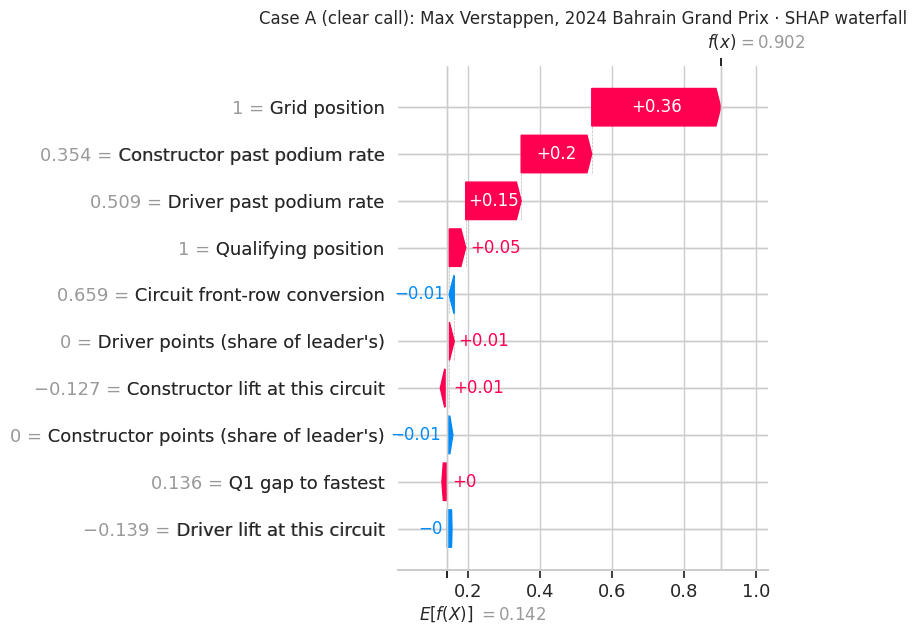

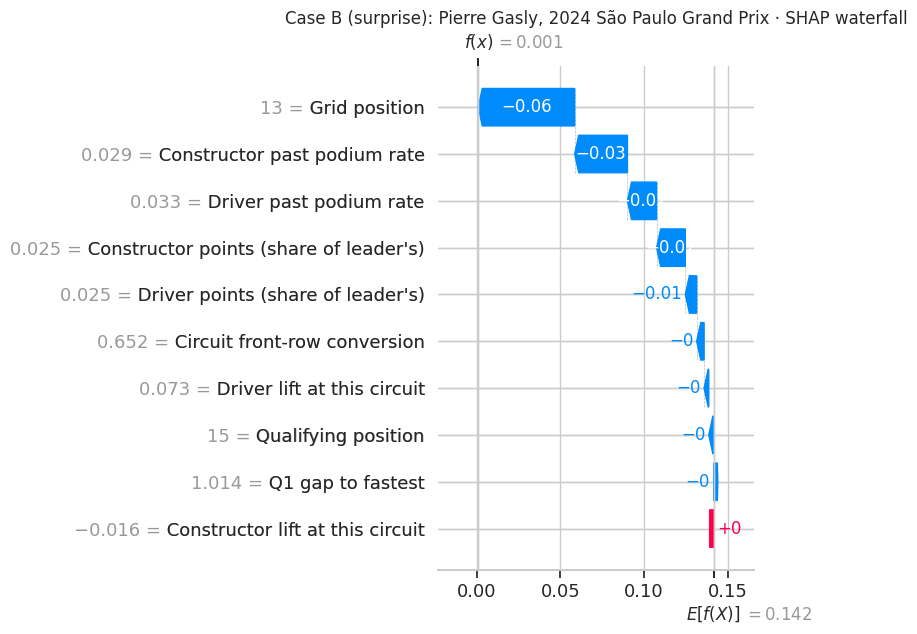

In [111]:
# 9.4 SHAP WATERFALLS FOR THE TWO CASES
case_explanations = shap_explainer(X_explain.loc[[CASE_A, CASE_B]].to_numpy(), silent=True)
for position, (title, case) in enumerate([('Case A (clear call)', CASE_A),
                                          ('Case B (surprise)', CASE_B)]):
    info = describe(case)
    plt.figure()
    shap.plots.waterfall(case_explanations[position], max_display=len(FINAL_FEATURES),
                         show=False)
    plt.title(f"{title}: {info['Driver']}, {info['Race']} · SHAP waterfall")
    plt.tight_layout()
    plt.show()

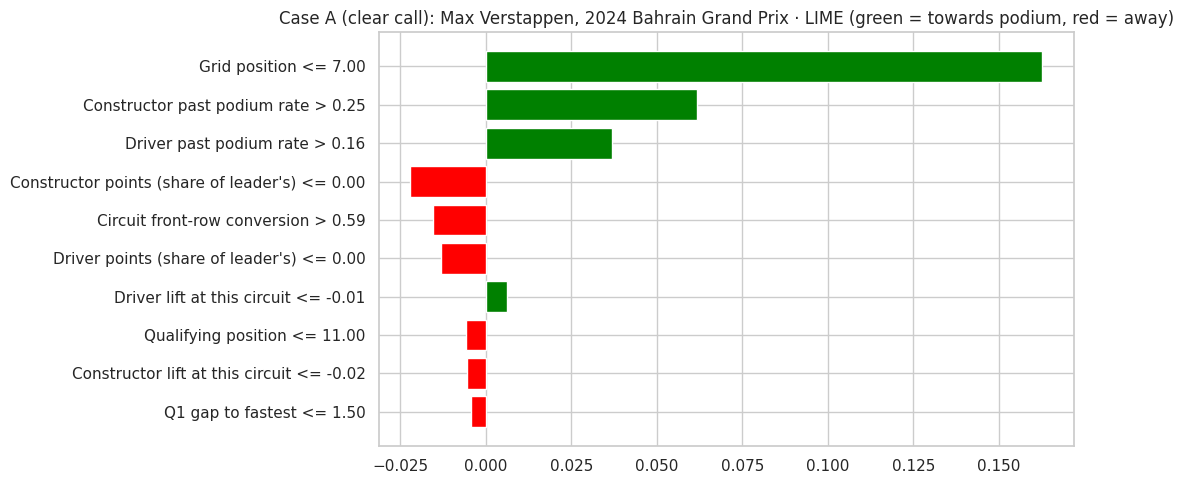

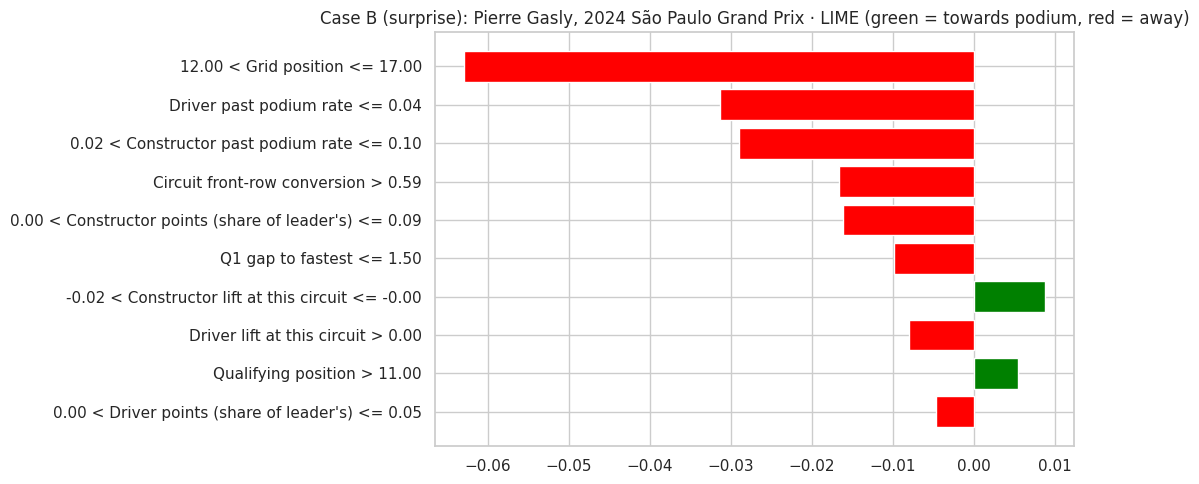

In [112]:
# 9.4 LIME FOR THE SAME TWO CASES
train_median = final_train[FINAL_FEATURES].median()
lime_training = final_train[FINAL_FEATURES].fillna(train_median).to_numpy()
lime_explainer = LimeTabularExplainer(
    lime_training, feature_names=feature_names, class_names=['No podium', 'Podium'],
    mode='classification', discretize_continuous=True, random_state=RANDOM_STATE)


def lime_predict(rows):
    probability = predict_raw(EXPLAINED_MODEL)(rows)
    return np.column_stack([1 - probability, probability])


lime_results = {}
for title, case in [('Case A (clear call)', CASE_A), ('Case B (surprise)', CASE_B)]:
    row = X_explain.loc[case].fillna(train_median).to_numpy()
    explanation = lime_explainer.explain_instance(row, lime_predict,
                                                  num_features=len(FINAL_FEATURES))
    lime_results[title] = explanation
    info = describe(case)
    figure = explanation.as_pyplot_figure(label=1)
    figure.set_size_inches(11, 5)
    plt.title(f"{title}: {info['Driver']}, {info['Race']} · LIME "
              f"(green = towards podium, red = away)")
    plt.tight_layout()
    plt.show()

In [113]:
# 9.4 WRITTEN READING OF THE TWO CASES (generated from this run)
def strongest(explanation_row, sign, count=2):
    pushes = pd.Series(explanation_row.values, index=feature_names)
    chosen = pushes[pushes > 0] if sign > 0 else pushes[pushes < 0]
    chosen = chosen.abs().sort_values(ascending=False).head(count)
    return ', '.join(f"{name} ({pushes[name]:+.3f})" for name in chosen.index)


lines = ["**What the local explanations show (this run)**", ""]
for position, (title, case) in enumerate([('Case A (clear call)', CASE_A),
                                          ('Case B (surprise)', CASE_B)]):
    info = describe(case)
    lime_top = lime_results[title].as_list(label=1)[:2]
    lines += [
        f"- **{title}: {info['Driver']}, {info['Race']}** (grid {info['Grid']}, predicted "
        f"probability {info['Predicted podium probability']:.3f}). SHAP: "
        + (f"the strongest pushes **up** came from {up}" if (up := strongest(
            case_explanations[position], +1)) else "no feature pushed the probability up")
        + (f"; the strongest pushes **down** came from {down}" if (down := strongest(
            case_explanations[position], -1)) else "; no feature pushed it down")
        + ". LIME's two strongest rules: " + '; '.join(f"`{rule}` ({weight:+.3f})" for rule, weight in lime_top) + "."]
lines += ["",
          "Case B shows a limitation from 7.8: the model only knows the situation before the "
          "start. Podiums that come from retirements ahead, safety cars, weather or strategy "
          "cannot be foreseen from these features.",
          "",
          "SHAP and LIME answer the same question in different ways (exact contributions "
          "vs. a simple model fitted around one driver), so their numbers differ. Where they "
          "agree on the main features, the explanation is more trustworthy."]
display(Markdown('\n'.join(lines)))

**What the local explanations show (this run)**

- **Case A (clear call): Max Verstappen, 2024 Bahrain Grand Prix** (grid 1, predicted probability 0.902). SHAP: the strongest pushes **up** came from Grid position (+0.359), Constructor past podium rate (+0.196); the strongest pushes **down** came from Circuit front-row conversion (-0.014), Constructor points (share of leader's) (-0.008). LIME's two strongest rules: `Grid position <= 7.00` (+0.163); `Constructor past podium rate > 0.25` (+0.062).
- **Case B (surprise): Pierre Gasly, 2024 São Paulo Grand Prix** (grid 13, predicted probability 0.001). SHAP: the strongest pushes **up** came from Constructor lift at this circuit (+0.000); the strongest pushes **down** came from Grid position (-0.058), Constructor past podium rate (-0.032). LIME's two strongest rules: `12.00 < Grid position <= 17.00` (-0.063); `Driver past podium rate <= 0.04` (-0.031).

Case B shows a limitation from 7.8: the model only knows the situation before the start. Podiums that come from retirements ahead, safety cars, weather or strategy cannot be foreseen from these features.

SHAP and LIME answer the same question in different ways (exact contributions vs. a simple model fitted around one driver), so their numbers differ. Where they agree on the main features, the explanation is more trustworthy.

### 9.5 Summary of the explanations

- **Global:** permutation importance (all three models) and SHAP (the model with the best
  validation PR-AUC) show which features the models lean on across the test seasons. The
  written findings under each plot are generated from this run.
- **Local:** the SHAP waterfalls and LIME charts show, for one confident correct prediction
  and one missed podium, which feature values pushed the probability up or down.
- **Consistency with Section 8:** the ablation removes whole feature groups and retrains,
  while these methods probe the trained models without retraining. Features that matter
  in both are the most reliable signals.
- **Not cause and effect:** all of these explanations describe **what the models use**,
  not what makes a driver finish on the podium. A feature can be important simply because
  it moves together with real causes (car speed, driver skill) that are not measured
  directly.

<a id="inference"></a>
## 10. Inference function: predicting a new race

`predict_podium(record)` is the function you would use to make a prediction for a driver
before a real race. You give it the driver's pre-race information, and it returns the
podium probability and a yes/no answer.

**Uses from Section 7:**
- the **final model with the best validation PR-AUC** (7.7);
- **its data preparation** (fill gaps with the training median, then scale), fitted on the
  training seasons;
- **its yes/no threshold**, chosen on the validation seasons.

Nothing is retrained here.

**How it works:**
1. It takes a dictionary with any of the model's features. Unknown feature names cause a
   clear error, so typos are caught.
2. Any feature that is missing (or `None`) is left blank and then **filled with the
   training-season median** by the model's own preparation step, the same way missing
   values were handled during training. A grid value of 0 (pit-lane start) is treated as
   missing, as in 7.1.
3. It returns the podium probability, the yes/no prediction (probability ≥ threshold), the
   threshold used, and **which features had to be filled in**, so the user knows how
   complete the input was.

**Two demonstrations** on a real entry from the test seasons:
- **Complete record:** every feature is known.
- **Partly missing record:** the same entry with qualifying position and Q1 gap removed,
  as if qualifying data were unavailable. The function still works; the probability
  changes because the model now has to rely on the median instead of the real
  qualifying result.

In [114]:
# 10 INFERENCE FUNCTION: predict the podium chance for one driver before a race
INFERENCE_MODEL = summary_table.loc[
    ['Logistic regression', 'Gradient boosting', 'Shallow neural network'],
    'Validation PR-AUC'].idxmax()          # best final model on validation (Section 7.7)


def predict_podium(record, model_name=INFERENCE_MODEL):
    """Predict the podium probability for one driver-race from pre-race information.

    record: dict with any of the features in FINAL_FEATURES. Missing features (or None)
            are filled with the training-season median by the model's own preparation
            step, exactly as during training.
    Returns a dict with the probability, the yes/no prediction (using the model's
    validation threshold from 7.7) and which features had to be filled in.
    """
    unknown = set(record) - set(FINAL_FEATURES)
    if unknown:
        raise ValueError(f'Unknown feature(s): {sorted(unknown)}. '
                         f'Expected some of: {FINAL_FEATURES}')
    row = pd.DataFrame([{feature: record.get(feature, np.nan) for feature in FINAL_FEATURES}],
                       dtype=float)
    if row.loc[0, 'grid'] == 0:          # pit-lane start: no numbered slot, as in 7.1
        row.loc[0, 'grid'] = np.nan
    probability = float(predict_probability(model_name, row)[0])
    return {
        'Model': model_name,
        'Podium probability': round(probability, 3),
        'Predicted podium': probability >= thresholds[model_name],
        'Threshold': thresholds[model_name],
        'Filled in (missing)': ', '.join(FEATURE_LABELS.get(f, f) for f in FINAL_FEATURES
                                         if pd.isna(row.loc[0, f])) or 'none',
    }


# Demonstration 1: a complete record (a real test-season entry, all features known)
example_key = X_test.dropna().index[0]
complete_record = X_test.loc[example_key].to_dict()

# Demonstration 2: the same driver with qualifying information missing
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ['qualifying_position', 'q1_gap_percentage']}

race_id, driver_id, year = example_key
print(f"Example entry: {driver_name.get(driver_id, driver_id)}, {year} "
      f"{race_name.get(race_id, race_id)} · actually finished on the podium: "
      f"{'Yes' if y_test.loc[example_key] == 1 else 'No'}")
display(pd.DataFrame({'Complete record': complete_record,
                      'Partly missing record': partial_record}).rename(index=FEATURE_LABELS))
display(pd.DataFrame([predict_podium(complete_record), predict_podium(partial_record)],
                     index=['Complete record', 'Partly missing record']))

Example entry: Charles Leclerc, 2022 Bahrain Grand Prix · actually finished on the podium: Yes


,Complete record,Partly missing record
Grid position,1,1
Qualifying position,1,—
Q1 gap to fastest,0,—
Driver past podium rate,0.157,0.157
Driver points (share of leader's),0,0
Constructor past podium rate,0.345,0.345
Constructor points (share of leader's),0,0
Circuit front-row conversion,0.65,0.65
Driver lift at this circuit,0.022,0.022
Constructor lift at this circuit,0.039,0.039


,Model,Podium probability,Predicted podium,Threshold,Filled in (missing)
Complete record,Shallow neural network,0.715,Yes,0.37,none
Partly missing record,Shallow neural network,0.43,Yes,0.37,"Qualifying position, Q1 gap to fastest"
